In [2]:
#=====================================================================
#ячейка 0 – окружение, параметры проекта и общие функции
#запускать первой и после каждого перезапуска среды выполнения
#данные и результаты сохраняются на Google Drive в папке venus_snow
#параметры менять только в CFG
#=====================================================================
import os, re, sys, json, time, math, warnings, subprocess
from pathlib import Path


def _ensure(module, pip_name=None):  #установить пакет при его отсутствии в среде
    try:
        __import__(module)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=False)


for _m in ("lightgbm", "joblib", "tqdm"):
    _ensure(_m)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LightSource
from scipy.ndimage import distance_transform_edt
import joblib

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

USE_DRIVE = True
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/venus_snow")
elif IN_COLAB:
    ROOT = Path("/content/venus_snow")
else:
    ROOT = Path("venus_snow").resolve()

DATA_DIR = ROOT / "raw"
WORK_DIR = ROOT / "work"
FIG_DIR = ROOT / "figures"
OUT_DIR = ROOT / "results"
for _d in (DATA_DIR, WORK_DIR, FIG_DIR, OUT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

CFG = {
    "base_url": "https://pds-geosciences.wustl.edu/mgn/urn-nasa-pds-magellan_gxdr/data/sinusoidal/",
    "venus_radius_m": 6_051_000.0,
    "grid_res_deg": 0.1,
    "seed": 42,
    "lowland_max_elev_km": 1.0,
    "regional_window_km": 300,
    "n_fit": 30_000,
    "n_eval": 8_000,
    "n_small": 6_000,
    "highland_share": 0.25,
    "k_range": list(range(3, 9)),
    "hdbscan_min_sizes": [60, 150, 300],
    "check_stability": True,
    "metric_weights": {"silhouette": 0.30, "calinski_harabasz": 0.20,
                       "davies_bouldin": 0.20, "stability_ari": 0.30},
    #порог снега: аномалия излучательной способности < -snow_k_mad*mad (медианное абсолютное отклонение)
    "snow_k_mad": 4.0,
    "snow_min_elev_km": 2.0,
    #порог не снега: аномалия > -neg_k_mad*mad
    "neg_k_mad": 1.0,
    "max_pos": 40_000,
    "neg_ratio": 4,
    "cv_folds": 5,
    "tile_deg": 30,
    "use_abs_lat": False,
    "predict_batch": 500_000,
}

#физическое значение = stored*scale + offset, stored = 0 – нет данных
PRODUCTS = {
    "topo":  {"prefix": "gtdr_",  "scale": 1.0,   "offset": 6_039_999.0, "title": "gtdr – рельеф",
              "plaus": (6.040e6, 6.070e6)},
    "emis":  {"prefix": "gedr_",  "scale": 1e-4,  "offset": -1e-4,  "title": "gedr – излучательная способность",
              "plaus": (0.5, 1.0)},
    "refl":  {"prefix": "gredr_", "scale": 0.005, "offset": -0.005, "title": "gredr – отражательная способность",
              "plaus": (0.02, 0.5)},
    "slope": {"prefix": "gsdr_",  "scale": 0.1,   "offset": -0.1,   "title": "gsdr – rms-уклон",
              "plaus": (0.2, 15.0)},
}

FEATURE_INFO = {
    "elev_km":      ("высота над r=6051 км", "км", "gist_earth"),
    "emis":         ("излучательная способность", "", "magma"),
    "emis_anom":    ("аномалия излучательной способности", "", "RdBu"),
    "refl_norm":    ("отражательная способность (норм.)", "", "cividis"),
    "log_refl":     ("log₁₀ отражательной способности", "", "cividis"),
    "eps_refl":     ("диэлектрическая проницаемость ε", "", "inferno"),
    "slope":        ("rms-уклон", "°", "viridis"),
    "log_slope":    ("log₁₀ rms-уклона", "", "viridis"),
    "relief_km":    ("локальный рельеф", "км", "BrBG_r"),
    "roughness_km": ("шероховатость рельефа", "км", "plasma"),
    "abs_lat":      ("абсолютная широта", "°", "Greys"),
}

CLUSTER_FEATURES = ["elev_km", "emis_anom", "log_refl", "log_slope", "relief_km", "roughness_km"]
#излучательная способность исключена: по ней строятся метки снега
SNOW_FEATURES = ["elev_km", "relief_km", "log_refl", "log_slope", "roughness_km"]
if CFG["use_abs_lat"]:
    SNOW_FEATURES.append("abs_lat")
ANOMALY_FEATURES = ["elev_km", "emis_anom", "log_refl", "log_slope", "relief_km"]

#долгота от -180 до 180, восточная положительная
REGIONS = {
    "Горы Максвелла":      {"lat": (60, 70),  "lon": (-8, 14)},
    "Область Овда":        {"lat": (-15, 5),  "lon": (60, 110)},
    "Область Тетис":       {"lat": (-20, 0),  "lon": (110, 150)},
    "Область Бета":        {"lat": (15, 35),  "lon": (-90, -65)},
    "Область Атла (Маат)": {"lat": (-5, 20),  "lon": (-172, -150)},
    "Гора Гула":           {"lat": (15, 30),  "lon": (-8, 5)},
}

CLUSTER_COLORS = ["#2b6cb0", "#38a169", "#d69e2e", "#805ad5", "#e53e3e",
                  "#319795", "#dd6b20", "#718096", "#b83280", "#1a202c"]
MODEL_COLORS = plt.cm.tab10.colors
EXTENT = [-180, 180, -90, 90]
R_KM = CFG["venus_radius_m"] / 1000.0

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.facecolor": "white",
})


def savefig(fig, name):  #сохранить график в FIG_DIR и показать
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    plt.close(fig)


def print_header(text):  #вывести заголовок блока
    print("\n" + "=" * 70 + f"\n  {text}\n" + "=" * 70)


class Timer:  #замерить время выполнения блока
    def __init__(self, label):  #сохранить подпись блока
        self.label = label

    def __enter__(self):  #зафиксировать время начала
        self.t0 = time.time()
        return self

    def __exit__(self, *exc):  #вывести длительность блока
        self.dt = time.time() - self.t0
        print(f"   {self.label}: {self.dt:.1f} с")


def save_npz(name, **arrays):  #сохранить массивы в WORK_DIR
    np.savez(WORK_DIR / f"{name}.npz", **arrays)


def load_npz(name):  #загрузить массивы из WORK_DIR
    path = WORK_DIR / f"{name}.npz"
    if not path.exists():
        raise FileNotFoundError(f"файл {name}.npz не найден")
    with np.load(path, allow_pickle=False) as z:
        return {k: z[k] for k in z.files}


def latlon_axes(res):  #вычислить центры пикселей: широта сверху вниз, долгота слева направо
    lat = 90.0 - (np.arange(int(round(180 / res))) + 0.5) * res
    lon = -180.0 + (np.arange(int(round(360 / res))) + 0.5) * res
    return lat, lon


def pixel_area_km2(lat, res):  #вычислить площадь пикселя по широте, км^2
    side = R_KM * np.deg2rad(res)
    return (side * side * np.cos(np.deg2rad(lat)))[:, None]


def region_mask(lat, lon, box):  #построить маску региона
    la = (lat >= box["lat"][0]) & (lat <= box["lat"][1])
    lo = (lon >= box["lon"][0]) & (lon <= box["lon"][1])
    return la[:, None] & lo[None, :]


def region_slices(lat, lon, box):  #получить срезы строк и столбцов региона
    rows = np.where((lat >= box["lat"][0]) & (lat <= box["lat"][1]))[0]
    cols = np.where((lon >= box["lon"][0]) & (lon <= box["lon"][1]))[0]
    return slice(rows.min(), rows.max() + 1), slice(cols.min(), cols.max() + 1)


def fill_nan_nearest(a):  #заполнить nan (нечисловые значения) ближайшими значениями
    mask = ~np.isfinite(a)
    if not mask.any():
        return a
    idx = distance_transform_edt(mask, return_distances=False, return_indices=True)
    return a[tuple(idx)]


def hillshade(elev_km, res, exag=25.0):  #построить теневой рельеф с освещением с северо-запада
    dx = R_KM * np.deg2rad(res)
    return LightSource(azdeg=315, altdeg=40).hillshade(fill_nan_nearest(elev_km), vert_exag=exag, dx=dx, dy=dx)


def style_map(ax, title=None, extent=EXTENT):  #оформить оси глобальной карты
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_xlabel("долгота, ° в.д.")
    ax.set_ylabel("широта, °")
    if title:
        ax.set_title(title)
    ax.grid(color="white", alpha=0.25, lw=0.5)


def robust_limits(a, lo=1, hi=99):  #вычислить границы цветовой шкалы по перцентилям
    v = a[np.isfinite(a)]
    return (np.percentile(v, lo), np.percentile(v, hi)) if v.size else (0, 1)


class Preprocessor:  #обрезать выбросы по перцентилям и стандартизовать признаки
    def __init__(self, lo=0.5, hi=99.5):  #задать перцентили обрезки
        self.lo, self.hi = lo, hi

    def fit(self, X):  #вычислить границы обрезки, среднее и стандартное отклонение
        self.low_ = np.percentile(X, self.lo, axis=0)
        self.high_ = np.percentile(X, self.hi, axis=0)
        Xc = np.clip(X, self.low_, self.high_)
        self.mean_, self.std_ = Xc.mean(0), Xc.std(0) + 1e-9
        return self

    def transform(self, X):  #обрезать и стандартизовать признаки
        return ((np.clip(X, self.low_, self.high_) - self.mean_) / self.std_).astype(np.float32)

    def fit_transform(self, X):  #вычислить параметры и преобразовать признаки
        return self.fit(X).transform(X)


def stack_features(F, names, mask):  #собрать матрицу признаков по маске
    return np.column_stack([F[n][mask] for n in names]).astype(np.float32)


def predict_in_batches(fn, X, batch=None):  #выполнить предсказание частями
    batch = batch or CFG["predict_batch"]
    return np.concatenate([fn(X[i:i + batch]) for i in range(0, len(X), batch)])


print(f"окружение готово. Colab: {str(IN_COLAB).lower()}. папка проекта: {ROOT.name}")
print(f"   сетка: {CFG['grid_res_deg']}° – {int(180 / CFG['grid_res_deg'])} * {int(360 / CFG['grid_res_deg'])} пикселей")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
окружение готово. Colab: true. папка проекта: venus_snow
   сетка: 0.1° – 1800 * 3600 пикселей


In [3]:
#=====================================================================
#ячейка 1 – загрузка карт Magellan GxDR (глобальные записи данных миссии Магеллан)
#с сервера NASA PDS (система планетных данных НАСА)
#загружаются 4 глобальные карты в синусоидальной проекции, около 200 мб:
#GTDR (глобальная запись рельефа) – радиус планеты, 16 бит
#GEDR (глобальная запись излучательной способности) – микроволновая излучательная способность, 16 бит
#GREDR (глобальная запись отражательной способности) – отражательная способность Френеля, 8 бит
#GSDR (глобальная запись уклонов) – rms-уклон (среднеквадратичный уклон), 8 бит
#запускать после ячейки 0
#файлы кешируются в DATA_DIR, повторный запуск не загружает данные заново
#=====================================================================
import requests
from tqdm.auto import tqdm


def local_product_names():  #найти уже загруженные пары .img и .hdr
    found = {}
    for key, p in PRODUCTS.items():
        for img in sorted(DATA_DIR.glob(f"{p['prefix']}*.img")):
            if "error" in img.stem.lower():
                continue
            if (DATA_DIR / f"{img.stem}.hdr").exists():
                found[key] = img.stem
                break
    return found


def remote_listing(url):  #получить список файлов каталога на сервере
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    hrefs = re.findall(r'href="([^"]+)"', r.text, flags=re.I)
    return sorted({h.rstrip("/").split("/")[-1] for h in hrefs})


def remote_product_names():  #найти имена файлов продуктов на сервере, при ошибке проверить типовые имена
    try:
        names = remote_listing(CFG["base_url"])
        print(f"   файлов в каталоге на сервере: {len(names)}")
    except Exception as e:
        print(f"   листинг каталога недоступен ({str(e).lower()}), проверка типовых имен")
        names = []
    found = {}
    for key, p in PRODUCTS.items():
        cands = [n[:-4] for n in names
                 if n.lower().startswith(p["prefix"]) and n.lower().endswith(".img") and "error" not in n.lower()]
        if cands:
            found[key] = cands[0]
            continue
        for suffix in ("sinu", "sinus", "sin"):
            stem = p["prefix"] + suffix
            try:
                if requests.head(CFG["base_url"] + stem + ".img", timeout=30).status_code == 200:
                    found[key] = stem
                    break
            except requests.RequestException:
                pass
    return found


def download(url, dst, required=True, retries=3):  #загрузить файл с повторными попытками
    if dst.exists() and dst.stat().st_size > 0:
        print(f"   уже загружен: {dst.name}")
        return True
    tmp = dst.with_name(dst.name + ".part")
    for attempt in range(1, retries + 1):
        try:
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                total = int(r.headers.get("content-length", 0))
                with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=dst.name) as bar:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        f.write(chunk)
                        bar.update(len(chunk))
            tmp.rename(dst)
            return True
        except Exception as e:
            print(f"   {dst.name}: попытка {attempt}/{retries} не удалась ({str(e).lower()})")
            time.sleep(3 * attempt)
    if required:
        raise RuntimeError(f"не удалось загрузить {url}")
    return False


print_header("ячейка 1. загрузка Magellan GxDR")
names = local_product_names()
if len(names) < len(PRODUCTS):
    remote = remote_product_names()
    missing = [k for k in PRODUCTS if k not in remote]
    if missing:
        raise RuntimeError(f"на сервере не найдены продукты: {missing}")
    for key, stem in remote.items():
        for ext in (".img", ".hdr", ".xml"):
            download(CFG["base_url"] + stem + ext, DATA_DIR / (stem + ext), required=(ext != ".xml"))
    names = local_product_names()
else:
    print("   все файлы загружены ранее, сеть не используется")

(WORK_DIR / "files.json").write_text(json.dumps(names, ensure_ascii=False, indent=2))

summary = pd.DataFrame([{
    "продукт": PRODUCTS[k]["title"],
    "файл": f"{stem}.img",
    "размер, мб": round((DATA_DIR / f"{stem}.img").stat().st_size / 2**20, 1),
} for k, stem in names.items()])
display(summary)
print(f"   итого: {summary['размер, мб'].sum():.0f} мб в папке {DATA_DIR.name}")


  ячейка 1. загрузка Magellan GxDR
   все файлы загружены ранее, сеть не используется


,продукт,файл,"размер, мб"
0,gtdr – рельеф,gtdr_sinus.img,64.0
1,gedr – излучательная способность,gedr_sinus.img,64.0
2,gredr – отражательная способность,gredr_sinus.img,32.0
3,gsdr – rms-уклон,gsdr_sinus.img,32.0


   итого: 192 мб в папке raw



  ячейка 2. декодирование и перепроекция
   map info: Venus Sinusoidal,4097.0000,2049.0000,0.0000,0.0000,
4641.0589,4641.0589,Venus custermerD,units=Meters
   исходник (4096, 8192), покрытие 62.0% (вне проекции около 36% – нормативное значение), диапазон -2.993 – 11.58
   topo (gtdr_sinus): 8.1 с
   map info: Venus Sinusoidal,4097.0000,2049.0000,0.0000,0.0000,
4641.0589,4641.0589,Venus custermerD,units=Meters
   исходник (4096, 8192), покрытие 61.6% (вне проекции около 36% – нормативное значение), диапазон 0.2925 – 0.9986
   emis (gedr_sinus): 7.0 с
   map info: Venus Sinusoidal,4097.0000,2049.0000,0.0000,0.0000,
4641.0589,4641.0589,Venus custermerD,units=Meters
   исходник (4096, 8192), покрытие 60.6% (вне проекции около 36% – нормативное значение), диапазон 0.005 – 0.98
   refl (gredr_sinus): 7.1 с
   map info: Venus Sinusoidal,4097.0000,2049.0000,0.0000,0.0000,
4641.0589,4641.0589,Venus custermerD,units=Meters
   исходник (4096, 8192), покрытие 61.8% (вне проекции около 36% – норма

,слой,"покрытие площади, %",медиана,p1,p99
0,elev_km,97.33,0.5815,-0.7040,4.4718
1,emis,96.65,0.8518,0.6995,0.9059
2,refl,95.13,0.1213,0.0587,0.3688
3,slope,97.03,2.6500,0.8000,8.1750


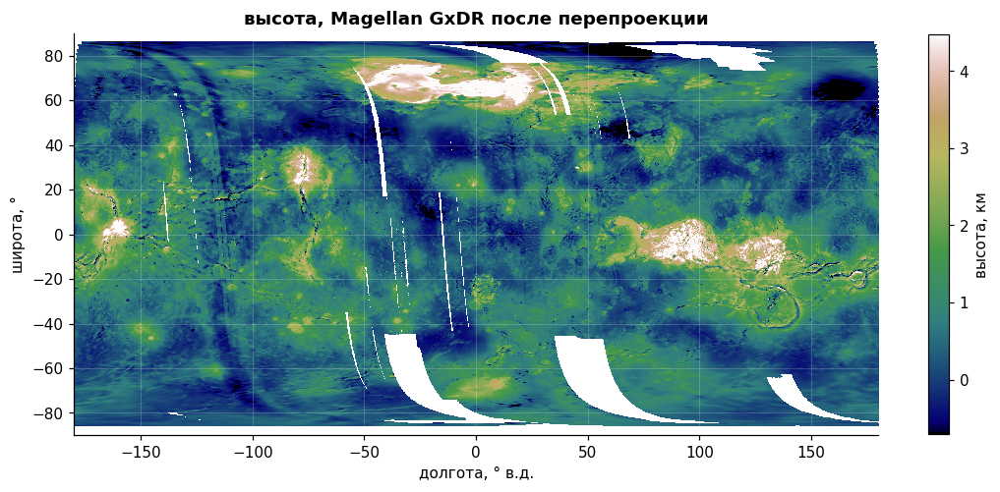

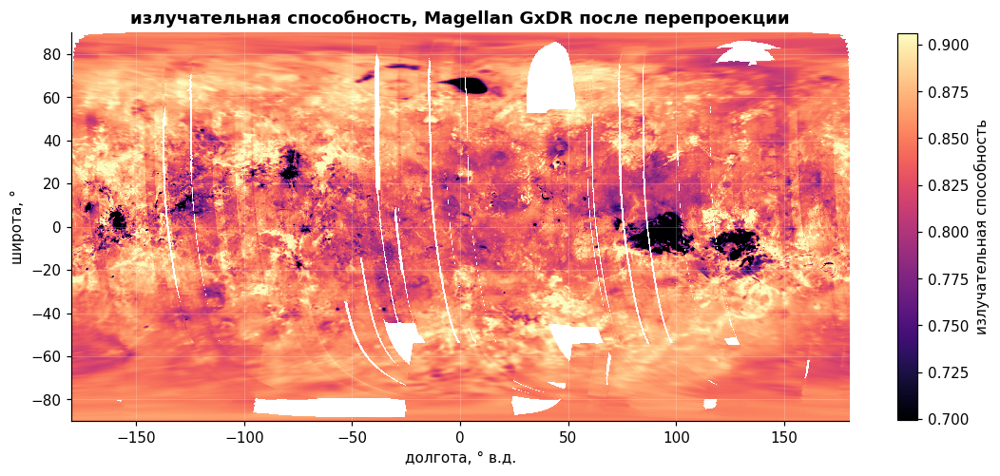

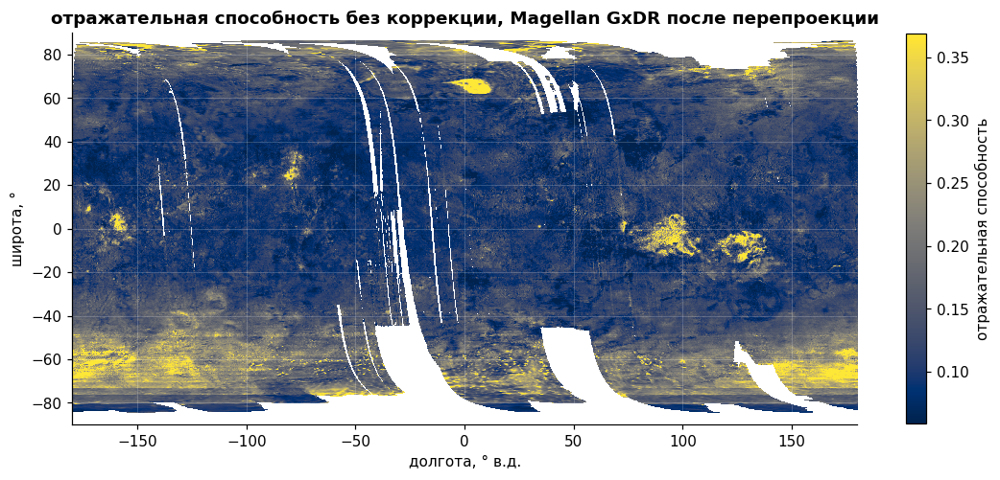

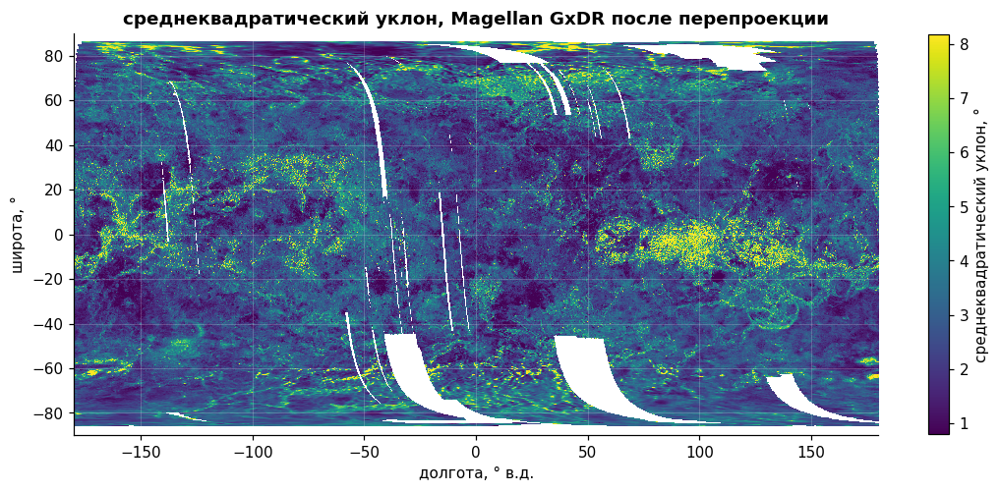

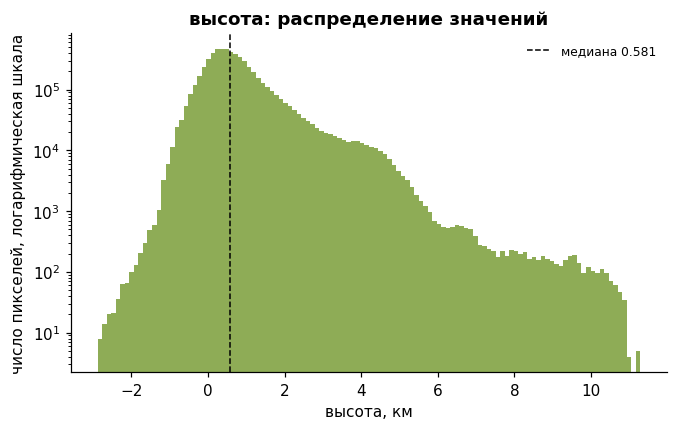

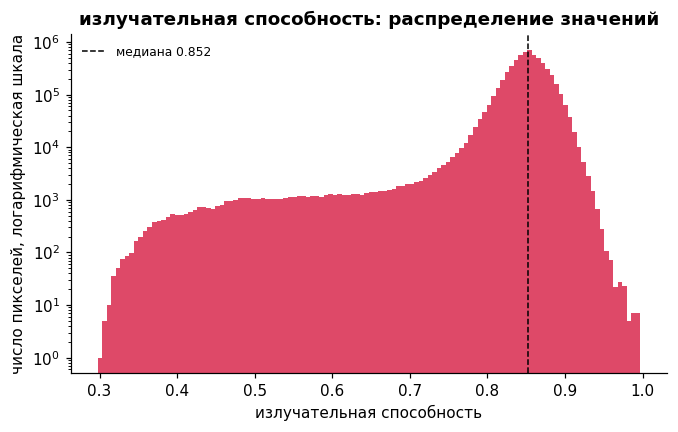

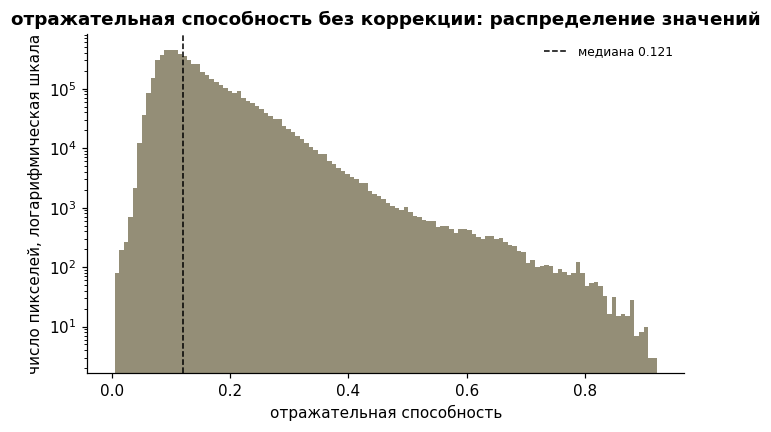

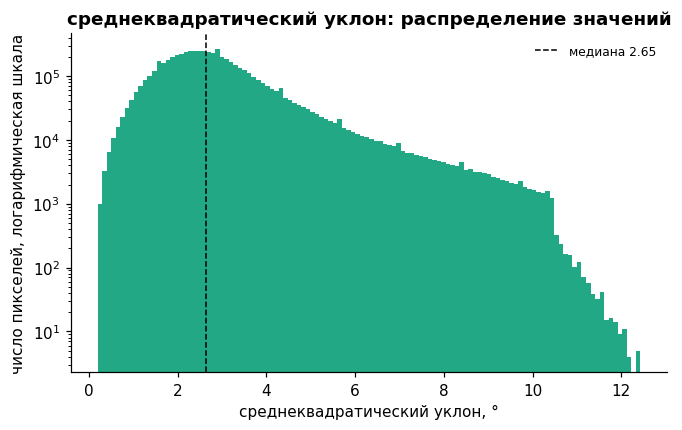

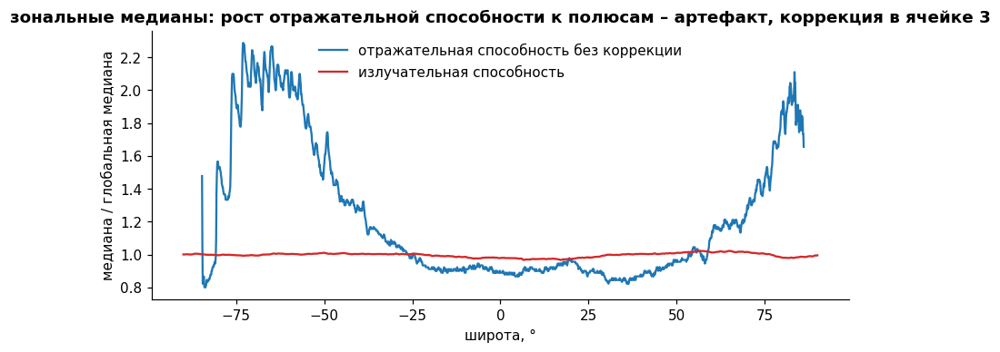

ячейка 2 завершена: сетки сохранены в work/grids.npz


In [4]:
#=====================================================================
#ячейка 2 – чтение Magellan GxDR (глобальные записи данных миссии Магеллан),
#перевод в физические единицы и перепроекция из синусоидальной проекции
#на регулярную сетку широты и долготы
#запускать после ячейки 1
#результат: work/grids.npz и отдельные картинки 02_*.png в папке figures
#контроль геопривязки: высшая точка планеты должна попасть на горы Максвелла
#=====================================================================
from scipy.ndimage import uniform_filter

ENVI_DTYPES = {1: np.uint8, 2: np.int16, 3: np.int32, 4: np.float32,
               5: np.float64, 12: np.uint16, 13: np.uint32}


def parse_envi_hdr(path):  #разобрать заголовок ENVI (среда визуализации изображений)
    text = Path(path).read_text(errors="ignore")
    hdr = {}
    for m in re.finditer(r"^\s*([A-Za-z][^=\n]*?)\s*=\s*(\{.*?\}|[^\n]*)", text, flags=re.M | re.S):
        hdr[m.group(1).strip().lower()] = m.group(2).strip().strip("{}").strip()
    return hdr


def read_product(key, stem):  #прочитать массив и перевести в физические единицы
    p = PRODUCTS[key]
    hdr = parse_envi_hdr(DATA_DIR / f"{stem}.hdr")
    L, S = int(hdr["lines"]), int(hdr["samples"])
    dtype = np.dtype(ENVI_DTYPES[int(hdr.get("data type", 12))])
    offset = int(hdr.get("header offset", 0))
    bo_hdr = int(hdr.get("byte order", 0))
    orders = [bo_hdr, 1 - bo_hdr] if dtype.itemsize > 1 else [bo_hdr]

    #порядок байтов подтверждается правдоподобием медианы в физических единицах
    for bo in orders:
        dt = dtype.newbyteorder("<" if bo == 0 else ">")
        stored = np.fromfile(DATA_DIR / f"{stem}.img", dtype=dt, count=L * S, offset=offset).reshape(L, S)
        sub = stored[::7, ::7].astype(np.float64)
        sub = sub[sub > 0] * p["scale"] + p["offset"]
        med = float(np.median(sub)) if sub.size else np.nan
        if p["plaus"][0] <= med <= p["plaus"][1]:
            break
        print(f"   {key}: медиана {med:.4g} неправдоподобна при порядке байтов {bo}, проверка альтернативного порядка")
    else:
        print(f"   {key}: ни один порядок байтов не дал правдоподобных значений, требуется проверка файла")

    valid = stored > 0
    phys = np.full((L, S), np.nan, dtype=np.float32)
    if key == "topo":
        phys[valid] = ((stored[valid].astype(np.float64) * p["scale"] + p["offset"]
                        - CFG["venus_radius_m"]) / 1000.0).astype(np.float32)
    else:
        phys[valid] = (stored[valid].astype(np.float64) * p["scale"] + p["offset"]).astype(np.float32)
    return phys, hdr


def nan_box_smooth(img, k):  #сгладить окном k*k с учетом пропущенных значений
    if k <= 1:
        return img
    m = np.isfinite(img).astype(np.float32)
    v = np.where(m > 0, img, 0).astype(np.float32)
    num, den = uniform_filter(v, k), uniform_filter(m, k)
    return np.where(den > 0.5, num / np.maximum(den, 1e-6), np.nan).astype(np.float32)


def sinusoidal_to_latlon(img, res):  #перепроецировать синусоидальную сетку на сетку широты и долготы
    L, S = img.shape
    R = CFG["venus_radius_m"]
    pix_m = 2 * np.pi * R / S
    dlat_src = 180.0 / L
    img = nan_box_smooth(img, max(1, int(round(res / dlat_src))))
    lat, lon = latlon_axes(res)
    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    row = np.floor((90.0 - LAT) / dlat_src).astype(np.int64)
    x_m = np.deg2rad(LON) * R * np.cos(np.deg2rad(LAT))
    col = np.floor(x_m / pix_m + S / 2).astype(np.int64)
    ok = (row >= 0) & (row < L) & (col >= 0) & (col < S)
    out = np.full(LAT.shape, np.nan, dtype=np.float32)
    out[ok] = img[row[ok], col[ok]]
    return out


print_header("ячейка 2. декодирование и перепроекция")
files = json.loads((WORK_DIR / "files.json").read_text())
res = CFG["grid_res_deg"]
lat, lon = latlon_axes(res)
GRIDS = {}
NAMES = {"topo": "elev_km", "emis": "emis", "refl": "refl", "slope": "slope"}

for key, stem in files.items():
    with Timer(f"{key} ({stem})"):
        phys, hdr = read_product(key, stem)
        if "map info" in hdr:
            print(f"   map info: {hdr['map info'][:110]}")
        GRIDS[NAMES[key]] = sinusoidal_to_latlon(phys, res)
        v = phys[np.isfinite(phys)]
        print(f"   исходник {phys.shape}, покрытие {100 * v.size / phys.size:.1f}% "
              f"(вне проекции около 36% – нормативное значение), диапазон {v.min():.4g} – {v.max():.4g}")
        del phys

#высшая точка Венеры – горы Максвелла, около 65° с.ш. и 3° в.д.
e = GRIDS["elev_km"]
i, j = np.unravel_index(np.nanargmax(e), e.shape)
print(f"\n   высшая точка сетки: {e[i, j]:.2f} км, широта {lat[i]:.1f}°, долгота {lon[j]:.1f}°")
if 58 < lat[i] < 72 and -12 < lon[j] < -1:
    print("   максимум гор Максвелла расположен западнее нулевого меридиана, изменение направления оси долготы")
    for k in GRIDS:
        GRIDS[k] = GRIDS[k][:, ::-1].copy()
elif 58 < lat[i] < 72 and -1 <= lon[j] <= 12:
    print("   геопривязка подтверждена: максимум соответствует району гор Максвелла")
else:
    print("   максимум расположен вне района гор Максвелла, требуется проверка проекции в map info файла hdr")

save_npz("grids", lat=lat, lon=lon, **GRIDS)

area = pixel_area_km2(lat, res) * np.ones((1, lon.size))
cov = pd.DataFrame([{
    "слой": k,
    "покрытие площади, %": round(100 * area[np.isfinite(v)].sum() / area.sum(), 2),
    "медиана": float(np.nanmedian(v)),
    "p1": float(np.nanpercentile(v, 1)),
    "p99": float(np.nanpercentile(v, 99)),
} for k, v in GRIDS.items()])
display(cov.round(4))

TITLES = {
    "elev_km": ("высота", "высота, км", "gist_earth"),
    "emis": ("излучательная способность", "излучательная способность", "magma"),
    "refl": ("отражательная способность без коррекции", "отражательная способность", "cividis"),
    "slope": ("среднеквадратический уклон", "среднеквадратический уклон, °", "viridis"),
}

for k, (title, unit, cmap) in TITLES.items():
    vmin, vmax = robust_limits(GRIDS[k])
    fig, ax = plt.subplots(figsize=(12, 6))
    im = ax.imshow(GRIDS[k], extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    style_map(ax, f"{title}, Magellan GxDR после перепроекции")
    fig.colorbar(im, ax=ax, shrink=0.8, label=unit)
    savefig(fig, f"02_map_{k}")

for k, (title, unit, cmap) in TITLES.items():
    v = GRIDS[k][np.isfinite(GRIDS[k])]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(v, bins=120, color=plt.get_cmap(cmap)(0.6), log=True)
    ax.axvline(np.median(v), color="k", ls="--", lw=1, label=f"медиана {np.median(v):.3g}")
    ax.set_xlabel(unit)
    ax.set_ylabel("число пикселей, логарифмическая шкала")
    ax.set_title(f"{title}: распределение значений")
    ax.legend(fontsize=8)
    savefig(fig, f"02_hist_{k}")

fig, ax = plt.subplots(figsize=(9, 3.5))
for k, c in (("refl", "tab:blue"), ("emis", "tab:red")):
    zm = np.nanmedian(GRIDS[k], axis=1)
    ax.plot(lat, zm / np.nanmedian(zm), color=c, label=TITLES[k][0])
ax.set_xlabel("широта, °")
ax.set_ylabel("медиана / глобальная медиана")
ax.set_title("зональные медианы: рост отражательной способности к полюсам – артефакт, коррекция в ячейке 3")
ax.legend()
savefig(fig, "02_latitude_bias")

print("ячейка 2 завершена: сетки сохранены в work/grids.npz")


  ячейка 3. радиофизические признаки и разведочный анализ
   пикселей со всеми 4 слоями: 5,477,306 (84.5% сетки)
   нормировки и производные признаки: 1.3 с


,описание,count,mean,std,min,1%,50%,99%,max
elev_km,высота над r=6051 км,5477306.0,0.8009,0.9798,-2.8760,-0.7010,0.5947,4.4938,11.2855
emis,излучательная способность,5477306.0,0.8475,0.0444,0.2977,0.6777,0.8518,0.9068,0.9971
emis_anom,аномалия излучательной способности,5477306.0,-0.0017,0.0397,-0.5371,-0.1614,0.0014,0.0626,0.1574
refl_norm,отражательная способность (норм.),5477306.0,0.1304,0.0454,0.0060,0.0632,0.1239,0.3052,1.1656
log_refl,log₁₀ отражательной способности,5477306.0,-0.9039,0.1244,-2.2253,-1.1992,-0.9069,-0.5154,0.0665
eps_refl,диэлектрическая проницаемость ε,5477306.0,4.7637,5.4396,1.3624,2.7948,4.3535,12.0320,1441.9971
slope,rms-уклон,5477306.0,2.8749,1.3560,0.2000,0.8000,2.6250,8.1250,12.4250
log_slope,log₁₀ rms-уклона,5477306.0,0.4339,0.1840,-0.5229,-0.0458,0.4354,0.9151,1.0978
relief_km,локальный рельеф,5477306.0,-0.0002,0.2727,-5.1799,-0.8348,-0.0117,0.8251,4.9614
roughness_km,шероховатость рельефа,5477306.0,0.0731,0.1069,0.0000,0.0052,0.0394,0.5342,3.1447


   медиана диэлектрической проницаемости низменностей: 4.38 (для сухих базальтов обычно 4–6)


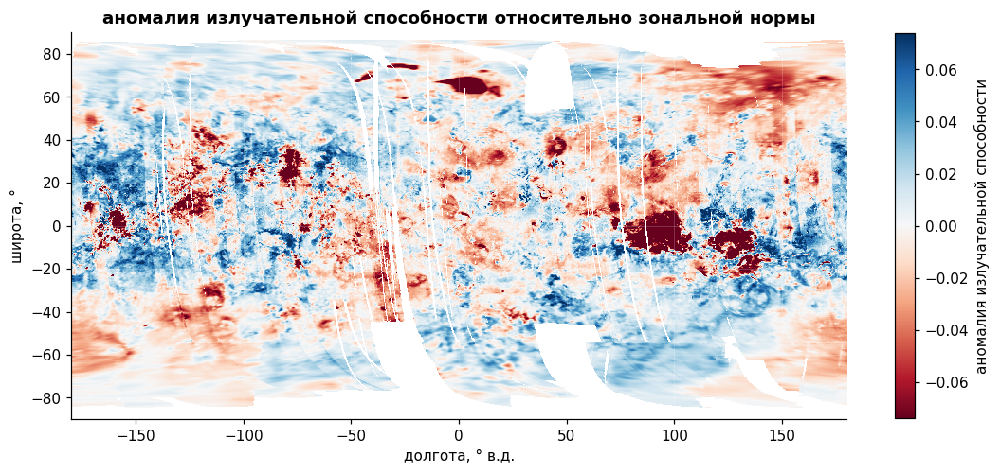

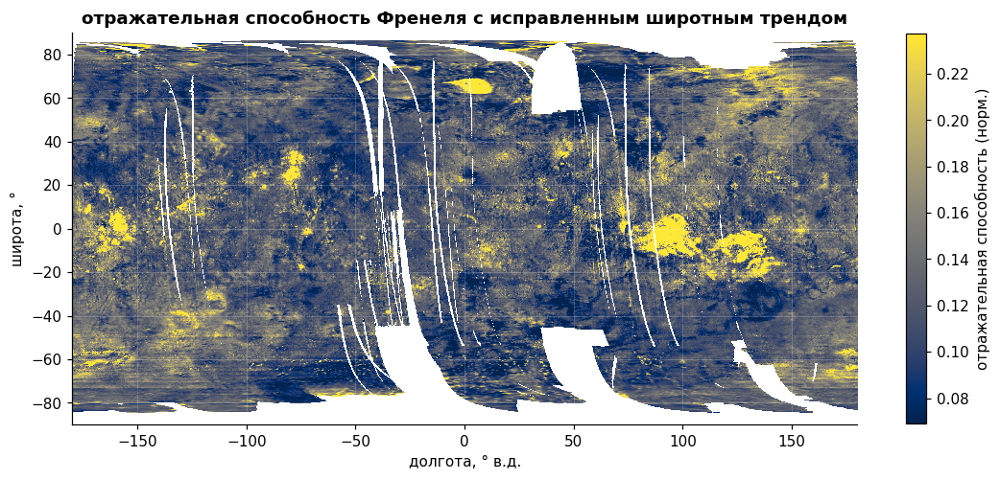

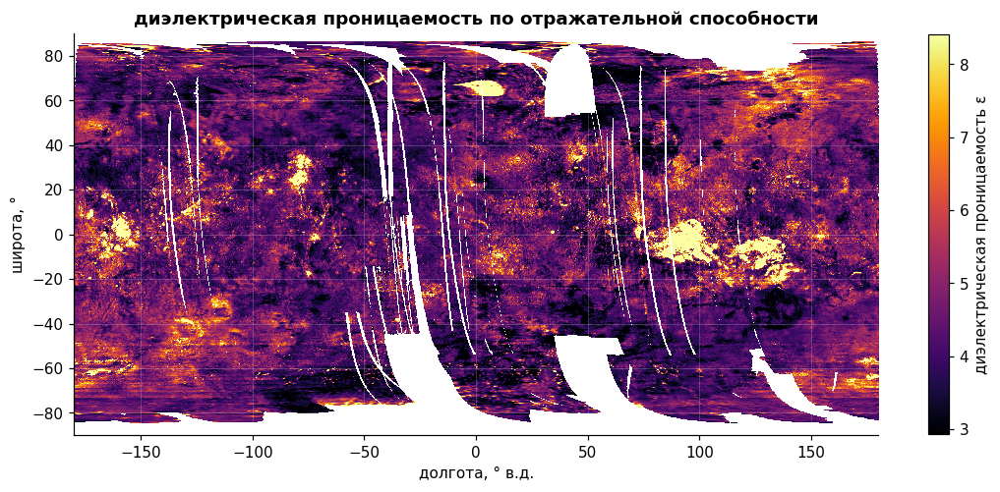

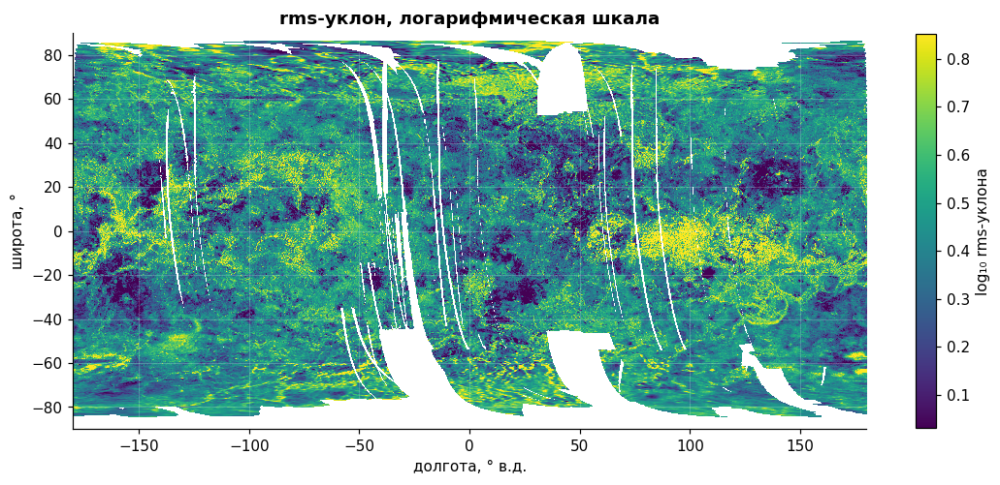

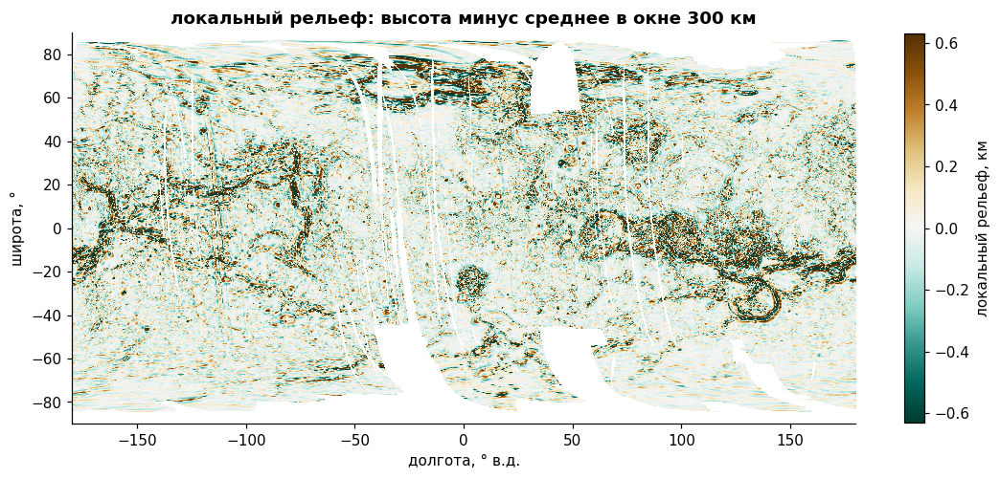

...

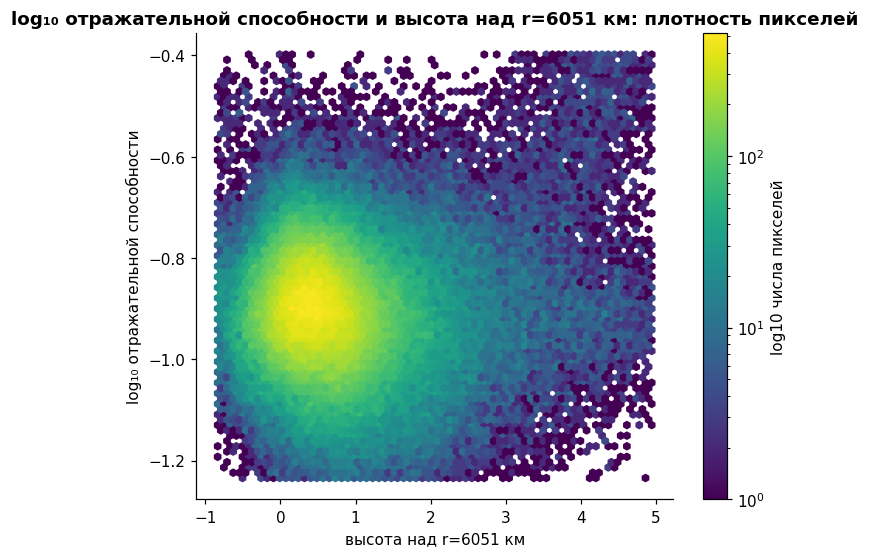

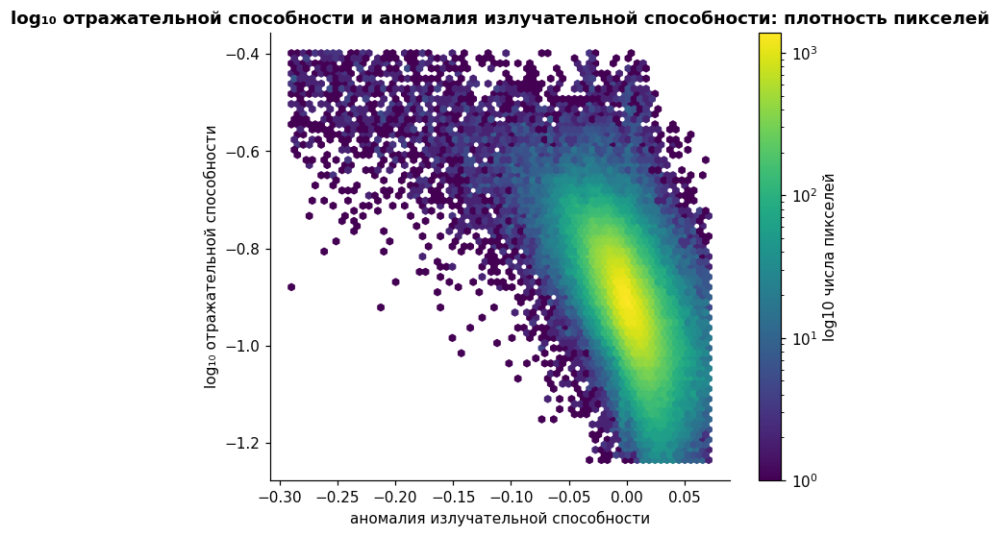

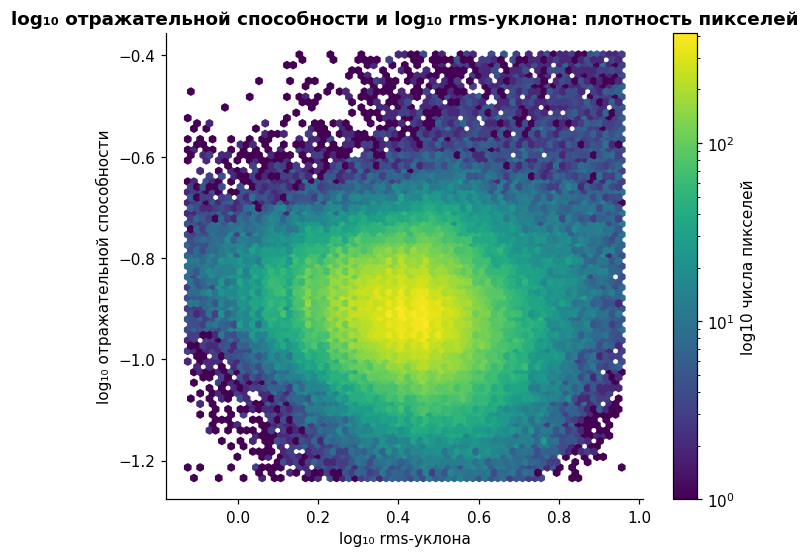

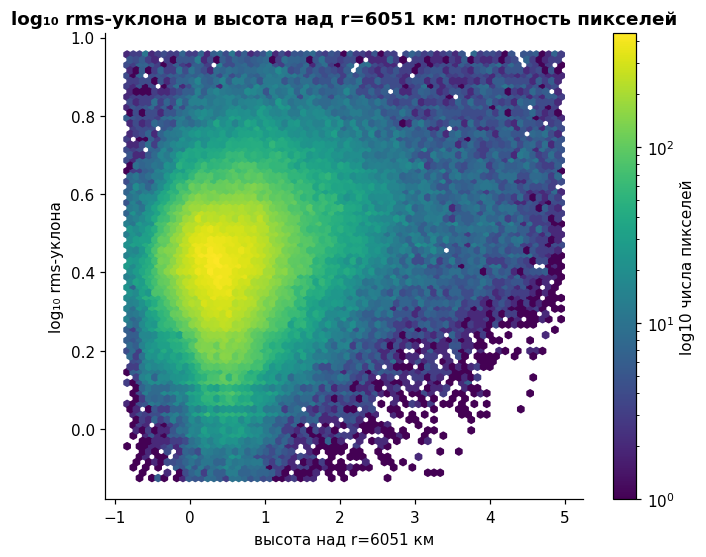

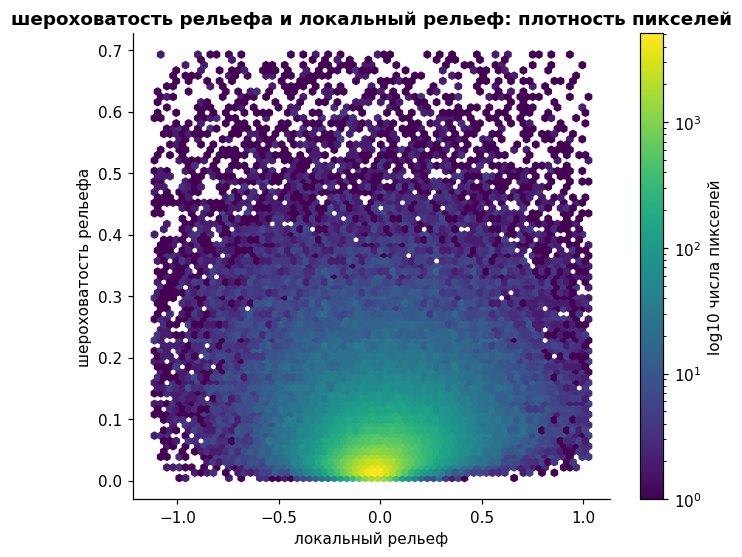

ячейка 3 завершена: признаки сохранены в work/features.npz


In [5]:
#=====================================================================
#ячейка 3 – радиофизические признаки и разведочный анализ
#запускать после ячейки 2
#признаки каждого пикселя:
#elev_km – высота над сферой 6051 км
#emis_anom – излучательная способность минус зональная норма низменностей
#refl_norm – отражательная способность с исправленным широтным трендом
#(в синусоидальной проекции GREDR (глобальная запись отражательной способности) тренд не исправлен)
#eps_refl – диэлектрическая проницаемость по формуле Френеля:
#ρ = ((√ε – 1)/(√ε + 1))^2, откуда √ε = (1 + √ρ)/(1 – √ρ)
#log_slope – log10 rms-уклона (среднеквадратичного уклона)
#relief_km – высота относительно среднего в окне около 300 км
#roughness_km – стандартное отклонение высоты в окне 3*3 пикселя
#результат: work/features.npz и отдельные картинки 03_*.png в папке figures
#=====================================================================
from scipy.ndimage import uniform_filter

print_header("ячейка 3. радиофизические признаки и разведочный анализ")
G = load_npz("grids")
lat, lon = G["lat"], G["lon"]
res = CFG["grid_res_deg"]
elev, emis, refl, slope = G["elev_km"], G["emis"], G["refl"], G["slope"]

valid = (np.isfinite(elev) & np.isfinite(emis) & np.isfinite(refl) & np.isfinite(slope)
         & (refl > 0) & (emis > 0) & (slope >= 0))
lowland = valid & (elev < CFG["lowland_max_elev_km"])
print(f"   пикселей со всеми 4 слоями: {valid.sum():,} ({100 * valid.mean():.1f}% сетки)")


def zonal_trend(arr, mask, smooth_deg=3.0):  #рассчитать сглаженную медиану по широтам для пикселей маски
    zm = np.nanmedian(np.where(mask, arr, np.nan), axis=1)
    zm[mask.sum(axis=1) < 30] = np.nan
    win = max(3, int(round(smooth_deg / res)) | 1)
    s = (pd.Series(zm).interpolate(limit_direction="both")
         .rolling(win, center=True, min_periods=1).median().values)
    return np.array(s, copy=True)[:, None].astype(np.float32)


with Timer("нормировки и производные признаки"):
    refl_norm = refl / zonal_trend(refl, lowland) * np.nanmedian(refl[lowland])
    emis_anom = emis - zonal_trend(emis, lowland)
    sr = np.sqrt(np.clip(refl_norm, 1e-3, 0.9))
    eps_refl = ((1 + sr) / (1 - sr)) ** 2
    px_km = R_KM * np.deg2rad(res)
    w = max(3, int(round(CFG["regional_window_km"] / px_km)) | 1)
    e_fill = fill_nan_nearest(elev)
    #по долготе окно замыкается через 180°
    relief = e_fill - uniform_filter(e_fill, size=w, mode=("nearest", "wrap"))
    m1 = uniform_filter(e_fill, size=3, mode=("nearest", "wrap"))
    m2 = uniform_filter(e_fill ** 2, size=3, mode=("nearest", "wrap"))
    roughness = np.sqrt(np.maximum(m2 - m1 ** 2, 0))

F = {
    "elev_km": elev, "emis": emis, "emis_anom": emis_anom, "refl_norm": refl_norm,
    "log_refl": np.log10(np.clip(refl_norm, 1e-3, None)), "eps_refl": eps_refl,
    "slope": slope, "log_slope": np.log10(slope + 0.1),
    "relief_km": relief, "roughness_km": roughness,
    "abs_lat": np.abs(lat)[:, None] * np.ones((1, lon.size)),
}
F = {k: np.where(valid, v, np.nan).astype(np.float32) for k, v in F.items()}
save_npz("features", lat=lat, lon=lon, valid=valid, **F)

stats = pd.DataFrame({k: pd.Series(F[k][valid]).describe(percentiles=[.01, .5, .99]) for k in F}).T
stats.insert(0, "описание", [FEATURE_INFO[k][0] for k in stats.index])
display(stats.round(4))
print(f"   медиана диэлектрической проницаемости низменностей: {np.nanmedian(F['eps_refl'][lowland]):.2f} "
      f"(для сухих базальтов обычно 4–6)")

MAP_TITLES = {
    "emis_anom": "аномалия излучательной способности относительно зональной нормы",
    "refl_norm": "отражательная способность Френеля с исправленным широтным трендом",
    "eps_refl": "диэлектрическая проницаемость по отражательной способности",
    "log_slope": "rms-уклон, логарифмическая шкала",
    "relief_km": "локальный рельеф: высота минус среднее в окне 300 км",
    "roughness_km": "шероховатость рельефа: стандартное отклонение в окне 3*3",
}
for k, title in MAP_TITLES.items():
    lbl, unit, cmap = FEATURE_INFO[k]
    vmin, vmax = robust_limits(F[k], 2, 98)
    if k in ("emis_anom", "relief_km"):
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
    fig, ax = plt.subplots(figsize=(12, 6))
    im = ax.imshow(F[k], extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    style_map(ax, title)
    fig.colorbar(im, ax=ax, shrink=0.8, label=f"{lbl}, {unit}" if unit else lbl)
    savefig(fig, f"03_map_{k}")

rng = np.random.default_rng(CFG["seed"])
vidx = np.flatnonzero(valid.ravel())
samp = rng.choice(vidx, size=min(1_500_000, vidx.size), replace=False)
E = F["elev_km"].ravel()[samp]
for k, ylab in (("emis", "излучательная способность"), ("refl_norm", "отражательная способность"),
                ("eps_refl", "диэлектрическая проницаемость")):
    Y = F[k].ravel()[samp]
    #хвосты не обрезаются: пиксели снега редки
    ylo, yhi = np.percentile(Y, [0.01, 99.99])
    fig, ax = plt.subplots(figsize=(8, 5.5))
    hb = ax.hexbin(E, Y, gridsize=110, bins="log", cmap="Greys", extent=(E.min(), E.max(), ylo, yhi), mincnt=1)
    bins = np.arange(np.floor(E.min()), np.ceil(E.max()) + 0.25, 0.25)
    mid, med, q1, q3 = [], [], [], []
    for a, b in zip(bins[:-1], bins[1:]):
        s = Y[(E >= a) & (E < b)]
        if s.size >= 30:
            mid.append((a + b) / 2)
            med.append(np.median(s))
            q1.append(np.percentile(s, 25))
            q3.append(np.percentile(s, 75))
    ax.fill_between(mid, q1, q3, color="tab:orange", alpha=0.3, label="25–75 перцентиль")
    ax.plot(mid, med, color="tab:red", lw=2, label="медиана")
    ax.set_ylim(ylo, yhi)
    ax.set_xlabel("высота, км")
    ax.set_ylabel(ylab)
    ax.set_title(f"{ylab} в зависимости от высоты")
    ax.legend(loc="best")
    fig.colorbar(hb, ax=ax, label="log10 числа пикселей")
    savefig(fig, f"03_{k}_vs_elevation")

cols = ["elev_km", "emis", "emis_anom", "log_refl", "eps_refl", "log_slope", "relief_km", "roughness_km"]
small = rng.choice(vidx, size=min(200_000, vidx.size), replace=False)
df_s = pd.DataFrame({c: F[c].ravel()[small] for c in cols})
corr = df_s.corr(method="spearman")
names = [FEATURE_INFO[c][0] for c in cols]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), names, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), names)
for a in range(len(cols)):
    for b in range(len(cols)):
        ax.text(b, a, f"{corr.iloc[a, b]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[a, b]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="коэффициент корреляции Спирмена")
ax.set_title("корреляции признаков")
savefig(fig, "03_correlations")

pairs = [("elev_km", "emis_anom"), ("elev_km", "log_refl"), ("emis_anom", "log_refl"),
         ("log_slope", "log_refl"), ("elev_km", "log_slope"), ("relief_km", "roughness_km")]
for a, b in pairs:
    x, y = df_s[a].values, df_s[b].values
    fig, ax = plt.subplots(figsize=(7, 5.5))
    hb = ax.hexbin(x, y, gridsize=70, bins="log", cmap="viridis", mincnt=1,
                   extent=(*np.percentile(x, [0.5, 99.5]), *np.percentile(y, [0.5, 99.5])))
    ax.set_xlabel(FEATURE_INFO[a][0])
    ax.set_ylabel(FEATURE_INFO[b][0])
    ax.set_title(f"{FEATURE_INFO[b][0]} и {FEATURE_INFO[a][0]}: плотность пикселей")
    fig.colorbar(hb, ax=ax, label="log10 числа пикселей")
    savefig(fig, f"03_pair_{a}_vs_{b}")

print("ячейка 3 завершена: признаки сохранены в work/features.npz")


  ячейка 4. кластеризация поверхности
   выборки: обучение 29,971 * 2, оценка 7,996; признаков: 6
   KMeans, k=3                кластеров=3  силуэт=0.328  db=1.340  ari=0.989  [0.9 с]
   KMeans, k=4                кластеров=4  силуэт=0.308  db=1.360  ari=0.950  [1.2 с]
   KMeans, k=5                кластеров=5  силуэт=0.182  db=1.424  ari=0.963  [1.5 с]
   KMeans, k=6                кластеров=6  силуэт=0.189  db=1.405  ari=0.946  [2.8 с]
   KMeans, k=7                кластеров=7  силуэт=0.180  db=1.368  ari=0.714  [3.0 с]
   KMeans, k=8                кластеров=8  силуэт=0.175  db=1.394  ari=0.940  [1.8 с]
   GMM, k=3                   кластеров=3  силуэт=0.168  db=1.956  ari=0.952  [5.5 с]
   GMM, k=4                   кластеров=4  силуэт=0.119  db=2.277  ari=0.785  [8.4 с]
   GMM, k=5                   кластеров=5  силуэт=0.047  db=2.457  ari=0.902  [7.3 с]
   GMM, k=6                   кластеров=6  силуэт=0.058  db=2.216  ari=0.951  [11.6 с]
   GMM, k=7                   кластеров=

,config,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_frac,score
0,"KMeans, k=3",3,0.328,2922.781982,1.340,0.989,0.0,1.000
1,"KMeans, k=4",4,0.308,2497.959961,1.360,0.950,0.0,0.932
2,"KMeans, k=5",5,0.182,2292.013916,1.424,0.963,0.0,0.825
3,"KMeans, k=6",6,0.189,2138.404053,1.405,0.946,0.0,0.804
4,"Agglomerative, k=3",3,0.282,2431.832031,1.460,0.704,0.0,0.750
5,"KMeans, k=8",8,0.175,1873.607056,1.394,0.940,0.0,0.704
6,"KMeans, k=7",7,0.180,2014.363037,1.368,0.714,0.0,0.650
7,"GMM, k=3",3,0.168,1725.014038,1.956,0.952,0.0,0.639
8,"Agglomerative, k=5",5,0.236,1792.265991,1.606,0.669,0.0,0.629
9,"Agglomerative, k=4",4,0.226,1997.998047,1.723,0.669,0.0,0.604


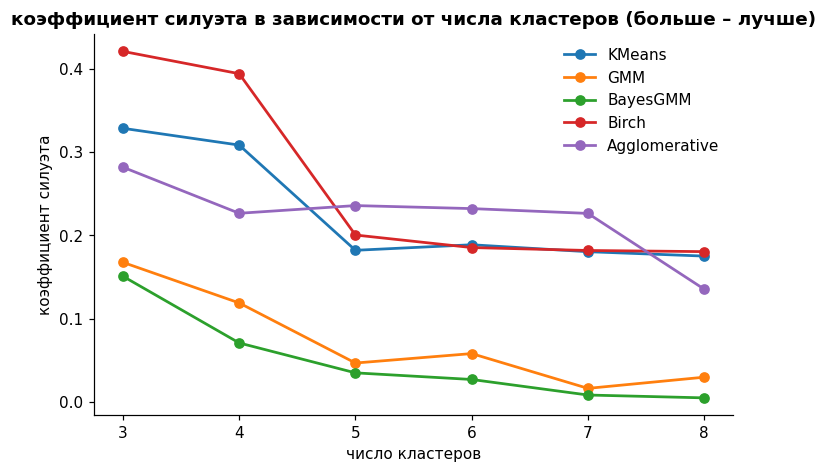

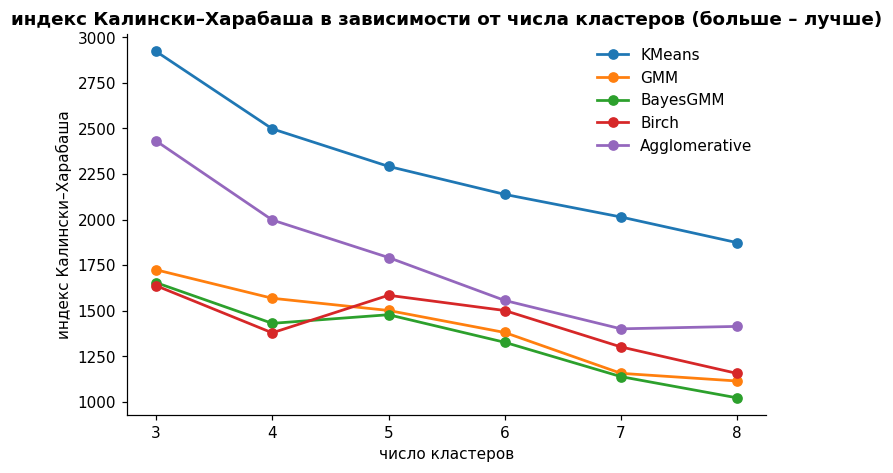

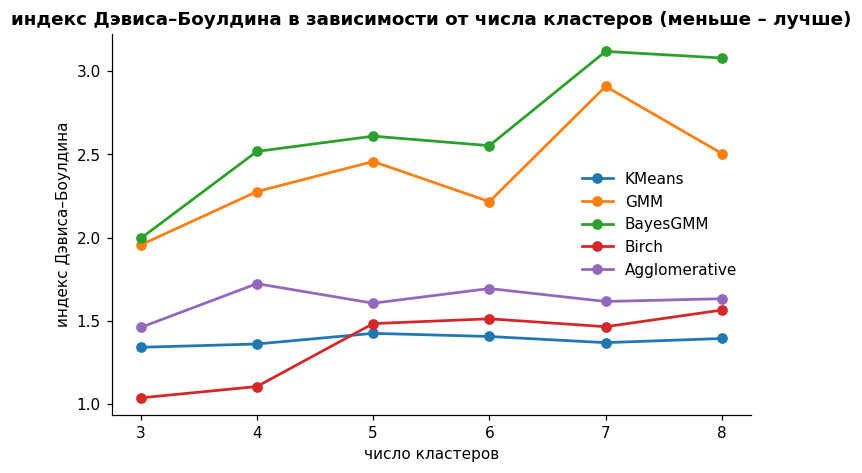

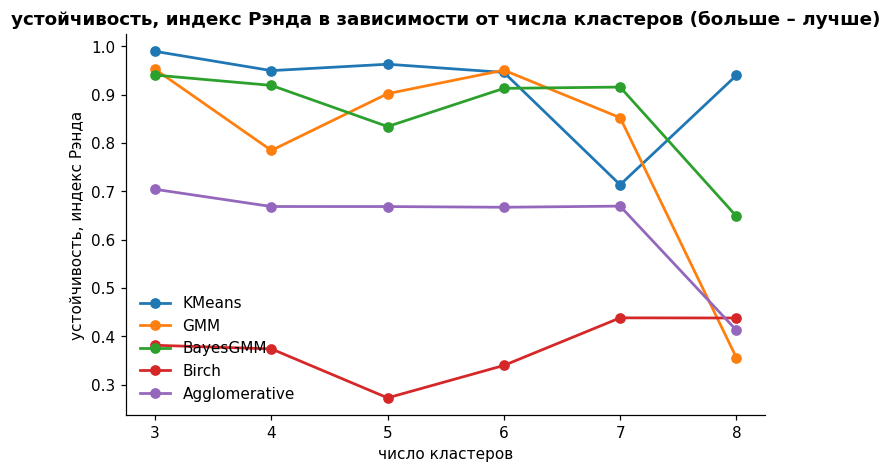

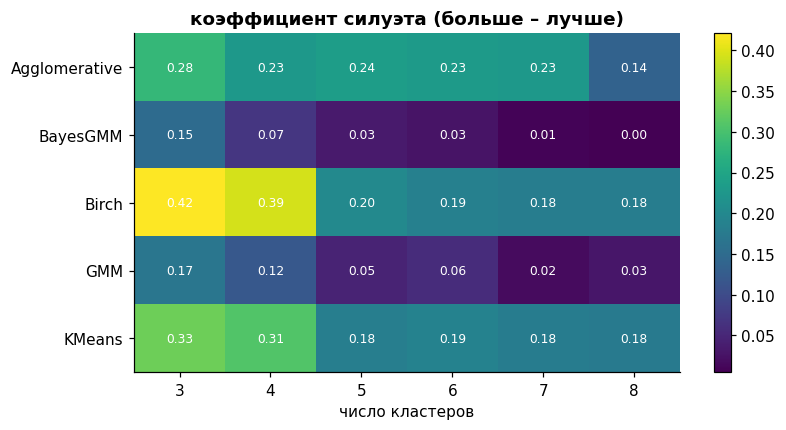

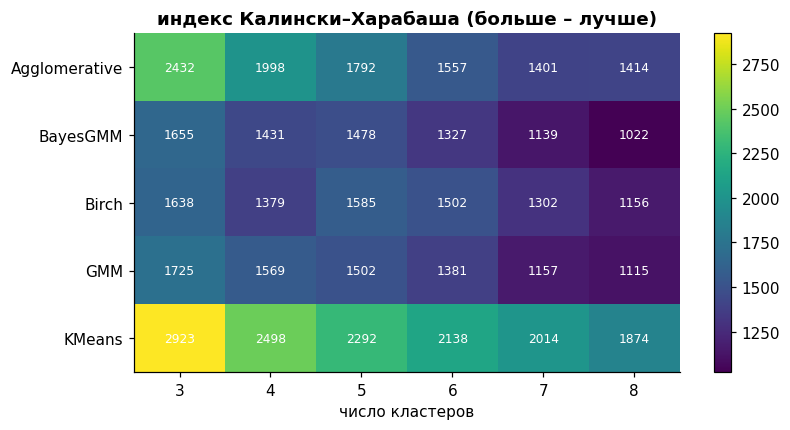

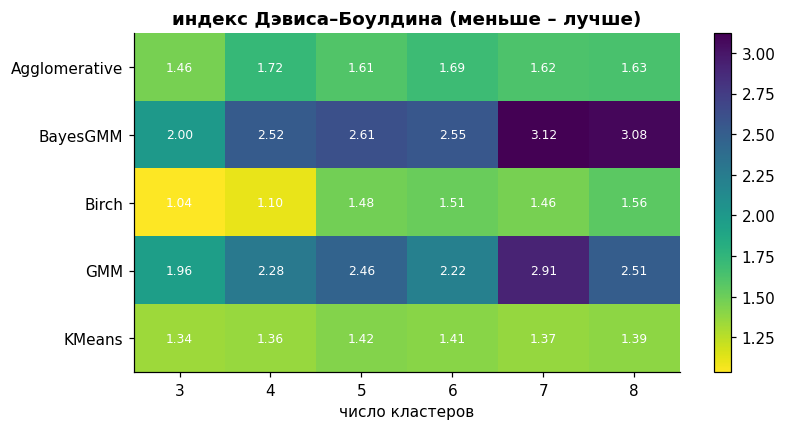

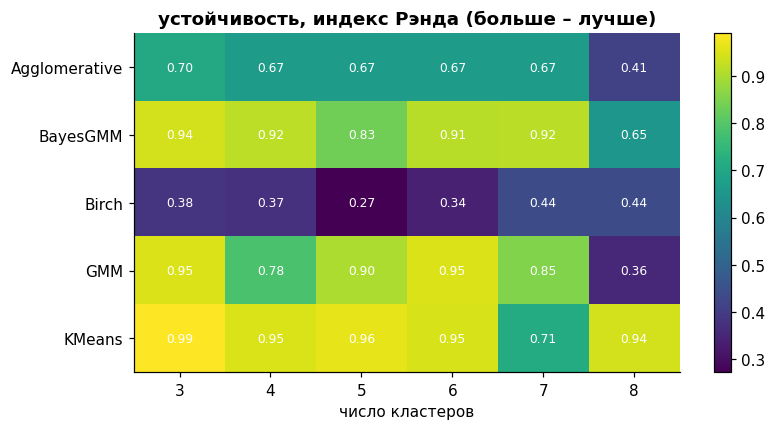

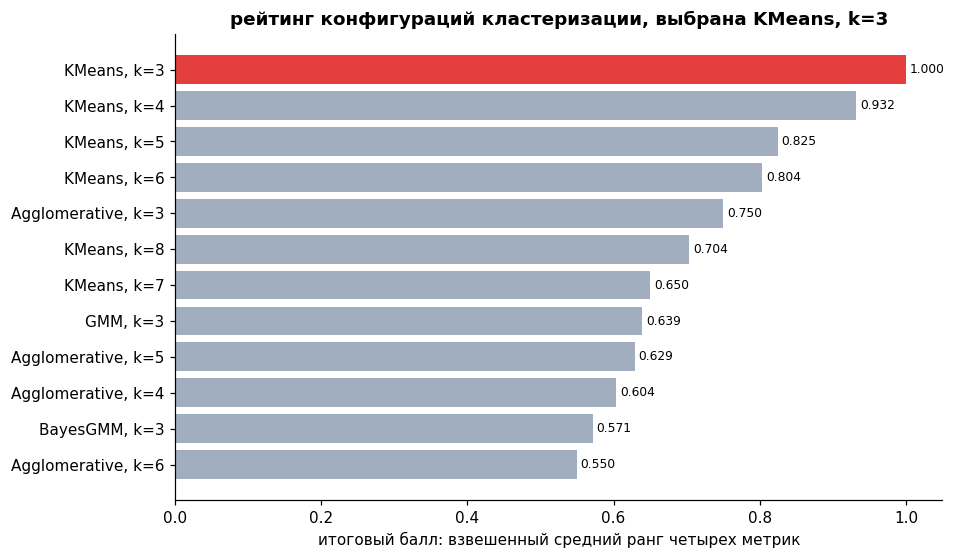

   разметка всех пикселей: 1.4 с


,название,"площадь, %",elev_km,emis_anom,log_refl,log_slope,relief_km,roughness_km
0,гладкие низменные равнины,82.95,0.480,0.000,-0.903,0.407,-0.024,0.033
1,"шероховатый рельеф (тессеры, рифты)",15.24,1.782,0.016,-0.955,0.633,0.210,0.144
2,высокогорья с низкой излучательной способность...,1.81,4.259,-0.230,-0.472,0.738,0.304,0.202


   t-sne (стохастическое вложение соседей): 35.0 с


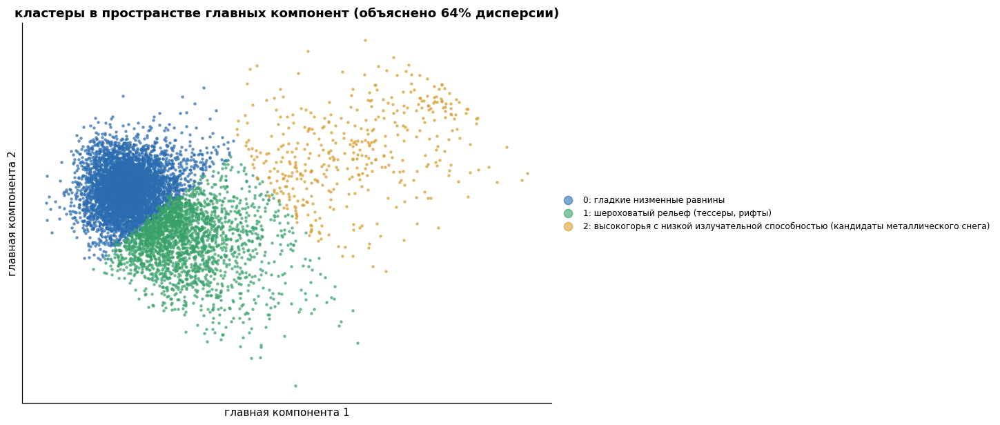

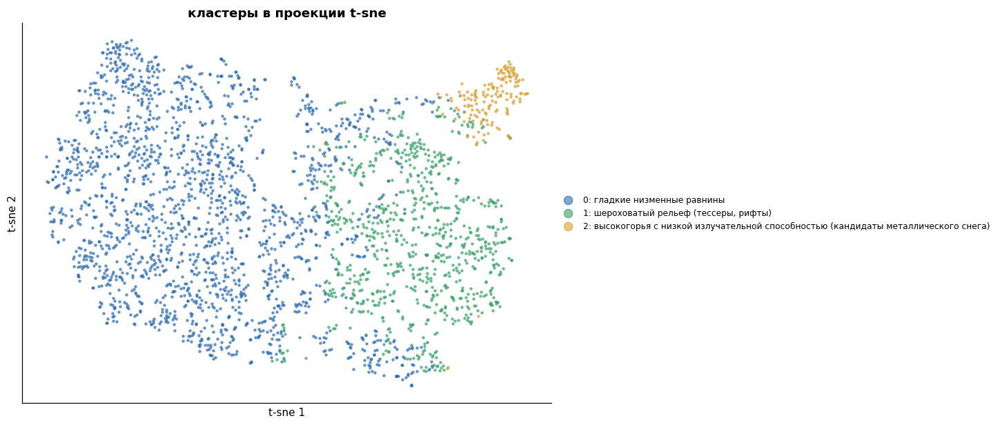

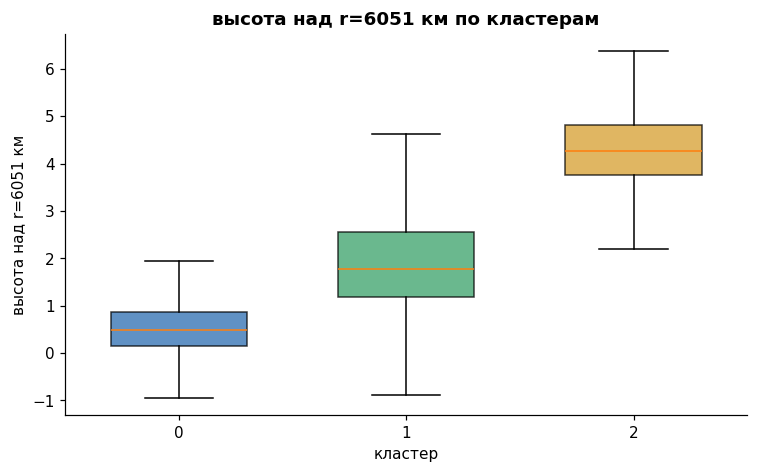

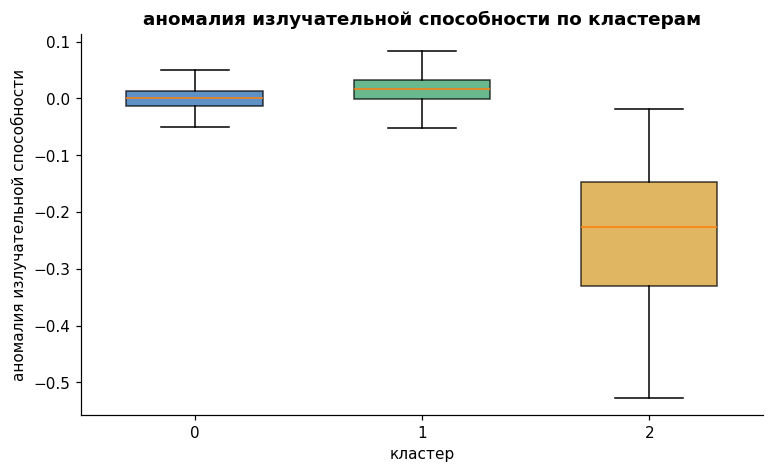

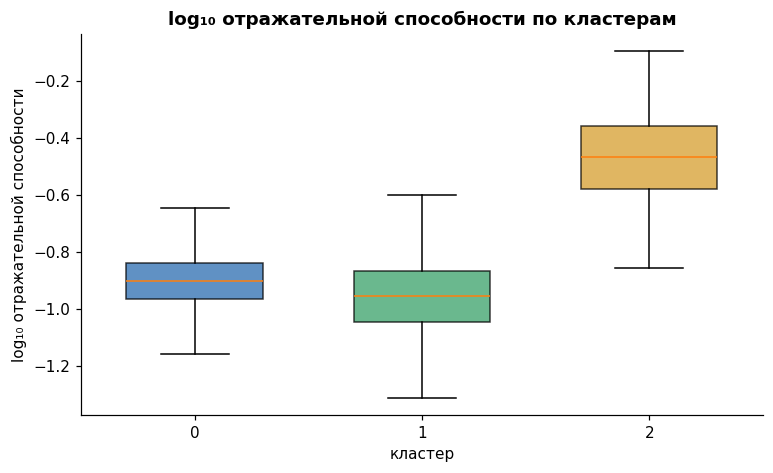

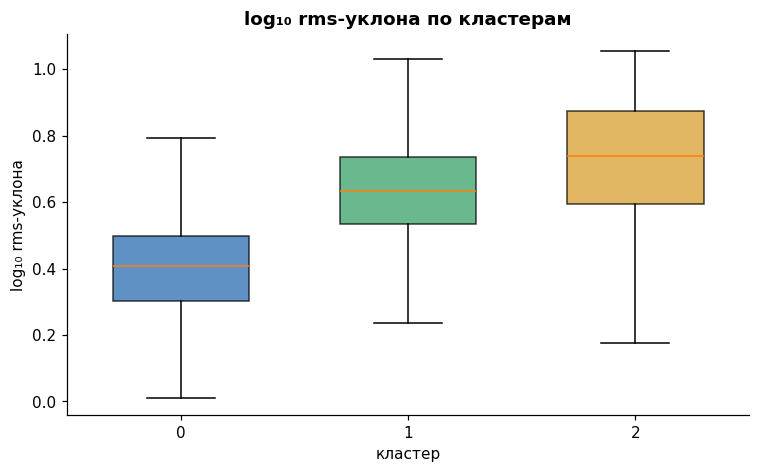

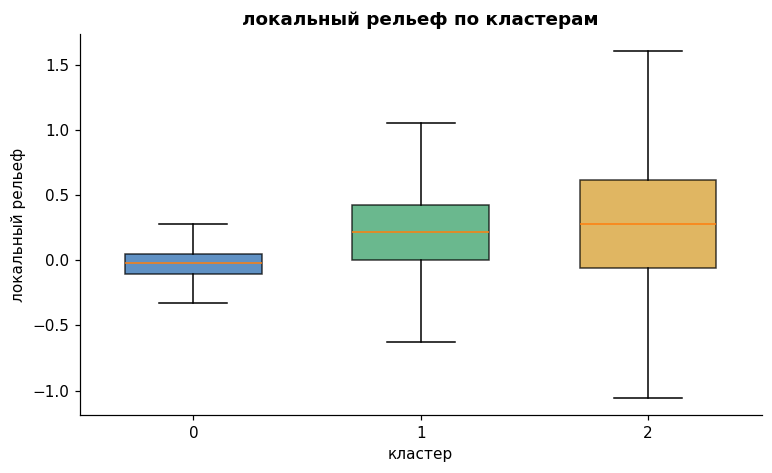

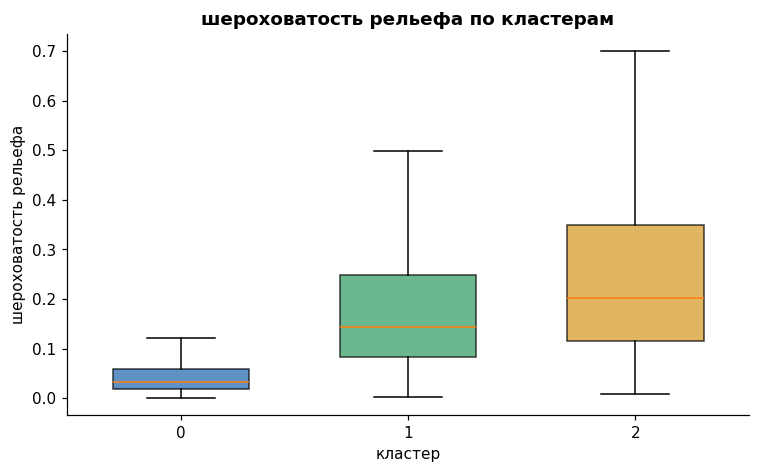

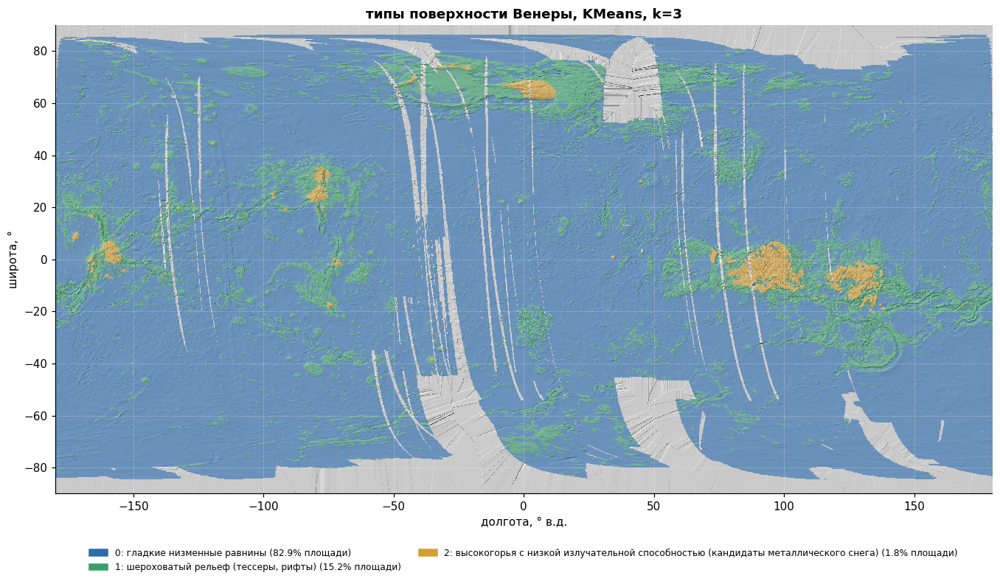

ячейка 4 завершена: карта кластеров в work/clusters.npz, метрики в results


In [6]:
#=====================================================================
#ячейка 4 – сегментация поверхности по типам грунта: несколько алгоритмов
#кластеризации, метрики качества и автоматический выбор лучшего
#запускать после ячейки 3
#алгоритмы: KMeans (метод k-средних), GMM (смесь гауссовых распределений),
#BayesGMM (байесовская смесь), Birch, Agglomerative (иерархическая, метод Уорда),
#HDBSCAN (иерархическая кластеризация по плотности, число групп определяет сам)
#метрики: силуэт и индекс Калински–Харабаша (больше – лучше), индекс Дэвиса–Боулдина
#(меньше – лучше), устойчивость ari (скорректированный индекс Рэнда) по двум выборкам
#выбор: взвешенный средний ранг по четырем метрикам, веса в CFG
#результат: work/clusters.npz, results/clustering_*.csv и .json, картинки 04_*.png
#=====================================================================
from sklearn.cluster import KMeans, Birch, AgglomerativeClustering
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    HDBSCAN = None

print_header("ячейка 4. кластеризация поверхности")
F = load_npz("features")
lat, lon, valid = F["lat"], F["lon"], F["valid"]
seed = CFG["seed"]
rng = np.random.default_rng(seed)

vidx = np.flatnonzero(valid.ravel())
#вес выборки пропорционален площади пикселя
w_area = np.cos(np.deg2rad(np.repeat(lat, lon.size)))[vidx]
high = vidx[F["elev_km"].ravel()[vidx] > CFG["snow_min_elev_km"]]


def draw_sample(n, rs):  #сформировать выборку: равномерная по площади и доля высокогорий
    n_high = min(int(n * CFG["highland_share"]), high.size)
    a = rs.choice(vidx, size=n - n_high, replace=False, p=w_area / w_area.sum())
    b = rs.choice(high, size=n_high, replace=False)
    return np.unique(np.concatenate([a, b]))


idx_A = draw_sample(CFG["n_fit"], rng)
idx_B = draw_sample(CFG["n_fit"], np.random.default_rng(seed + 1))
idx_E = draw_sample(CFG["n_eval"], np.random.default_rng(seed + 2))
flat = {k: F[k].ravel() for k in CLUSTER_FEATURES}
raw = lambda idx: np.column_stack([flat[k][idx] for k in CLUSTER_FEATURES]).astype(np.float32)

prep = Preprocessor().fit(raw(idx_A))
XA, XB, XE = prep.transform(raw(idx_A)), prep.transform(raw(idx_B)), prep.transform(raw(idx_E))
print(f"   выборки: обучение {len(XA):,} * 2, оценка {len(XE):,}; признаков: {XA.shape[1]}")


class ClusterModel:  #привести алгоритмы к единому интерфейсу fit и predict, перенос через knn (k ближайших соседей)
    SMALL = {"Agglomerative", "HDBSCAN"}

    def __init__(self, algo, k=None, param=None, seed=0):  #сохранить параметры конфигурации
        self.algo, self.k, self.param, self.seed = algo, k, param, seed
        self.knn, self.noise_frac = None, 0.0

    def _build(self):  #создать модель алгоритма
        a, k, s = self.algo, self.k, self.seed
        if a == "KMeans":
            return KMeans(n_clusters=k, n_init=10, random_state=s)
        if a == "GMM":
            return GaussianMixture(n_components=k, covariance_type="full", n_init=2, random_state=s)
        if a == "BayesGMM":
            return BayesianGaussianMixture(n_components=k, weight_concentration_prior_type="dirichlet_process",
                                           weight_concentration_prior=0.1, max_iter=500, random_state=s)
        if a == "Birch":
            return Birch(n_clusters=k, threshold=0.5)
        if a == "Agglomerative":
            return AgglomerativeClustering(n_clusters=k, linkage="ward")
        if a == "HDBSCAN":
            return HDBSCAN(min_cluster_size=self.param, min_samples=10)
        raise ValueError(a)

    def fit(self, X):  #обучить модель
        if self.algo in self.SMALL:
            X = X[: CFG["n_small"]]
        m = self._build()
        if self.algo in self.SMALL:
            lab = m.fit_predict(X)
            keep = lab >= 0
            self.noise_frac = 1 - keep.mean()
            if len(np.unique(lab[keep])) >= 2:
                self.knn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1).fit(X[keep], lab[keep])
        else:
            m.fit(X)
        self.model = m
        return self

    def predict(self, X):  #разметить новые точки
        if self.algo in self.SMALL:
            return self.knn.predict(X) if self.knn is not None else np.zeros(len(X), int)
        return self.model.predict(X)

    @property
    def name(self):  #получить название конфигурации
        return f"{self.algo}, k={self.k}" if self.k else f"{self.algo}, мин. размер {self.param}"


def evaluate(model_a, model_b, X):  #рассчитать метрики качества разбиения
    lab = model_a.predict(X)
    _, lab = np.unique(lab, return_inverse=True)
    n = lab.max() + 1
    row = {"algo": model_a.algo, "k": model_a.k, "param": model_a.param, "config": model_a.name,
           "n_clusters": int(n), "noise_frac": round(model_a.noise_frac, 3)}
    shares = np.bincount(lab) / len(lab)
    row["max_share"], row["min_share"] = shares.max(), shares.min()
    if n < 2:
        return row
    row["silhouette"] = silhouette_score(X, lab, sample_size=min(5000, len(X)), random_state=seed)
    row["calinski_harabasz"] = calinski_harabasz_score(X, lab)
    row["davies_bouldin"] = davies_bouldin_score(X, lab)
    if model_b is not None:
        row["stability_ari"] = adjusted_rand_score(lab, model_b.predict(X))
    return row


configs = [(a, k, None) for a in ("KMeans", "GMM", "BayesGMM", "Birch", "Agglomerative") for k in CFG["k_range"]]
if HDBSCAN is not None:
    configs += [("HDBSCAN", None, m) for m in CFG["hdbscan_min_sizes"]]

rows, MODELS = [], {}
t_all = time.time()
for algo, k, param in configs:
    t0 = time.time()
    try:
        ma = ClusterModel(algo, k, param, seed).fit(XA)
        mb = ClusterModel(algo, k, param, seed + 7).fit(XB) if CFG["check_stability"] else None
        row = evaluate(ma, mb, XE)
    except Exception as e:
        print(f"   ошибка {algo} k={k} param={param}: {str(e).lower()}")
        continue
    row["time_s"] = round(time.time() - t0, 1)
    rows.append(row)
    MODELS[row["config"]] = ma
    print(f"   {row['config']:<26} кластеров={row['n_clusters']:<2} "
          f"силуэт={row.get('silhouette', np.nan):.3f}  db={row.get('davies_bouldin', np.nan):.3f}  "
          f"ari={row.get('stability_ari', np.nan):.3f}  [{row['time_s']} с]")
print(f"   всего конфигураций: {len(rows)}, время {time.time() - t_all:.0f} с")

M = pd.DataFrame(rows)
for c in ("silhouette", "calinski_harabasz", "davies_bouldin", "stability_ari"):
    if c not in M:
        M[c] = np.nan
#отбрасываются вырожденные решения: меньше 3 групп, группа больше 90%, шум больше 30%
M["valid"] = (M["n_clusters"] >= 3) & (M["max_share"] < 0.9) & (M["noise_frac"] < 0.3) & M["silhouette"].notna()
W = {m: w for m, w in CFG["metric_weights"].items() if M[m].notna().any()}
score = 0
for m, w in W.items():
    r = M.loc[M["valid"], m].rank(pct=True, ascending=(m != "davies_bouldin"))
    score = score + w * r.reindex(M.index).fillna(0)
M["score"] = (score / sum(W.values())).where(M["valid"])
M = M.sort_values("score", ascending=False).reset_index(drop=True)
M.to_csv(OUT_DIR / "clustering_metrics.csv", index=False)
best_cfg = M.loc[0, "config"]
best = MODELS[best_cfg]
print(f"\n   лучшая конфигурация: {best_cfg} (итоговый балл {M.loc[0, 'score']:.3f})")
display(M[["config", "n_clusters", "silhouette", "calinski_harabasz", "davies_bouldin",
           "stability_ari", "noise_frac", "score"]].head(10).round(3))

kalgos = [a for a in ("KMeans", "GMM", "BayesGMM", "Birch", "Agglomerative") if a in set(M["algo"])]
METRIC_TITLES = {
    "silhouette": ("коэффициент силуэта", "больше – лучше"),
    "calinski_harabasz": ("индекс Калински–Харабаша", "больше – лучше"),
    "davies_bouldin": ("индекс Дэвиса–Боулдина", "меньше – лучше"),
    "stability_ari": ("устойчивость, индекс Рэнда", "больше – лучше"),
}
for m, (name, hint) in METRIC_TITLES.items():
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for i, a in enumerate(kalgos):
        d = M[M["algo"] == a].sort_values("k")
        ax.plot(d["k"], d[m], "o-", color=MODEL_COLORS[i], label=a, lw=1.8)
    ax.set_xlabel("число кластеров")
    ax.set_ylabel(name)
    ax.set_title(f"{name} в зависимости от числа кластеров ({hint})")
    ax.legend()
    savefig(fig, f"04_{m}_vs_k")

for m, (name, hint) in METRIC_TITLES.items():
    piv = M[M["algo"].isin(kalgos)].pivot_table(index="algo", columns="k", values=m)
    fig, ax = plt.subplots(figsize=(8, 4))
    im = ax.imshow(piv.values, cmap="viridis_r" if m == "davies_bouldin" else "viridis", aspect="auto")
    ax.set_xticks(range(piv.shape[1]), [int(c) for c in piv.columns])
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}" if v < 100 else f"{v:.0f}", ha="center", va="center", fontsize=8, color="w")
    ax.set_xlabel("число кластеров")
    ax.set_title(f"{name} ({hint})")
    fig.colorbar(im, ax=ax)
    savefig(fig, f"04_{m}_table")

top = M[M["valid"]].head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["config"], top["score"], color=["#e53e3e" if c == best_cfg else "#a0aec0" for c in top["config"]])
for yv, sv in enumerate(top["score"]):
    ax.text(sv + 0.005, yv, f"{sv:.3f}", va="center", fontsize=8)
ax.set_xlabel("итоговый балл: взвешенный средний ранг четырех метрик")
ax.set_title(f"рейтинг конфигураций кластеризации, выбрана {best_cfg}")
savefig(fig, "04_ranking")

with Timer("разметка всех пикселей"):
    X_all_raw = stack_features(F, CLUSTER_FEATURES, valid)
    X_all = prep.transform(X_all_raw)
    lab_all = predict_in_batches(best.predict, X_all)
    #кластер 0 – самый низкий по средней высоте
    uniq = np.unique(lab_all)
    order = sorted(uniq, key=lambda c: X_all_raw[lab_all == c, 0].mean())
    lut = np.zeros(uniq.max() + 1, dtype=int)
    lut[order] = np.arange(len(order))
    lab_all = lut[lab_all]
    lab_eval = lut[best.predict(XE)]
K = len(order)
cluster_map = np.full(valid.shape, -1, dtype=np.int16)
cluster_map[valid] = lab_all

Z = pd.DataFrame(X_all, columns=CLUSTER_FEATURES).groupby(lab_all).median()


def auto_name(z):  #назвать кластер по медианам стандартизованных признаков
    if z["elev_km"] > 0.8 and z["emis_anom"] < -0.8:
        return "высокогорья с низкой излучательной способностью (кандидаты металлического снега)"
    if z["elev_km"] > 0.8:
        return "высокогорья и плато"
    if z["log_slope"] > 0.7 or z["roughness_km"] > 0.7:
        return "шероховатый рельеф (тессеры, рифты)"
    if z["log_refl"] > 0.7:
        return "радиояркие равнины"
    if z["elev_km"] < -0.4:
        return "гладкие низменные равнины"
    return "равнины среднего уровня"


names = [auto_name(Z.loc[c]) for c in range(K)]
for n in set(names):
    ids = [i for i, x in enumerate(names) if x == n]
    if len(ids) > 1:
        for j, i in enumerate(ids):
            names[i] = f"{n} {j + 1}"
area = pixel_area_km2(lat, CFG["grid_res_deg"]) * np.ones((1, lon.size))
shares = [100 * area[cluster_map == c].sum() / area[valid].sum() for c in range(K)]
profile = pd.DataFrame(X_all_raw, columns=CLUSTER_FEATURES).groupby(lab_all).median()
profile.insert(0, "название", names)
profile.insert(1, "площадь, %", np.round(shares, 2))
display(profile.round(3))

colors = CLUSTER_COLORS[:K]
cmapK = mcolors.ListedColormap(colors)
legend_labels = [f"{c}: {names[c]}" for c in range(K)]
pca = PCA(2, random_state=seed).fit(XE)
P = pca.transform(XE)
sub = np.random.default_rng(seed).choice(len(XE), size=min(3000, len(XE)), replace=False)
with Timer("t-sne (стохастическое вложение соседей)"):
    T = TSNE(n_components=2, perplexity=40, init="pca", random_state=seed).fit_transform(XE[sub])
for Y, lab, title, fname, xl, yl in (
        (P, lab_eval, f"кластеры в пространстве главных компонент (объяснено "
                      f"{100 * pca.explained_variance_ratio_.sum():.0f}% дисперсии)",
         "04_clusters_pca", "главная компонента 1", "главная компонента 2"),
        (T, lab_eval[sub], "кластеры в проекции t-sne", "04_clusters_tsne", "t-sne 1", "t-sne 2")):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for c in range(K):
        sel = lab == c
        ax.scatter(Y[sel, 0], Y[sel, 1], s=4, alpha=0.6, color=colors[c], label=legend_labels[c])
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.legend(markerscale=4, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
    savefig(fig, fname)

box_idx = np.random.default_rng(seed).choice(len(lab_all), size=min(80_000, len(lab_all)), replace=False)
for i, f in enumerate(CLUSTER_FEATURES):
    data = [X_all_raw[box_idx][lab_all[box_idx] == c, i] for c in range(K)]
    data = [d if d.size else np.array([np.nan]) for d in data]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
    for patch, col in zip(bp["boxes"], colors):
        patch.set_facecolor(col)
        patch.set_alpha(0.75)
    ax.set_xticks(range(1, K + 1), [str(c) for c in range(K)])
    ax.set_xlabel("кластер")
    ax.set_ylabel(FEATURE_INFO[f][0])
    ax.set_title(f"{FEATURE_INFO[f][0]} по кластерам")
    savefig(fig, f"04_profile_{f}")

fig, ax = plt.subplots(figsize=(15, 7.5))
ax.imshow(hillshade(F["elev_km"], CFG["grid_res_deg"]), extent=EXTENT, cmap="gray", interpolation="nearest")
ax.imshow(np.ma.masked_less(cluster_map, 0), extent=EXTENT, cmap=cmapK, vmin=-0.5, vmax=K - 0.5,
          alpha=0.6, interpolation="nearest")
style_map(ax, f"типы поверхности Венеры, {best_cfg}")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[c]) for c in range(K)],
          labels=[f"{legend_labels[c]} ({shares[c]:.1f}% площади)" for c in range(K)],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8)
savefig(fig, "04_cluster_map")

save_npz("clusters", cluster_map=cluster_map)
meta = {"best_config": best_cfg, "n_clusters": K, "names": names, "colors": colors,
        "area_share_pct": [round(s, 3) for s in shares], "features": CLUSTER_FEATURES,
        "metrics": M.loc[0, ["silhouette", "calinski_harabasz", "davies_bouldin", "stability_ari", "score"]]
        .astype(float).round(4).to_dict()}
(OUT_DIR / "clustering_summary.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2))
profile.to_csv(OUT_DIR / "cluster_profiles.csv")
try:
    joblib.dump({"prep": prep, "model": best}, WORK_DIR / "cluster_model.joblib")
except Exception as e:
    print(f"   модель не сохранена ({str(e).lower()}), карта и метрики сохранены")
print("ячейка 4 завершена: карта кластеров в work/clusters.npz, метрики в results")


  ячейка 5. детектор металлического снега
   mad аномалии излучательной способности: 0.0181; порог снега: -4.0*mad = -0.072
   пикселей снег: 92,795, не снег: 4,499,795, без метки: 884,716
   обучающая выборка: 198,540 (доля снега 20.15%), блоков кросс-валидации: 72
   LogReg        готово за 3.5 с
   kNN           готово за 17.4 с
   RandomForest  готово за 613.5 с
   HistGB        готово за 29.6 с
   MLP           готово за 139.2 с
   LightGBM      готово за 26.9 с

   лучший классификатор: HistGB (pr-auc 0.880, порог 0.769)


,model,pr-auc,pr-auc σ,roc-auc,roc-auc σ,f1,точность,полнота,mcc,сбалансированная точность,brier,порог
0,HistGB,0.880,0.226,0.996,0.002,0.944,0.946,0.942,0.930,0.964,0.021,0.769
1,LightGBM,0.874,0.240,0.996,0.002,0.943,0.951,0.937,0.929,0.962,0.020,0.785
2,RandomForest,0.855,0.284,0.996,0.002,0.945,0.952,0.938,0.931,0.963,0.018,0.653
3,MLP,0.852,0.288,0.996,0.002,0.942,0.948,0.936,0.927,0.961,0.018,0.476
4,kNN,0.844,0.292,0.989,0.006,0.941,0.948,0.935,0.927,0.961,0.018,0.487
5,LogReg,0.811,0.361,0.993,0.002,0.927,0.929,0.926,0.909,0.954,0.030,0.805


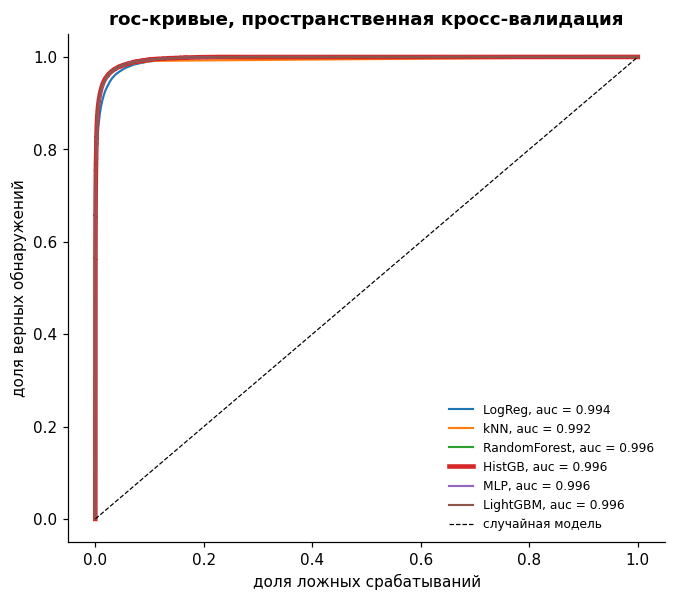

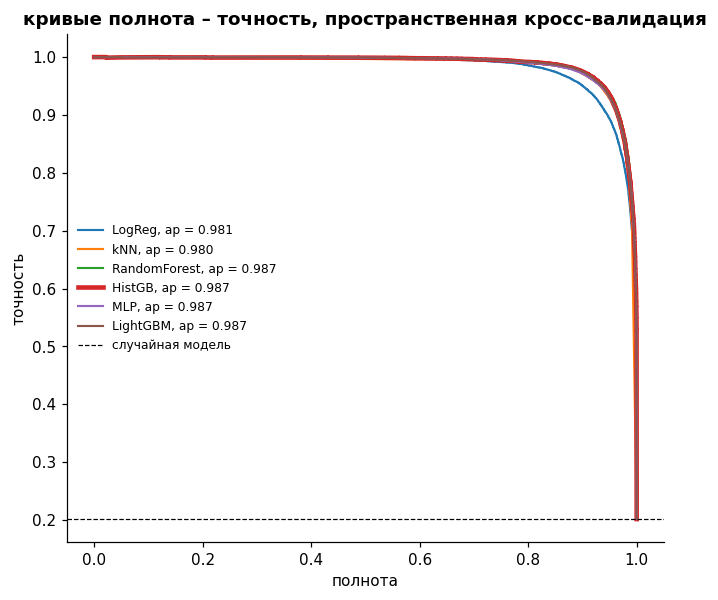

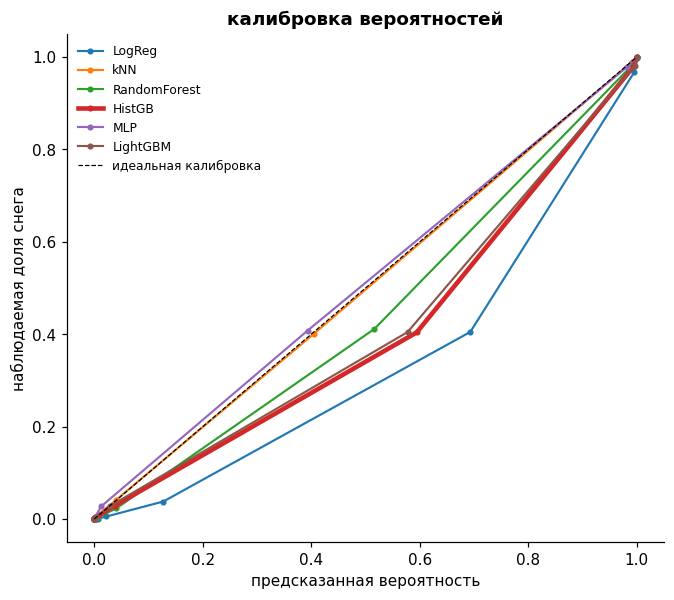

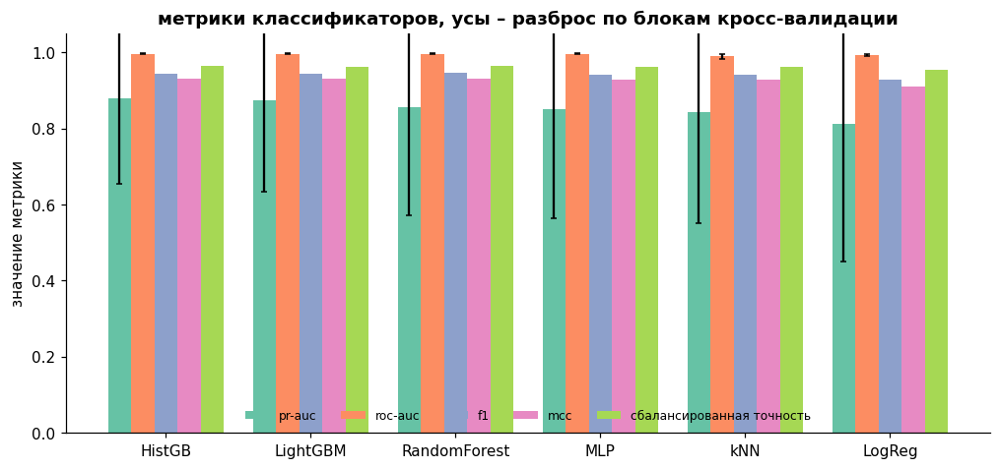

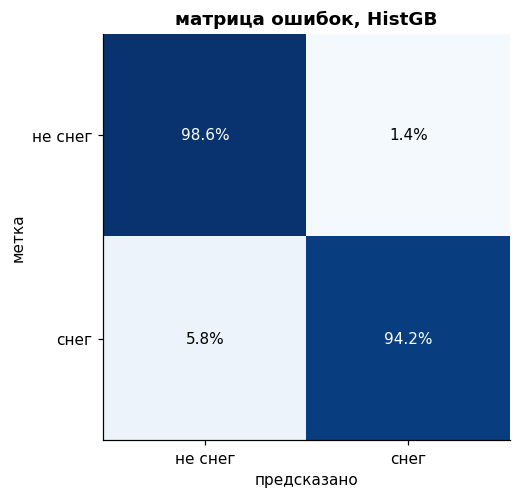

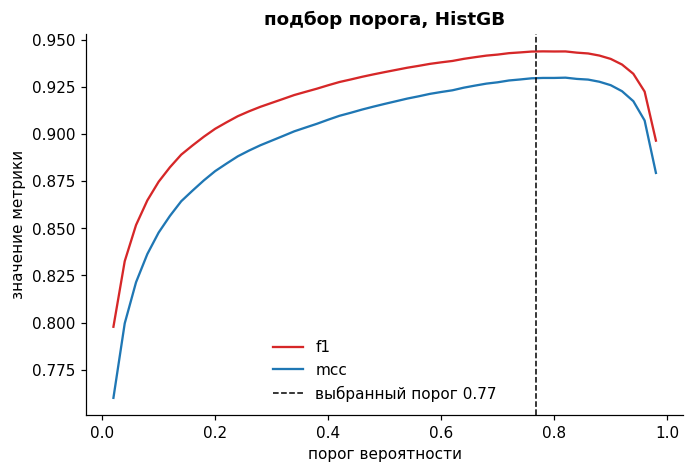

   перестановочная важность признаков: 25.6 с


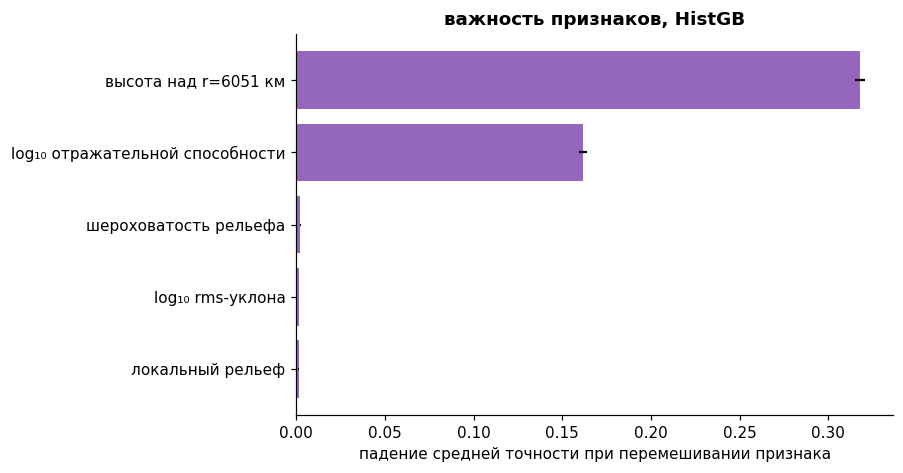

   обучение финальной модели и прогноз по планете: 113.2 с
   площадь металлического снега: 12,514,795 км^2 (2.924% поверхности)

   часть b: детекторы аномалий без учителя
   лучший детектор аномалий: EllipticEnvelope


,detector,roc-auc,pr-auc,"время, с"
0,EllipticEnvelope,0.991,0.972,4.5
1,IsolationForest,0.991,0.970,4.7
2,OneClassSVM,0.877,0.653,2.3
3,LOF,0.557,0.288,12.7


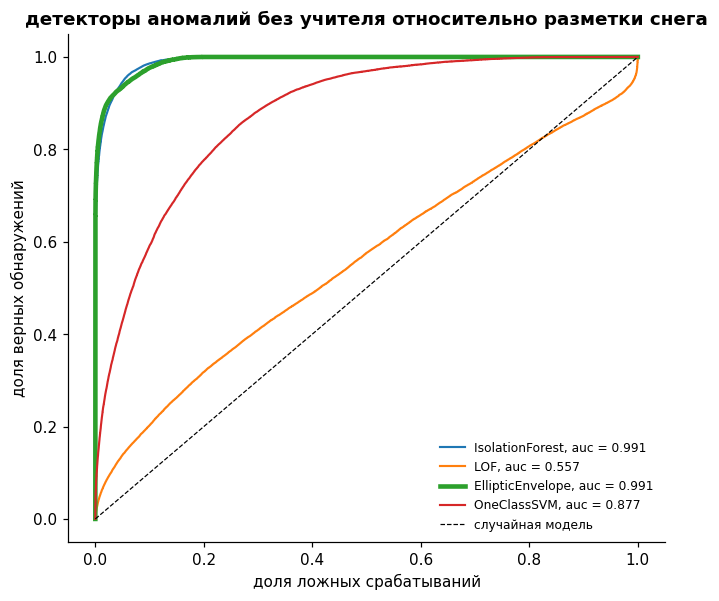

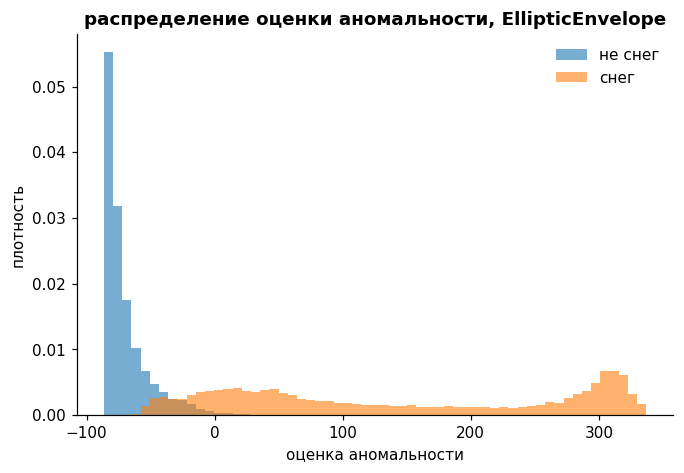

   карта аномальности (EllipticEnvelope): 3.6 с


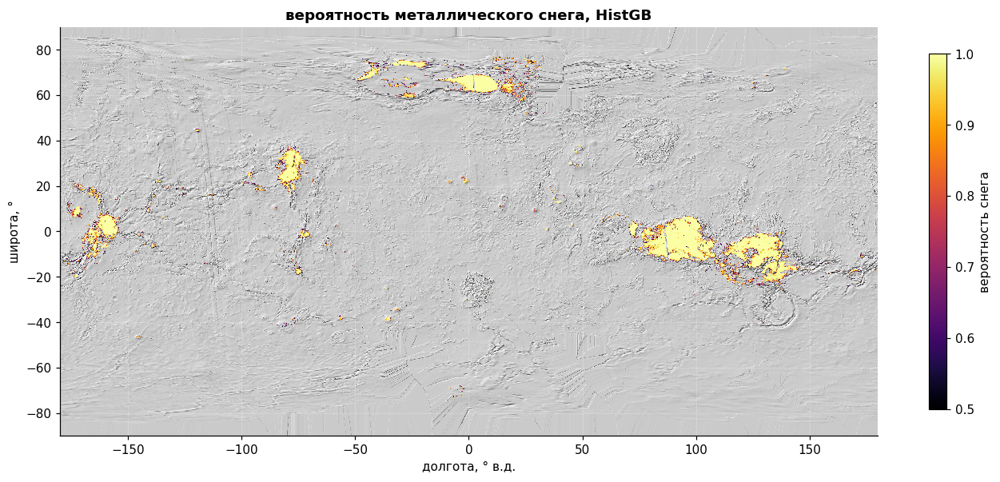

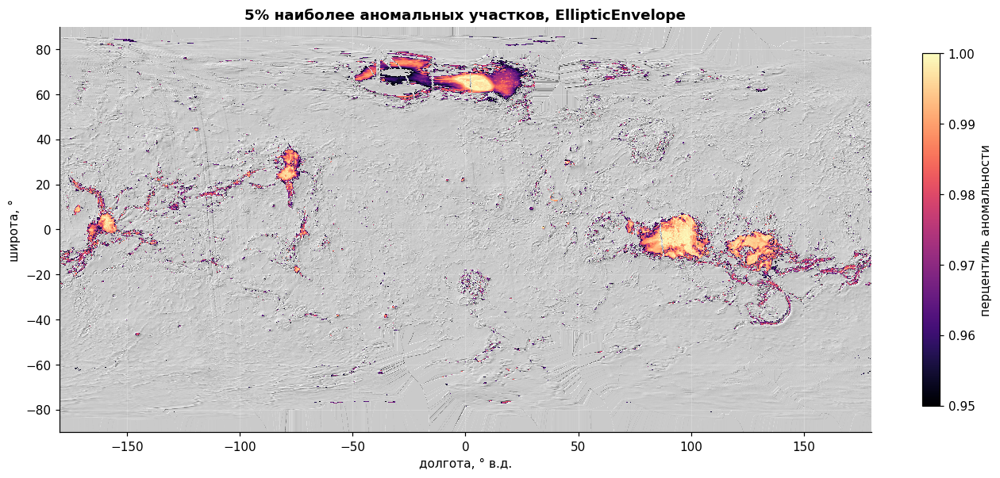

ячейка 5 завершена: карты в work/snow.npz, метрики в results


In [7]:
#=====================================================================
#ячейка 5 – картирование металлического снега
#запускать после ячейки 4
#часть a: слабая разметка по физическому правилу и классификаторы
#с пространственной кросс-валидацией
#метка снег: излучательная способность ниже зональной нормы больше чем на k*mad
#(медианное абсолютное отклонение) и высота больше snow_min_elev_km
#метка не снег: излучательная способность в норме, половина отрицательных примеров
#берется из высокогорий без аномалии
#модели обучаются без излучательной способности: высота, рельеф, отражательная
#способность (альтиметр – независимый прибор) и уклоны
#кросс-валидация по блокам 30°*30° (StratifiedGroupKFold): соседние пиксели не попадают
#одновременно в обучение и проверку
#часть b: детекторы аномалий без учителя (IsolationForest, lof (локальный фактор выброса),
#EllipticEnvelope, One-Class svm (одноклассовый метод опорных векторов)) сравниваются с той же разметкой
#результат: work/snow.npz, results/snow_*.csv и .json, картинки 05_*.png
#=====================================================================
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import OneClassSVM
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             f1_score, matthews_corrcoef, balanced_accuracy_score, precision_score,
                             recall_score, brier_score_loss, confusion_matrix)

print_header("ячейка 5. детектор металлического снега")
F = load_npz("features")
lat, lon, valid = F["lat"], F["lon"], F["valid"]
seed = CFG["seed"]
rng = np.random.default_rng(seed)
res = CFG["grid_res_deg"]

ea, elev = F["emis_anom"], F["elev_km"]
low = valid & (elev < CFG["lowland_max_elev_km"])
mad = 1.4826 * np.nanmedian(np.abs(ea[low] - np.nanmedian(ea[low])))
k_pos = CFG["snow_k_mad"]
#при малом числе примеров порог смягчается до 2*mad
while True:
    pos = valid & (ea < -k_pos * mad) & (elev > CFG["snow_min_elev_km"])
    if pos.sum() >= 300 or k_pos <= 2.0:
        break
    k_pos -= 0.5
neg = valid & (ea > -CFG["neg_k_mad"] * mad)
print(f"   mad аномалии излучательной способности: {mad:.4f}; порог снега: -{k_pos:.1f}*mad = {-k_pos * mad:.3f}")
print(f"   пикселей снег: {pos.sum():,}, не снег: {neg.sum():,}, без метки: {(valid & ~pos & ~neg).sum():,}")

pos_idx = np.flatnonzero(pos.ravel())
if pos_idx.size > CFG["max_pos"]:
    pos_idx = rng.choice(pos_idx, CFG["max_pos"], replace=False)
n_neg = CFG["neg_ratio"] * pos_idx.size
neg_all = np.flatnonzero(neg.ravel())
neg_hard = np.flatnonzero((neg & (elev > CFG["snow_min_elev_km"] - 0.5)).ravel())
neg_idx = np.unique(np.concatenate([
    rng.choice(neg_all, min(n_neg // 2, neg_all.size), replace=False),
    rng.choice(neg_hard, min(n_neg // 2, neg_hard.size), replace=False)]))
idx = np.concatenate([pos_idx, neg_idx])
y = np.concatenate([np.ones(pos_idx.size, int), np.zeros(neg_idx.size, int)])
X = np.column_stack([F[f].ravel()[idx] for f in SNOW_FEATURES]).astype(np.float32)

rr, cc = np.unravel_index(idx, valid.shape)
t = CFG["tile_deg"]
groups = ((90 - lat[rr]) // t).astype(int) * 100 + ((lon[cc] + 180) // t).astype(int)
print(f"   обучающая выборка: {len(y):,} (доля снега {y.mean():.2%}), блоков кросс-валидации: {len(np.unique(groups))}")

CLASSIFIERS = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance")),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                           n_jobs=-1, random_state=seed),
    "HistGB": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, class_weight="balanced",
                                             random_state=seed),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                         max_iter=400, random_state=seed)),
}
try:
    from lightgbm import LGBMClassifier
    CLASSIFIERS["LightGBM"] = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                             class_weight="balanced", random_state=seed, verbose=-1)
except ImportError:
    pass

cv = StratifiedGroupKFold(n_splits=CFG["cv_folds"], shuffle=True, random_state=seed)
splits = list(cv.split(X, y, groups))
OOF, fold_rows = {}, []
for name, est in CLASSIFIERS.items():
    oof = np.full(len(y), np.nan)
    t0 = time.time()
    for f, (tr, te) in enumerate(splits):
        m = clone(est).fit(X[tr], y[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
        if len(np.unique(y[te])) == 2:
            fold_rows.append({"model": name, "fold": f, "roc_auc": roc_auc_score(y[te], oof[te]),
                              "pr_auc": average_precision_score(y[te], oof[te])})
    OOF[name] = oof
    print(f"   {name:<13} готово за {time.time() - t0:.1f} с")


def best_threshold(y_true, p):  #найти порог вероятности с максимальной f1-мерой
    pr, rc, th = precision_recall_curve(y_true, p)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-9)
    return th[np.nanargmax(f1[:-1])]


rows = []
FR = pd.DataFrame(fold_rows)
for name, p in OOF.items():
    thr = best_threshold(y, p)
    yh = (p >= thr).astype(int)
    fr = FR[FR["model"] == name]
    rows.append({"model": name,
                 "pr-auc": fr["pr_auc"].mean(), "pr-auc σ": fr["pr_auc"].std(),
                 "roc-auc": fr["roc_auc"].mean(), "roc-auc σ": fr["roc_auc"].std(),
                 "f1": f1_score(y, yh), "точность": precision_score(y, yh), "полнота": recall_score(y, yh),
                 "mcc": matthews_corrcoef(y, yh), "сбалансированная точность": balanced_accuracy_score(y, yh),
                 "brier": brier_score_loss(y, p), "порог": thr})
CM = pd.DataFrame(rows).sort_values(["pr-auc", "roc-auc"], ascending=False).reset_index(drop=True)
CM.to_csv(OUT_DIR / "snow_classifier_metrics.csv", index=False)
best_name = CM.loc[0, "model"]
best_thr = float(CM.loc[0, "порог"])
print(f"\n   лучший классификатор: {best_name} (pr-auc {CM.loc[0, 'pr-auc']:.3f}, порог {best_thr:.3f})")
display(CM.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
for i, (name, p) in enumerate(OOF.items()):
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, color=MODEL_COLORS[i], lw=3 if name == best_name else 1.4,
            label=f"{name}, auc = {roc_auc_score(y, p):.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="случайная модель")
ax.set_xlabel("доля ложных срабатываний")
ax.set_ylabel("доля верных обнаружений")
ax.set_title("roc-кривые, пространственная кросс-валидация")
ax.legend(fontsize=8)
savefig(fig, "05_roc_curves")

fig, ax = plt.subplots(figsize=(7, 6))
for i, (name, p) in enumerate(OOF.items()):
    pr, rc, _ = precision_recall_curve(y, p)
    ax.plot(rc, pr, color=MODEL_COLORS[i], lw=3 if name == best_name else 1.4,
            label=f"{name}, ap = {average_precision_score(y, p):.3f}")
ax.axhline(y.mean(), color="k", ls="--", lw=0.8, label="случайная модель")
ax.set_xlabel("полнота")
ax.set_ylabel("точность")
ax.set_title("кривые полнота – точность, пространственная кросс-валидация")
ax.legend(fontsize=8)
savefig(fig, "05_precision_recall_curves")

fig, ax = plt.subplots(figsize=(7, 6))
for i, (name, p) in enumerate(OOF.items()):
    fp, mp = calibration_curve(y, p, n_bins=12, strategy="quantile")
    ax.plot(mp, fp, "o-", color=MODEL_COLORS[i], lw=3 if name == best_name else 1.4, ms=3, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="идеальная калибровка")
ax.set_xlabel("предсказанная вероятность")
ax.set_ylabel("наблюдаемая доля снега")
ax.set_title("калибровка вероятностей")
ax.legend(fontsize=8)
savefig(fig, "05_calibration")

mets = ["pr-auc", "roc-auc", "f1", "mcc", "сбалансированная точность"]
xpos = np.arange(len(CM))
wbar = 0.16
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, m in enumerate(mets):
    err = CM[f"{m} σ"] if f"{m} σ" in CM else None
    ax.bar(xpos + (i - 2) * wbar, CM[m], wbar, yerr=err, capsize=2, label=m, color=plt.cm.Set2(i))
ax.set_xticks(xpos, CM["model"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("значение метрики")
ax.set_title("метрики классификаторов, усы – разброс по блокам кросс-валидации")
ax.legend(ncol=5, fontsize=8, loc="lower center")
savefig(fig, "05_classifier_metrics")

p = OOF[best_name]
cmx = confusion_matrix(y, (p >= best_thr).astype(int), normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ax.imshow(cmx, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cmx[i, j]:.1%}", ha="center", va="center", color="white" if cmx[i, j] > 0.5 else "k")
ax.set_xticks([0, 1], ["не снег", "снег"])
ax.set_yticks([0, 1], ["не снег", "снег"])
ax.set_xlabel("предсказано")
ax.set_ylabel("метка")
ax.set_title(f"матрица ошибок, {best_name}")
savefig(fig, "05_confusion_matrix")

ths = np.linspace(0.02, 0.98, 49)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ths, [f1_score(y, (p >= t).astype(int)) for t in ths], color="tab:red", label="f1")
ax.plot(ths, [matthews_corrcoef(y, (p >= t).astype(int)) for t in ths], color="tab:blue", label="mcc")
ax.axvline(best_thr, color="k", ls="--", lw=1, label=f"выбранный порог {best_thr:.2f}")
ax.set_xlabel("порог вероятности")
ax.set_ylabel("значение метрики")
ax.set_title(f"подбор порога, {best_name}")
ax.legend()
savefig(fig, "05_threshold_selection")

with Timer("перестановочная важность признаков"):
    tr, te = splits[0]
    m = clone(CLASSIFIERS[best_name]).fit(X[tr], y[tr])
    pi = permutation_importance(m, X[te], y[te], scoring="average_precision", n_repeats=5,
                                random_state=seed, n_jobs=-1)
o = np.argsort(pi.importances_mean)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh([FEATURE_INFO[f][0] for f in np.array(SNOW_FEATURES)[o]], pi.importances_mean[o],
        xerr=pi.importances_std[o], color="tab:purple")
ax.set_xlabel("падение средней точности при перемешивании признака")
ax.set_title(f"важность признаков, {best_name}")
savefig(fig, "05_feature_importance")

with Timer("обучение финальной модели и прогноз по планете"):
    final = clone(CLASSIFIERS[best_name]).fit(X, y)
    X_all = stack_features(F, SNOW_FEATURES, valid)
    prob = np.full(valid.shape, np.nan, dtype=np.float32)
    prob[valid] = predict_in_batches(lambda Z: final.predict_proba(Z)[:, 1], X_all)
snow_mask = valid & (prob >= best_thr)
area = pixel_area_km2(lat, res) * np.ones((1, lon.size))
print(f"   площадь металлического снега: {area[snow_mask].sum():,.0f} км^2 "
      f"({100 * area[snow_mask].sum() / area[valid].sum():.3f}% поверхности)")

print("\n   часть b: детекторы аномалий без учителя")
pre = Preprocessor()
s_idx = rng.choice(np.flatnonzero(valid.ravel()), size=20_000, replace=False)
XS = pre.fit_transform(np.column_stack([F[f].ravel()[s_idx] for f in ANOMALY_FEATURES]))
XL = pre.transform(np.column_stack([F[f].ravel()[idx] for f in ANOMALY_FEATURES]))
DETECTORS = {
    "IsolationForest": IsolationForest(n_estimators=300, contamination="auto", random_state=seed, n_jobs=-1),
    "LOF": LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1),
    "EllipticEnvelope": EllipticEnvelope(contamination=0.02, random_state=seed),
    "OneClassSVM": OneClassSVM(nu=0.02, gamma="scale"),
}
AD, ad_rows = {}, []
for name, det in DETECTORS.items():
    t0 = time.time()
    det.fit(XS[:5000] if name == "OneClassSVM" else XS)
    #знак меняется: большее значение – более аномальная точка
    sc = -det.decision_function(XL)
    AD[name] = (det, sc)
    ad_rows.append({"detector": name, "roc-auc": roc_auc_score(y, sc), "pr-auc": average_precision_score(y, sc),
                    "время, с": round(time.time() - t0, 1)})
AM = pd.DataFrame(ad_rows).sort_values("pr-auc", ascending=False).reset_index(drop=True)
AM.to_csv(OUT_DIR / "anomaly_detector_metrics.csv", index=False)
best_ad = AM.loc[0, "detector"]
print(f"   лучший детектор аномалий: {best_ad}")
display(AM.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
for i, (name, (_, sc)) in enumerate(AD.items()):
    fpr, tpr, _ = roc_curve(y, sc)
    ax.plot(fpr, tpr, color=MODEL_COLORS[i], lw=3 if name == best_ad else 1.4,
            label=f"{name}, auc = {roc_auc_score(y, sc):.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="случайная модель")
ax.set_xlabel("доля ложных срабатываний")
ax.set_ylabel("доля верных обнаружений")
ax.set_title("детекторы аномалий без учителя относительно разметки снега")
ax.legend(fontsize=8)
savefig(fig, "05_anomaly_roc")

sc = AD[best_ad][1]
bins = np.linspace(*np.percentile(sc, [0.5, 99.5]), 60)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(sc[y == 0], bins=bins, alpha=0.6, density=True, label="не снег")
ax.hist(sc[y == 1], bins=bins, alpha=0.6, density=True, label="снег")
ax.set_xlabel("оценка аномальности")
ax.set_ylabel("плотность")
ax.set_title(f"распределение оценки аномальности, {best_ad}")
ax.legend()
savefig(fig, "05_anomaly_score_histogram")

with Timer(f"карта аномальности ({best_ad})"):
    det = AD[best_ad][0]
    Xa = pre.transform(stack_features(F, ANOMALY_FEATURES, valid))
    raw_score = predict_in_batches(lambda Z: -det.decision_function(Z), Xa, batch=200_000)
    anomaly = np.full(valid.shape, np.nan, dtype=np.float32)
    anomaly[valid] = raw_score.argsort().argsort() / (len(raw_score) - 1)

hs = hillshade(elev, res)
for arr, title, cmap, lo, fname, cb in (
        (prob, f"вероятность металлического снега, {best_name}", "inferno", 0.5, "05_snow_probability_map",
         "вероятность снега"),
        (anomaly, f"5% наиболее аномальных участков, {best_ad}", "magma", 0.95, "05_anomaly_map",
         "перцентиль аномальности")):
    fig, ax = plt.subplots(figsize=(15, 7.5))
    ax.imshow(hs, extent=EXTENT, cmap="gray", interpolation="nearest")
    im = ax.imshow(np.ma.masked_less(arr, lo), extent=EXTENT, cmap=cmap, vmin=lo, vmax=1, interpolation="nearest")
    style_map(ax, title)
    fig.colorbar(im, ax=ax, shrink=0.7, label=cb)
    savefig(fig, fname)

save_npz("snow", snow_prob=prob, snow_mask=snow_mask, anomaly=anomaly, label_pos=pos, label_neg=neg)
try:
    joblib.dump({"model": final, "features": SNOW_FEATURES, "threshold": best_thr}, WORK_DIR / "snow_model.joblib")
except Exception as e:
    print(f"   модель не сохранена ({str(e).lower()}), карты и метрики сохранены")
(OUT_DIR / "snow_summary.json").write_text(json.dumps({
    "best_classifier": best_name, "threshold": best_thr,
    "classifier_metrics": CM.loc[0].drop("model").astype(float).round(4).to_dict(),
    "best_anomaly_detector": best_ad,
    "snow_area_km2": float(area[snow_mask].sum()),
    "label_rule": {"emis_anom_below": float(-k_pos * mad), "min_elev_km": CFG["snow_min_elev_km"]},
}, ensure_ascii=False, indent=2))
print("ячейка 5 завершена: карты в work/snow.npz, метрики в results")


  ячейка 6. снеговая линия по регионам


,регион,пикселей,"максимальная высота, км","снеговая линия h_c, км","σ h_c, км",перепад Δe,e0 ниже линии,"ml: p(снег) = 0.5 на высоте, км","площадь снега, км^2","доля региона под снегом, %",комментарий
0,Горы Максвелла,21557,11.285,5.508,0.009,0.381,0.848,4.875,534040.332,52.653,
1,Область Овда,94546,6.187,3.884,0.005,0.369,0.853,3.375,4490630.228,42.965,
2,Область Тетис,79474,7.141,3.759,0.005,0.305,0.848,3.125,3099684.996,35.692,
3,Область Бета,50000,6.563,4.263,0.012,0.347,0.844,3.375,1062123.484,21.122,
4,Область Атла (Маат),55000,9.664,3.738,0.015,0.201,0.856,3.125,1289155.590,21.366,
5,Гора Гула,19063,4.629,3.780,0.078,0.313,0.830,2.875,33341.402,1.702,


   по публикациям данных Magellan критическая высота составляет несколько км над средним радиусом и различается между регионами


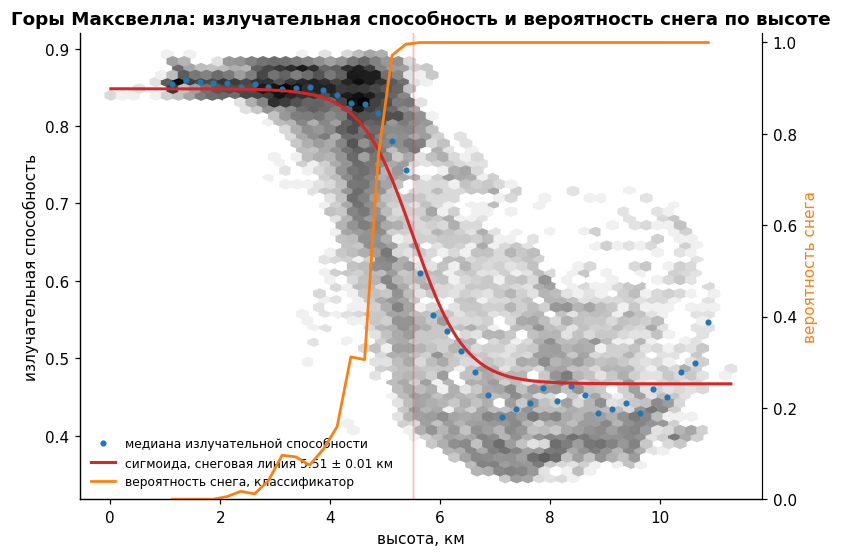

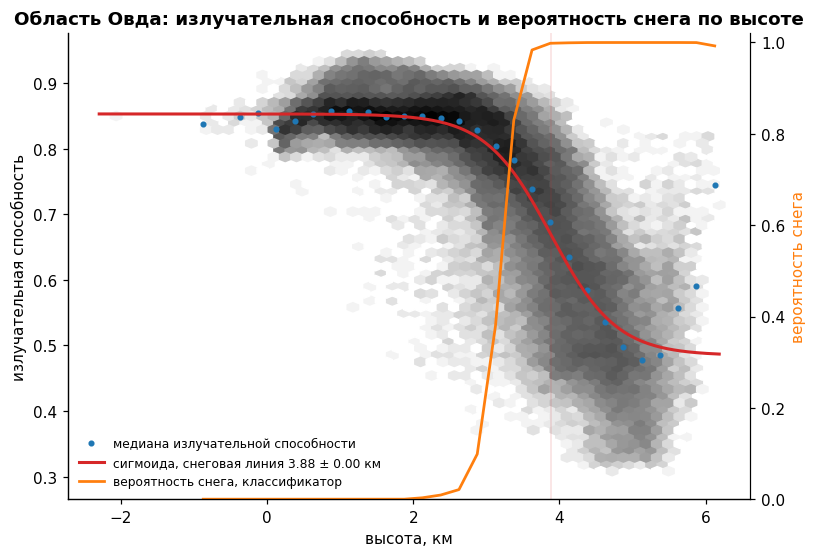

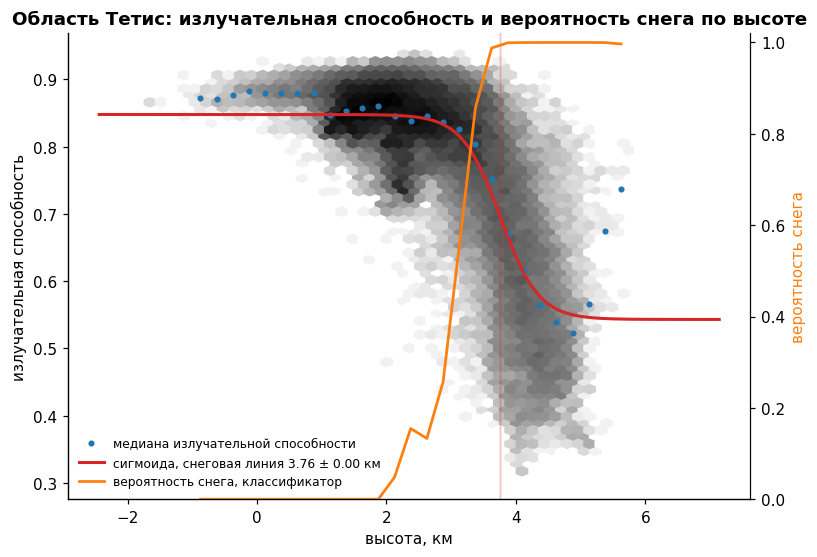

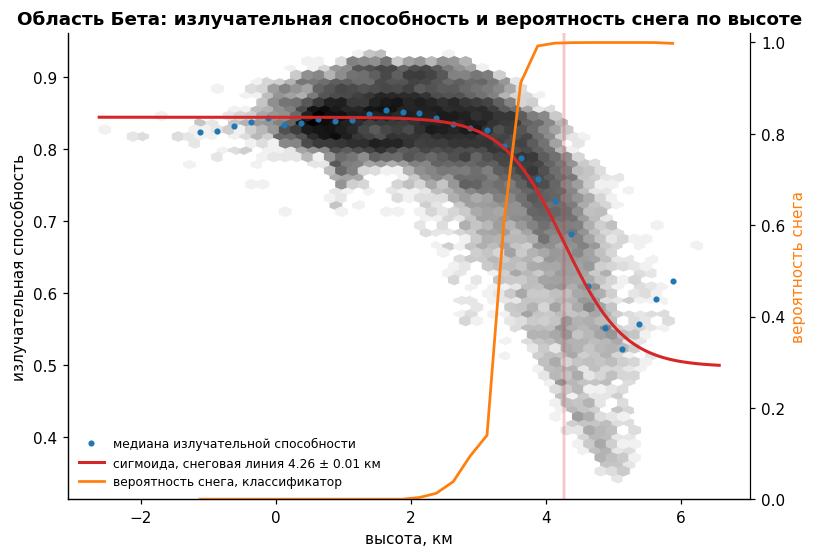

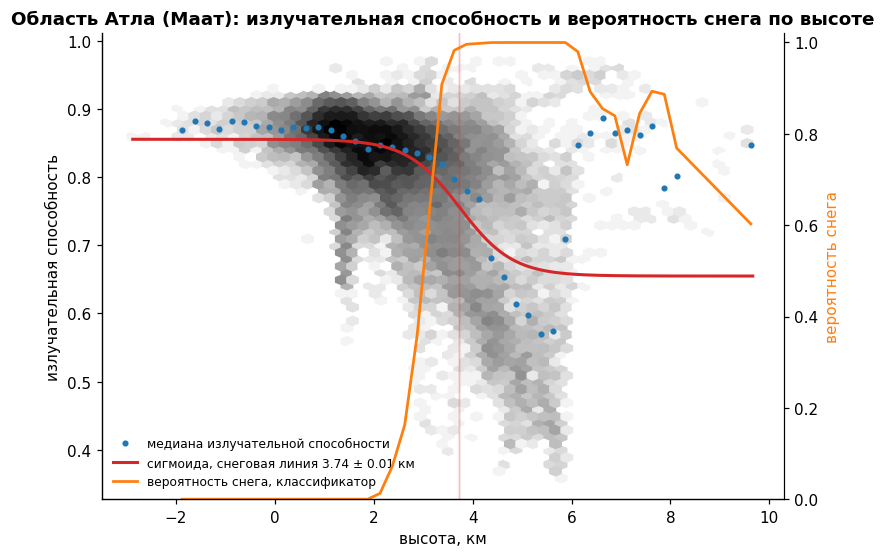

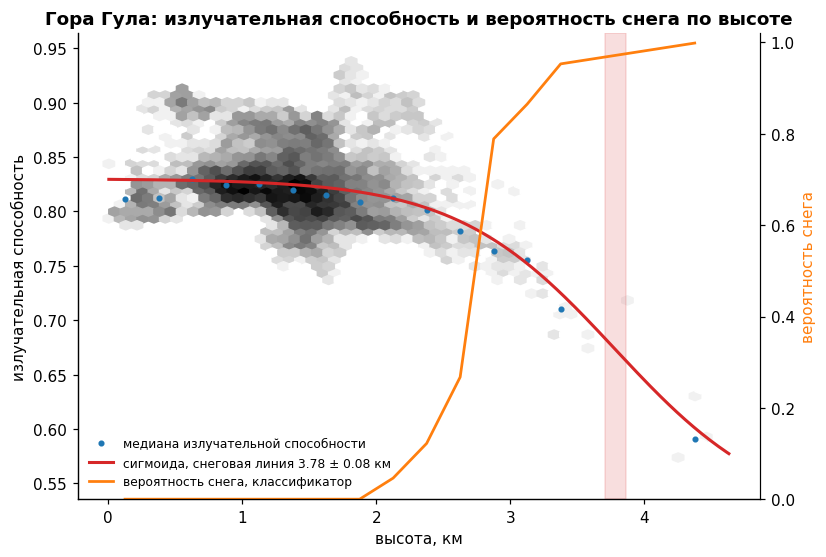

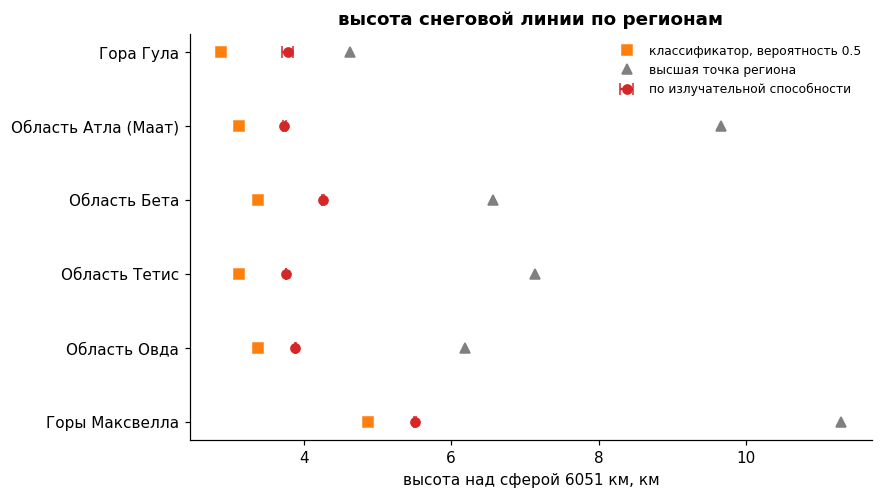

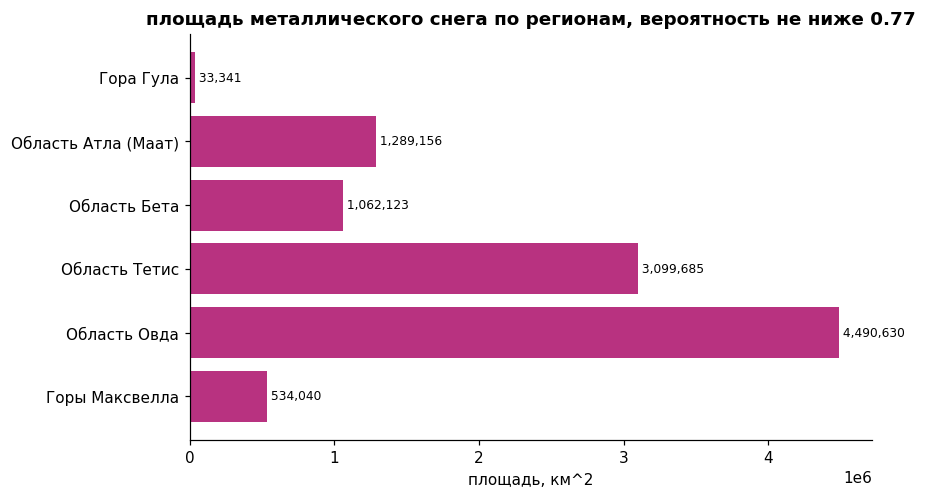

ячейка 6 завершена: results/snowline_by_region.csv


In [8]:
#=====================================================================
#ячейка 6 – высота снеговой линии по регионам
#запускать после ячейки 5
#для каждого высокогорья зависимость излучательной способности от высоты
#аппроксимируется сигмоидой: e(h) = e0 – Δ / (1 + exp(–(h – h_c)/w))
#h_c – высота середины перепада (снеговая линия), погрешность из ковариации подгонки
#независимо определяется высота, где вероятность снега от ml-модели (модели машинного
#обучения) пересекает 0.5
#результат: results/snowline_by_region.csv и картинки 06_*.png
#=====================================================================
from scipy.optimize import curve_fit

print_header("ячейка 6. снеговая линия по регионам")
F, S = load_npz("features"), load_npz("snow")
lat, lon, valid = F["lat"], F["lon"], F["valid"]
res = CFG["grid_res_deg"]
area = pixel_area_km2(lat, res) * np.ones((1, lon.size))
thr = json.loads((OUT_DIR / "snow_summary.json").read_text())["threshold"]
_TR = dict(zip("абвгдежзийклмнопрстуфхцчшщъыьэюя",
               ["a", "b", "v", "g", "d", "e", "zh", "z", "i", "y", "k", "l", "m", "n", "o", "p", "r",
                "s", "t", "u", "f", "kh", "ts", "ch", "sh", "sch", "", "y", "", "e", "yu", "ya"]))

COL_HC = "снеговая линия h_c, км"
COL_ERR = "σ h_c, км"
COL_ML = "ml: p(снег) = 0.5 на высоте, км"
COL_MAX = "максимальная высота, км"
COL_AREA = "площадь снега, км^2"


def file_slug(name):  #получить латинское имя файла из названия региона
    t = "".join(_TR.get(ch, ch) for ch in name.lower())
    return re.sub(r"[^a-z0-9]+", "_", t).strip("_")


def sigmoid(h, e0, d, hc, w):  #рассчитать сигмоиду перепада излучательной способности
    return e0 - d / (1 + np.exp(-(h - hc) / w))


def binned(x, y, step=0.25, min_n=15):  #рассчитать медианы y в интервалах x
    bins = np.arange(np.floor(np.nanmin(x)), np.ceil(np.nanmax(x)) + step, step)
    out = [((a + b) / 2, np.median(y[(x >= a) & (x < b)]), ((x >= a) & (x < b)).sum())
           for a, b in zip(bins[:-1], bins[1:])]
    return np.array([o for o in out if o[2] >= min_n]).reshape(-1, 3)


rows, FITS = [], {}
for name, box in REGIONS.items():
    m = region_mask(lat, lon, box) & valid
    h, e, p = F["elev_km"][m], F["emis"][m], S["snow_prob"][m]
    row = {"регион": name, "пикселей": int(m.sum()), COL_MAX: float(np.nanmax(h)) if m.any() else np.nan,
           COL_HC: np.nan, COL_ERR: np.nan, "перепад Δe": np.nan, "e0 ниже линии": np.nan}
    fit = None
    if m.sum() > 200 and np.nanmax(h) > 2:
        try:
            p0 = [np.percentile(e, 70), 0.25, np.percentile(h, 90), 0.3]
            popt, pcov = curve_fit(sigmoid, h, e, p0=p0, maxfev=20000,
                                   bounds=([0.4, 0.0, -1, 0.03], [1.0, 0.8, 12, 3.0]))
            perr = np.sqrt(np.diag(pcov))
            #перепад меньше 0.05 не считается аномалией
            if popt[1] > 0.05 and popt[2] < np.nanmax(h):
                fit = popt
                row.update({COL_HC: popt[2], COL_ERR: perr[2], "перепад Δe": popt[1], "e0 ниже линии": popt[0]})
        except (RuntimeError, ValueError):
            pass
    b = binned(h, p) if m.any() else np.empty((0, 3))
    cross = np.where((b[:-1, 1] < 0.5) & (b[1:, 1] >= 0.5))[0] if len(b) > 1 else []
    row[COL_ML] = float(b[cross[0] + 1, 0]) if len(cross) else np.nan
    sm = m & S["snow_mask"]
    row[COL_AREA] = float(area[sm].sum())
    row["доля региона под снегом, %"] = 100 * area[sm].sum() / max(area[m].sum(), 1)
    row["комментарий"] = "" if fit is not None else "перепад не выделяется: аномалии нет или мало данных"
    rows.append(row)
    FITS[name] = (h, e, p, fit)

SL = pd.DataFrame(rows)
SL.to_csv(OUT_DIR / "snowline_by_region.csv", index=False)
display(SL.round(3))
print("   по публикациям данных Magellan критическая высота составляет несколько км над средним радиусом "
      "и различается между регионами")

for name, (h, e, p, fit) in FITS.items():
    if h.size == 0:
        continue
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.hexbin(h, e, gridsize=55, bins="log", cmap="Greys", mincnt=1)
    b = binned(h, e)
    if len(b):
        ax.plot(b[:, 0], b[:, 1], "o", color="tab:blue", ms=3, label="медиана излучательной способности")
    if fit is not None:
        hh = np.linspace(h.min(), h.max(), 300)
        err = SL.set_index("регион").loc[name, COL_ERR]
        ax.plot(hh, sigmoid(hh, *fit), color="tab:red", lw=2, label=f"сигмоида, снеговая линия {fit[2]:.2f} ± {err:.2f} км")
        ax.axvspan(fit[2] - err, fit[2] + err, color="tab:red", alpha=0.15)
    ax2 = ax.twinx()
    bp = binned(h, p)
    if len(bp):
        ax2.plot(bp[:, 0], bp[:, 1], color="tab:orange", lw=1.8, label="вероятность снега, классификатор")
    ax2.set_ylim(0, 1.02)
    ax2.set_ylabel("вероятность снега", color="tab:orange")
    ax2.spines["right"].set_visible(True)
    ax.set_xlabel("высота, км")
    ax.set_ylabel("излучательная способность")
    ax.set_title(f"{name}: излучательная способность и вероятность снега по высоте")
    l1, l2 = ax.get_legend_handles_labels(), ax2.get_legend_handles_labels()
    ax.legend(l1[0] + l2[0], l1[1] + l2[1], fontsize=8, loc="lower left")
    savefig(fig, f"06_snowline_{file_slug(name)}")

ok = SL.dropna(subset=[COL_HC])
fig, ax = plt.subplots(figsize=(8, 4.8))
if len(ok):
    ypos = np.arange(len(ok))
    ax.errorbar(ok[COL_HC], ypos, xerr=ok[COL_ERR], fmt="o", color="tab:red", capsize=4,
                label="по излучательной способности")
    ax.plot(ok[COL_ML], ypos, "s", color="tab:orange", label="классификатор, вероятность 0.5")
    ax.plot(ok[COL_MAX], ypos, "^", color="grey", label="высшая точка региона")
    ax.set_yticks(ypos, ok["регион"])
    ax.legend(fontsize=8)
ax.set_xlabel("высота над сферой 6051 км, км")
ax.set_title("высота снеговой линии по регионам")
savefig(fig, "06_snowline_summary")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(SL["регион"], SL[COL_AREA], color="#b83280")
for yv, v in enumerate(SL[COL_AREA]):
    ax.text(v, yv, f" {v:,.0f}", va="center", fontsize=8)
ax.set_xlabel("площадь, км^2")
ax.set_title(f"площадь металлического снега по регионам, вероятность не ниже {thr:.2f}")
savefig(fig, "06_snow_area_by_region")
print("ячейка 6 завершена: results/snowline_by_region.csv")


  ячейка 7. итоговые результаты


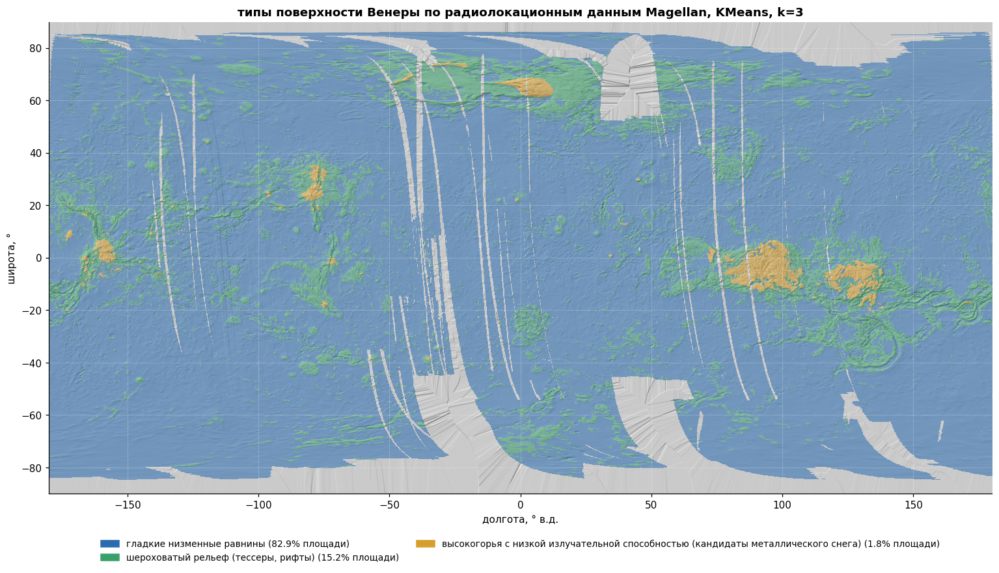

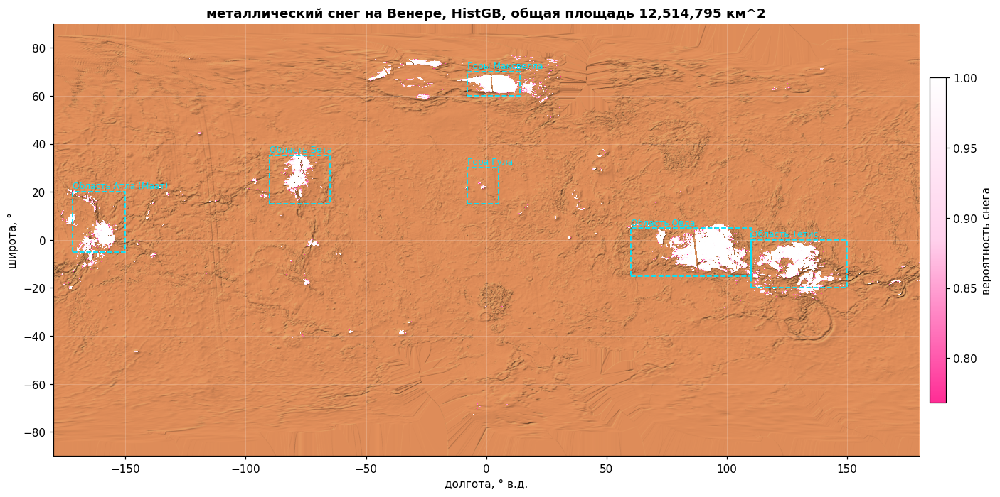

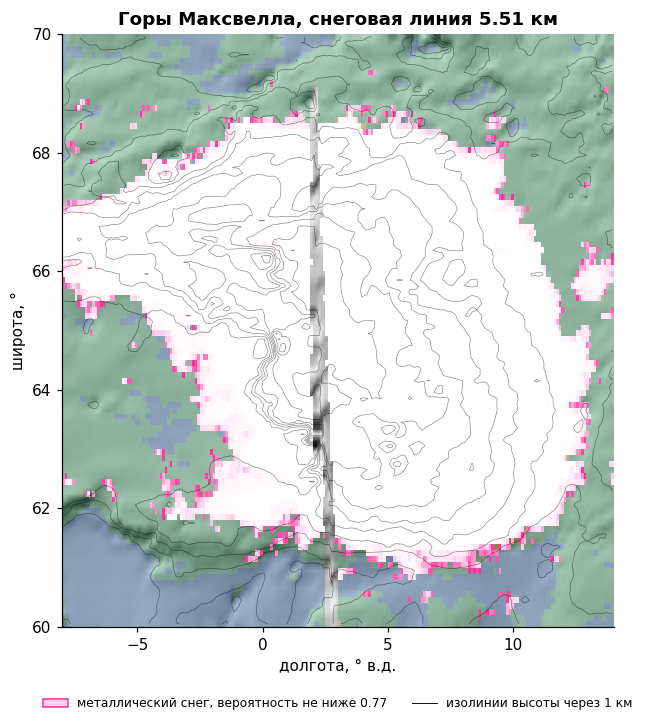

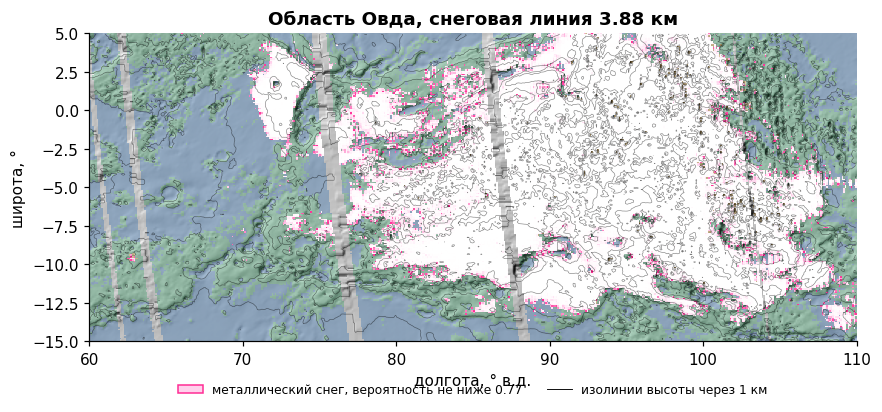

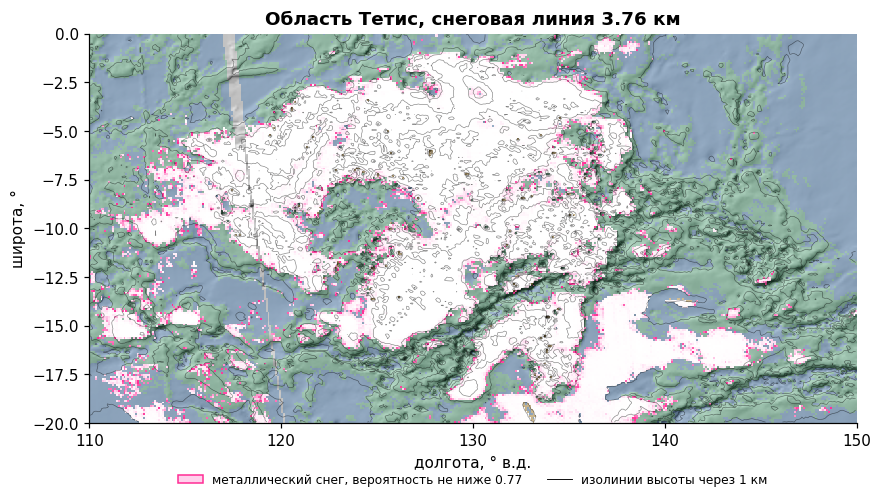

...

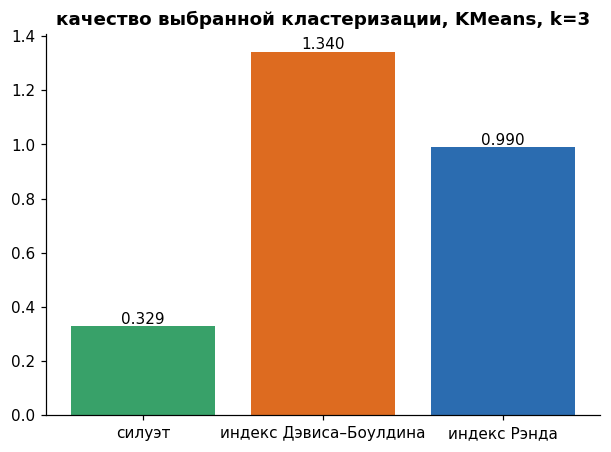

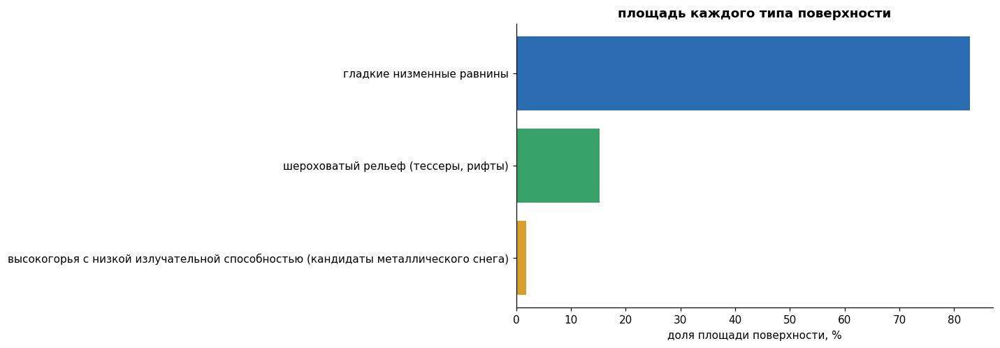

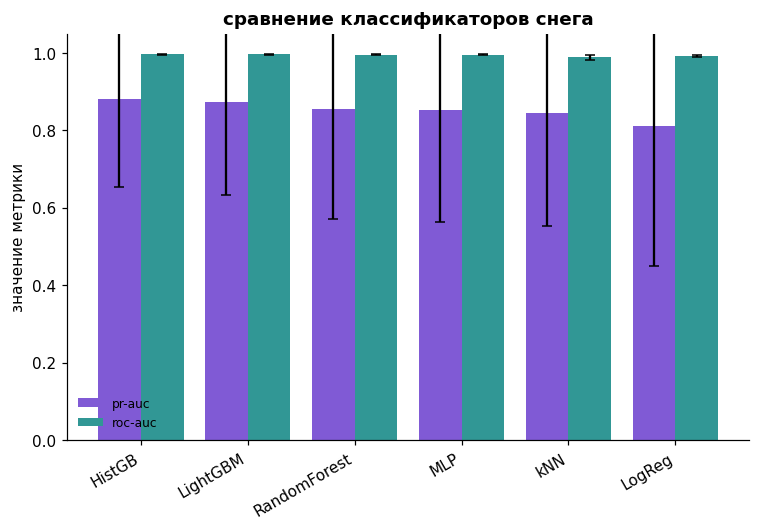

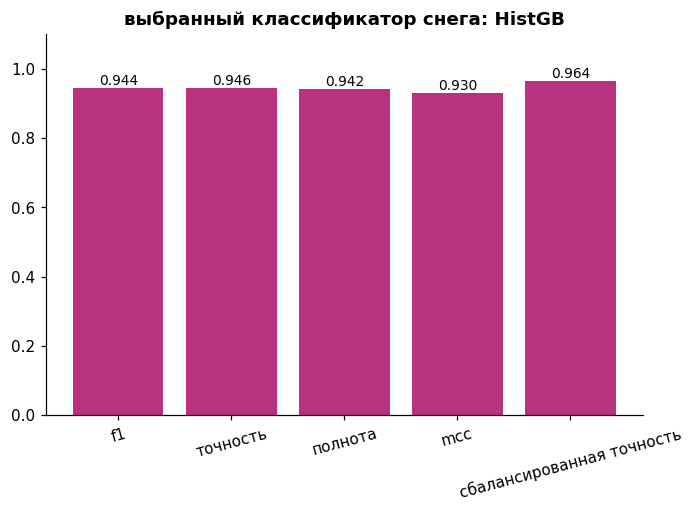

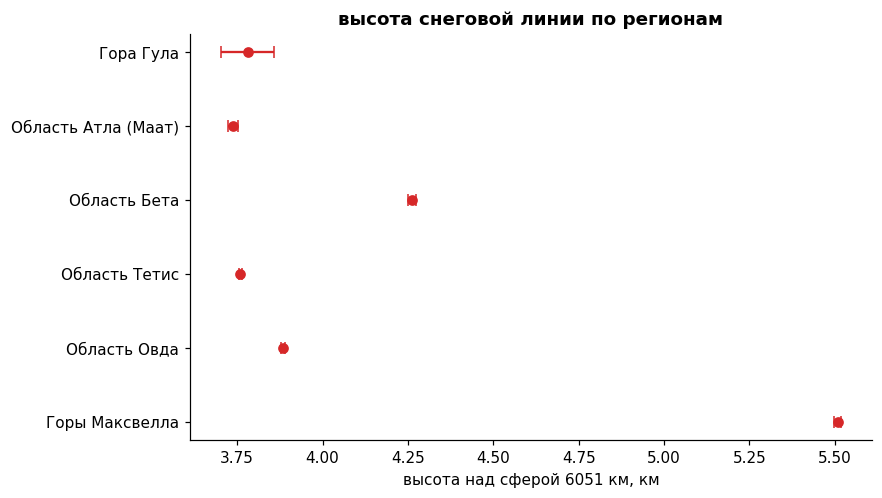


   итоговые файлы:
   anomaly_detector_metrics.csv                      0.00 мб
   bsr_track_validation.csv                          0.21 мб
   bsr_validation_summary.json                       0.00 мб
   cluster_profiles.csv                              0.00 мб
   clustering_metrics.csv                            0.01 мб
   clustering_summary.json                           0.00 мб
   region_gora_gula.csv                              1.01 мб
   region_gory_maksvella.csv                         0.91 мб
   region_oblast_atla_maat.csv                       2.44 мб
   region_oblast_beta.csv                            2.33 мб
   region_oblast_ovda.csv                            4.84 мб
   region_oblast_tetis.csv                           4.08 мб
   region_Гора_Гула.csv                              1.01 мб
   region_Горы_Максвелла.csv                         0.91 мб
   region_Область_Атла_Маат.csv                      2.44 мб
   region_Область_Бета.csv                           2.33 мб
   r

In [9]:
#=====================================================================
#ячейка 7 – итоговые карты, графики метрик и экспорт результатов
#запускать после ячейки 6
#каждый график сохраняется отдельной картинкой 07_*.png в папке figures
#экспорт: results/venus_results.npz и results/region_<имя>.csv – вход для 3d-моделей и сайта
#=====================================================================
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

print_header("ячейка 7. итоговые результаты")
F, C, S = load_npz("features"), load_npz("clusters"), load_npz("snow")
lat, lon, valid = F["lat"], F["lon"], F["valid"]
res = CFG["grid_res_deg"]
elev, clusters, prob, snow_mask = F["elev_km"], C["cluster_map"], S["snow_prob"], S["snow_mask"]
cmeta = json.loads((OUT_DIR / "clustering_summary.json").read_text())
smeta = json.loads((OUT_DIR / "snow_summary.json").read_text())
CMm = pd.read_csv(OUT_DIR / "clustering_metrics.csv")
SCm = pd.read_csv(OUT_DIR / "snow_classifier_metrics.csv")
SL = pd.read_csv(OUT_DIR / "snowline_by_region.csv")
K, names, colors, thr = cmeta["n_clusters"], cmeta["names"], cmeta["colors"], smeta["threshold"]
cmapK = mcolors.ListedColormap(colors)
hs = hillshade(elev, res)
snow_cmap = mcolors.LinearSegmentedColormap.from_list("snow", ["#ff2d95", "#ffd1ec", "#ffffff"])
COL_HC, COL_ERR = "снеговая линия h_c, км", "σ h_c, км"
_TR = dict(zip("абвгдежзийклмнопрстуфхцчшщъыьэюя",
               ["a", "b", "v", "g", "d", "e", "zh", "z", "i", "y", "k", "l", "m", "n", "o", "p", "r",
                "s", "t", "u", "f", "kh", "ts", "ch", "sh", "sch", "", "y", "", "e", "yu", "ya"]))


def file_slug(name):  #получить латинское имя файла из названия региона
    t = "".join(_TR.get(ch, ch) for ch in name.lower())
    return re.sub(r"[^a-z0-9]+", "_", t).strip("_")


def draw_regions(ax):  #нарисовать рамки и подписи регионов
    for name, b in REGIONS.items():
        ax.add_patch(Rectangle((b["lon"][0], b["lat"][0]), b["lon"][1] - b["lon"][0], b["lat"][1] - b["lat"][0],
                               fill=False, ec="#00e5ff", lw=1.2, ls="--"))
        ax.text(b["lon"][0], b["lat"][1] + 1.5, name, color="#00e5ff", fontsize=8)


fig, ax = plt.subplots(figsize=(17, 9.5))
ax.imshow(hs, extent=EXTENT, cmap="gray", interpolation="bilinear")
ax.imshow(np.ma.masked_less(clusters, 0), extent=EXTENT, cmap=cmapK, vmin=-0.5, vmax=K - 0.5,
          alpha=0.55, interpolation="nearest")
style_map(ax, f"типы поверхности Венеры по радиолокационным данным Magellan, {cmeta['best_config']}")
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=colors[c]) for c in range(K)],
          labels=[f"{names[c]} ({cmeta['area_share_pct'][c]:.1f}% площади)" for c in range(K)],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
savefig(fig, "07_surface_types_map")

fig, ax = plt.subplots(figsize=(17, 9))
ax.set_facecolor("black")
ax.imshow(hs, extent=EXTENT, cmap="copper", interpolation="bilinear", alpha=0.9)
im = ax.imshow(np.ma.masked_less(prob, thr), extent=EXTENT, cmap=snow_cmap, vmin=thr, vmax=1,
               interpolation="nearest")
draw_regions(ax)
style_map(ax, f"металлический снег на Венере, {smeta['best_classifier']}, "
              f"общая площадь {smeta['snow_area_km2']:,.0f} км^2")
fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01, label="вероятность снега")
savefig(fig, "07_metallic_snow_map")

sl = SL.set_index("регион")
for name, box in REGIONS.items():
    rs, cs = region_slices(lat, lon, box)
    ext = [lon[cs][0] - res / 2, lon[cs][-1] + res / 2, lat[rs][-1] - res / 2, lat[rs][0] + res / 2]
    e_reg = elev[rs, cs]
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(hillshade(e_reg, res, exag=12), extent=ext, cmap="gray", interpolation="bilinear")
    ax.imshow(np.ma.masked_less(clusters[rs, cs], 0), extent=ext, cmap=cmapK, vmin=-0.5, vmax=K - 0.5,
              alpha=0.35, interpolation="nearest")
    ax.imshow(np.ma.masked_less(prob[rs, cs], thr), extent=ext, cmap=snow_cmap, vmin=thr, vmax=1,
              interpolation="nearest")
    if np.isfinite(e_reg).sum() > 10:
        ax.contour(fill_nan_nearest(e_reg), levels=np.arange(0, 12, 1), extent=ext, origin="upper",
                   colors="k", linewidths=0.4, alpha=0.5)
    hc = sl.loc[name, COL_HC] if name in sl.index else np.nan
    ax.set_title(f"{name}, снеговая линия {hc:.2f} км" if np.isfinite(hc) else f"{name}, снеговая линия не выделена")
    ax.set_xlabel("долгота, ° в.д.")
    ax.set_ylabel("широта, °")
    #пропорции исправлены на косинус широты
    ax.set_aspect(1 / max(np.cos(np.deg2rad(np.mean(box["lat"]))), 0.2))
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.legend(handles=[Rectangle((0, 0), 1, 1, fc="#ffd1ec", ec="#ff2d95"), Line2D([0], [0], color="k", lw=0.6)],
              labels=[f"металлический снег, вероятность не ниже {thr:.2f}", "изолинии высоты через 1 км"],
              loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8)
    savefig(fig, f"07_region_{file_slug(name)}")

top = CMm.dropna(subset=["score"]).head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top["config"], top["score"],
        color=["#e53e3e" if c == cmeta["best_config"] else "#a0aec0" for c in top["config"]])
ax.set_xlabel("итоговый балл")
ax.set_title("рейтинг конфигураций кластеризации")
savefig(fig, "07_clustering_ranking")

cm = cmeta["metrics"]
vals = [cm["silhouette"], cm["davies_bouldin"], cm.get("stability_ari", np.nan)]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(["силуэт", "индекс Дэвиса–Боулдина", "индекс Рэнда"], vals, color=["#38a169", "#dd6b20", "#2b6cb0"])
for i, v in enumerate(vals):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
ax.set_title(f"качество выбранной кластеризации, {cmeta['best_config']}")
savefig(fig, "07_clustering_quality")

order = np.argsort(cmeta["area_share_pct"])
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh([names[i] for i in order], np.array(cmeta["area_share_pct"])[order], color=np.array(colors)[order])
ax.set_xlabel("доля площади поверхности, %")
ax.set_title("площадь каждого типа поверхности")
savefig(fig, "07_surface_type_areas")

xpos = np.arange(len(SCm))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(xpos - 0.2, SCm["pr-auc"], 0.4, yerr=SCm["pr-auc σ"], capsize=3, label="pr-auc", color="#805ad5")
ax.bar(xpos + 0.2, SCm["roc-auc"], 0.4, yerr=SCm["roc-auc σ"], capsize=3, label="roc-auc", color="#319795")
ax.set_xticks(xpos, SCm["model"], rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("значение метрики")
ax.set_title("сравнение классификаторов снега")
ax.legend(fontsize=8)
savefig(fig, "07_classifier_comparison")

best = SCm.iloc[0]
mm = ["f1", "точность", "полнота", "mcc", "сбалансированная точность"]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(mm, best[mm].values, color="#b83280")
for i, v in enumerate(best[mm].values):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 1.1)
ax.tick_params(axis="x", rotation=15)
ax.set_title(f"выбранный классификатор снега: {best['model']}")
savefig(fig, "07_classifier_quality")

ok = SL.dropna(subset=[COL_HC])
fig, ax = plt.subplots(figsize=(8, 4.8))
if len(ok):
    ax.errorbar(ok[COL_HC], np.arange(len(ok)), xerr=ok[COL_ERR], fmt="o", color="tab:red", capsize=4)
    ax.set_yticks(np.arange(len(ok)), ok["регион"])
ax.set_xlabel("высота над сферой 6051 км, км")
ax.set_title("высота снеговой линии по регионам")
savefig(fig, "07_snowline_by_region")

np.savez_compressed(OUT_DIR / "venus_results.npz", lat=lat, lon=lon, elev_km=elev,
                    cluster=clusters, snow_prob=prob, snow_mask=snow_mask, anomaly=S["anomaly"],
                    emis=F["emis"], refl_norm=F["refl_norm"], eps_refl=F["eps_refl"], slope=F["slope"])
for name, box in REGIONS.items():
    rs, cs = region_slices(lat, lon, box)
    LA, LO = np.meshgrid(lat[rs], lon[cs], indexing="ij")
    df = pd.DataFrame({"lat": LA.ravel(), "lon": LO.ravel(), "elev_km": elev[rs, cs].ravel(),
                       "cluster": clusters[rs, cs].ravel(), "snow_prob": prob[rs, cs].ravel()})
    df.dropna().to_csv(OUT_DIR / f"region_{file_slug(name)}.csv", index=False)

summary = {
    "data": "Magellan GxDR (GTDR, GEDR, GREDR, GSDR), NASA PDS Geosciences Node",
    "grid_res_deg": res,
    "clustering": cmeta,
    "snow": smeta,
    "snowline_by_region": SL.replace({np.nan: None}).to_dict(orient="records"),
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=float))

print("\n   итоговые файлы:")
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file():
        print(f"   {p.name:<45} {p.stat().st_size / 2**20:8.2f} мб")
print(f"\n   графики: {len(list(FIG_DIR.glob('*.png')))} png в папке {FIG_DIR.name}")
print("ячейка 7 завершена: venus_results.npz и region_*.csv – вход для 3d-моделей и сайта")

**ВИЗУАЛИЗАЦИЯ**

In [10]:
#=====================================================================
#ячейка 8 – подготовка к 3d-визуализации: слои, палитры, геометрия
#запускать после ячейки 7, нужен файл results/venus_results.npz
#палитры заданы опорными цветами, общими для plotly и текстур gltf (формат 3d-моделей для веба)
#небольшие пропуски покрытия Magellan заполняются ближайшими значениями только для визуализации,
#статистика и площади считаются по исходным массивам RES
#=====================================================================
for _m, _p in (("plotly", None), ("trimesh", None), ("PIL", "pillow"), ("ipywidgets", None)):
    _ensure(_m, _p)

import plotly.graph_objects as go
import plotly.io as pio
import ipywidgets as W
from PIL import Image
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

if IN_COLAB:
    pio.renderers.default = "colab"

print_header("ячейка 8. подготовка данных для 3d")
RES = dict(np.load(OUT_DIR / "venus_results.npz"))
LAT, LON = RES["lat"], RES["lon"]
GRID_RES = float(abs(LAT[0] - LAT[1]))
CMETA = json.loads((OUT_DIR / "clustering_summary.json").read_text())
SMETA = json.loads((OUT_DIR / "snow_summary.json").read_text())
SNOWLINE = pd.read_csv(OUT_DIR / "snowline_by_region.csv").set_index("регион")
DEFAULT_THR = round(float(SMETA["threshold"]), 2)
AREA = pixel_area_km2(LAT, GRID_RES) * np.ones((1, LON.size))
ELEV_FILLED = fill_nan_nearest(RES["elev_km"].astype(np.float32))

STOPS = {
    "venus":   ["#1b0f08", "#4a2410", "#8a4a1c", "#c98a3a", "#ecc98a", "#fff6e5"],
    "snow":    ["#ff2d95", "#ff8fcf", "#ffd6ef", "#ffffff"],
    "inferno": ["#000004", "#420a68", "#932667", "#dd513a", "#fca50a", "#fcffa4"],
    "plasma":  ["#0d0887", "#6a00a8", "#b12a90", "#e16462", "#fca636", "#f0f921"],
    "cividis": ["#00224e", "#35456c", "#666970", "#948e77", "#c8b866", "#fee838"],
    "viridis": ["#440154", "#414487", "#2a788e", "#22a884", "#7ad151", "#fde725"],
    "hot":     ["#0b0b0b", "#5c0d0d", "#b3200e", "#f2600b", "#ffc23d", "#ffffcc"],
}


def plotly_scale(name):  #получить палитру plotly из опорных цветов
    s = STOPS[name]
    return [[i / (len(s) - 1), c] for i, c in enumerate(s)]


def mpl_cmap(name):  #получить палитру matplotlib из опорных цветов
    return LinearSegmentedColormap.from_list(name, STOPS[name])


K_CL = CMETA["n_clusters"]
CL_NAMES, CL_COLORS = CMETA["names"], CMETA["colors"]


def categorical_scale(colors):  #построить ступенчатую палитру plotly для целых 0..k-1
    k, out = len(colors), []
    for i, c in enumerate(colors):
        out += [[i / k, c], [(i + 1) / k, c]]
    return out


def _lim(a, lo=1, hi=99):  #рассчитать диапазон шкалы по перцентилям
    v = a[np.isfinite(a)]
    return [float(np.percentile(v, lo)), float(np.percentile(v, hi))]


LAYERS = {
    "elev":      {"title": "высота, км", "data": ELEV_FILLED, "cmap": "venus",
                  "range": _lim(RES["elev_km"], 0.1, 100)},
    "snow_prob": {"title": "вероятность снега", "data": RES["snow_prob"], "cmap": "inferno", "range": [0, 1]},
    "anomaly":   {"title": "перцентиль аномальности", "data": RES["anomaly"], "cmap": "hot", "range": [0.5, 1]},
    "cluster":   {"title": "тип поверхности", "data": RES["cluster"].astype(np.float32), "cmap": None,
                  "range": [-0.5, K_CL - 0.5], "categorical": True},
    "emis":      {"title": "излучательная способность", "data": RES["emis"], "cmap": "plasma",
                  "range": _lim(RES["emis"], 0.1, 99.5)},
    "eps_refl":  {"title": "диэлектрическая проницаемость", "data": RES["eps_refl"], "cmap": "inferno",
                  "range": _lim(RES["eps_refl"], 1, 99.9)},
    "refl_norm": {"title": "отражательная способность Френеля", "data": RES["refl_norm"], "cmap": "cividis",
                  "range": _lim(RES["refl_norm"], 1, 99.9)},
    "slope":     {"title": "rms-уклон, °", "data": RES["slope"], "cmap": "viridis", "range": _lim(RES["slope"], 1, 99)},
}
LAYERS["cluster"]["data"][RES["cluster"] < 0] = np.nan
for _k, _L in LAYERS.items():
    _L["data"] = fill_nan_nearest(_L["data"].astype(np.float32))
SNOW_SOURCES = {"вероятность классификатора": "snow_prob", "аномальность без учителя": "anomaly"}
LAYER_OPTIONS = [(v["title"], k) for k, v in LAYERS.items()]


def colorscale_of(key):  #получить палитру слоя
    L = LAYERS[key]
    return categorical_scale(CL_COLORS[:K_CL]) if L.get("categorical") else plotly_scale(L["cmap"])


def colorbar_of(key):  #получить настройки цветовой шкалы слоя
    L = LAYERS[key]
    cb = dict(title=dict(text=L["title"], side="right", font=dict(color="#ddd")), len=0.7, thickness=14,
              tickfont=dict(color="#ddd"), x=1.0)
    if L.get("categorical"):
        cb.update(tickvals=list(range(K_CL)), ticktext=[n[:30] + ("..." if len(n) > 30 else "") for n in CL_NAMES])
    return cb


def layer_rgb(key, arr=None):  #перевести слой в rgb uint8 (беззнаковое 8-битное целое) для текстур gltf
    L = LAYERS[key]
    a = L["data"] if arr is None else arr
    if L.get("categorical"):
        rgba = ListedColormap(CL_COLORS[:K_CL])(np.clip(np.nan_to_num(a, nan=0), 0, K_CL - 1).astype(int))
    else:
        lo, hi = L["range"]
        rgba = mpl_cmap(L["cmap"])(np.clip((np.nan_to_num(a, nan=lo) - lo) / (hi - lo), 0, 1))
    rgb = (rgba[..., :3] * 255).astype(np.uint8)
    rgb[~np.isfinite(a)] = (40, 40, 40)
    return rgb


def blend_snow(rgb, snow_arr, thr):  #наложить снег на rgb: чем выше вероятность, тем светлее
    out = rgb.astype(np.float32)
    s = np.nan_to_num(snow_arr, nan=0)
    m = s >= thr
    w = np.clip((s - thr) / max(1 - thr, 1e-6), 0, 1) * 0.6 + 0.4
    snow_rgb = mpl_cmap("snow")(w)[..., :3] * 255
    out[m] = out[m] * (1 - w[m, None] * 0.9) + snow_rgb[m] * (w[m, None] * 0.9)
    return out.astype(np.uint8)


def coarsen(a, f, categorical=False):  #уменьшить сетку в f раз: среднее по блокам или выборка для категорий
    if f <= 1:
        return a
    H, Wd = (a.shape[0] // f) * f, (a.shape[1] // f) * f
    if categorical:
        return a[:H, :Wd][f // 2::f, f // 2::f]
    b = a[:H, :Wd].reshape(H // f, f, Wd // f, f)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return np.nanmean(b, axis=(1, 3))


def coarsen_axes(f):  #уменьшить оси широты и долготы в f раз
    if f <= 1:
        return LAT, LON
    H, Wd = (LAT.size // f) * f, (LON.size // f) * f
    return LAT[:H].reshape(-1, f).mean(1), LON[:Wd].reshape(-1, f).mean(1)


def sphere_xyz(lat_deg, lon_deg, elev_km, exag, lift=0.0):  #перевести широту, долготу и высоту в координаты на сфере радиуса 1
    la, lo = np.deg2rad(lat_deg), np.deg2rad(lon_deg)
    #lift – подъем в долях радиуса, чтобы слой снега лежал над рельефом
    r = 1.0 + exag * np.nan_to_num(elev_km) / R_KM + lift
    return r * np.cos(la) * np.cos(lo), r * np.cos(la) * np.sin(lo), r * np.sin(la)


def snow_area_km2(snow_arr, thr, mask=None):  #рассчитать площадь снега при пороге, км^2
    m = np.isfinite(snow_arr) & (snow_arr >= thr)
    if mask is not None:
        m &= mask
    return float(AREA[m].sum())


def region_data(name, pad_deg=0.0):  #получить срезы региона на сетке
    box = REGIONS[name]
    b = {"lat": (box["lat"][0] - pad_deg, box["lat"][1] + pad_deg),
         "lon": (box["lon"][0] - pad_deg, box["lon"][1] + pad_deg)}
    return region_slices(LAT, LON, b)


def snowline_of(name):  #получить высоту снеговой линии региона из ячейки 6
    try:
        v = float(SNOWLINE.loc[name, "снеговая линия h_c, км"])
        return v if np.isfinite(v) else None
    except (KeyError, ValueError):
        return None


_TR = dict(zip("абвгдежзийклмнопрстуфхцчшщъыьэюя",
               ["a", "b", "v", "g", "d", "e", "zh", "z", "i", "y", "k", "l", "m", "n", "o", "p", "r",
                "s", "t", "u", "f", "kh", "ts", "ch", "sh", "sch", "", "y", "", "e", "yu", "ya"]))


def slug(name):  #получить латинское имя файла: горы Максвелла – gory_maksvella
    s = "".join(_TR.get(ch, ch) for ch in name.lower())
    return re.sub(r"[^a-z0-9]+", "_", s).strip("_")


EXPORT_DIR = OUT_DIR / "export_3d"
EXPORT_DIR.mkdir(exist_ok=True)

print(f"   сетка {LAT.size} * {LON.size} (шаг {GRID_RES}°), слоев: {len(LAYERS)}, регионов: {len(REGIONS)}")
print(f"   порог снега по умолчанию: {DEFAULT_THR} (модель {SMETA['best_classifier']})")
display(pd.DataFrame([{"слой": k, "название": v["title"], "диапазон": np.round(v["range"], 3)}
                      for k, v in LAYERS.items()]))
print("ячейка 8 завершена")


  ячейка 8. подготовка данных для 3d
   сетка 1800 * 3600 (шаг 0.10000000000000853°), слоев: 8, регионов: 6
   порог снега по умолчанию: 0.77 (модель HistGB)


,слой,название,диапазон
0,elev,"высота, км","[-1.124, 11.285]"
1,snow_prob,вероятность снега,"[0, 1]"
2,anomaly,перцентиль аномальности,"[0.5, 1.0]"
3,cluster,тип поверхности,"[-0.5, 2.5]"
4,emis,излучательная способность,"[0.419, 0.913]"
5,eps_refl,диэлектрическая проницаемость,"[2.795, 50.734]"
6,refl_norm,отражательная способность Френеля,"[0.063, 0.568]"
7,slope,"rms-уклон, °","[0.8, 8.125]"


ячейка 8 завершена


In [11]:
#=====================================================================
#ячейка 9 – интерактивный 3d-глобус Венеры
#запускать после ячейки 8
#элементы управления в Colab и в html-копии globe_preview.html одинаковые:
#слой поверхности, источник снега (ml-классификатор (классификатор машинного обучения)
#или детектор аномалий), порог снега, показ снега, режим слоев (рельеф и снег,
#только рельеф, только снег), вертикальное преувеличение рельефа, регион для поворота
#камеры, детализация сетки (1° – быстро, 0.25° – подробно), рамки регионов
#рельеф и снег – разные поверхности: снег строится только в ячейках выше порога
#и приподнят над рельефом на SNOW_LIFT радиуса
#html-копия работает без Colab, библиотека plotly загружается из интернета
#управление мышью: вращение, колесо – масштаб
#=====================================================================
import base64

ALL_PLANET = "вся планета"
SNOW_LIFT = 0.01
HTML_RES = [r for r in (1.0, 0.5, 0.25) if r >= GRID_RES - 1e-9]
PROPER_WORDS = {"френеля": "Френеля", "fresnel": "Fresnel", "венера": "Венера", "венеры": "Венеры",
                "magellan": "Magellan", "магеллан": "Магеллан", "максвелла": "Максвелла"}


def proper_name(name):  #написать имя собственное с заглавных букв
    return re.sub(r"(^|[\s(])(\w)", lambda m: m.group(1) + m.group(2).upper(), name)


def text_case(s):  #перевести подпись в нижний регистр с сохранением имен собственных
    s = s.lower()
    for low, up in PROPER_WORDS.items():
        s = re.sub(rf"\b{low}\b", up, s)
    return s


def region_outline_ll(name, n=60):  #получить широты и долготы рамки региона
    b = REGIONS[name]
    la0, la1 = b["lat"]; lo0, lo1 = b["lon"]
    lats = np.concatenate([np.full(n, la0), np.linspace(la0, la1, n), np.full(n, la1), np.linspace(la1, la0, n)])
    lons = np.concatenate([np.linspace(lo0, lo1, n), np.full(n, lo1), np.linspace(lo1, lo0, n), np.full(n, lo0)])
    return lats, lons


def camera_for(name):  #рассчитать положение камеры над регионом
    if name not in REGIONS:
        return dict(eye=dict(x=1.6, y=1.0, z=0.9), up=dict(x=0, y=0, z=1))
    b = REGIONS[name]
    la, lo = np.deg2rad(np.mean(b["lat"])), np.deg2rad(np.mean(b["lon"]))
    d = 1.75
    return dict(eye=dict(x=d * np.cos(la) * np.cos(lo), y=d * np.cos(la) * np.sin(lo), z=d * np.sin(la)),
                up=dict(x=0, y=0, z=1))


def globe_title(layer, snow_source, thr, exag):  #сформировать заголовок глобуса
    area = snow_area_km2(RES[snow_source], thr)
    return (f"Венера: {text_case(LAYERS[layer]['title'])}; снег при p >= {thr:.2f}: {area:,.0f} км^2; "
            f"вертикальное преувеличение {exag}*")


def make_globe(layer="elev", snow_source="snow_prob", thr=DEFAULT_THR, show_snow=True,
               exag=40, res_deg=1.0, focus=ALL_PLANET, show_regions=True, mode="both"):  #построить глобус для Colab
    f = max(1, int(round(res_deg / GRID_RES)))
    L = LAYERS[layer]
    lat_c, lon_c = coarsen_axes(f)
    LA, LO = np.meshgrid(lat_c, lon_c, indexing="ij")
    #замыкание шва на долготе 180°, чтобы на глобусе не было щели
    wrap = lambda a: np.concatenate([a, a[:, :1]], axis=1)
    LO = np.concatenate([LO, LO[:, :1] + 360], axis=1)
    LA = wrap(LA)
    elev = wrap(coarsen(ELEV_FILLED, f))
    col = wrap(coarsen(L["data"], f, L.get("categorical", False)))
    x, y, z = sphere_xyz(LA, LO, elev, exag)

    traces = [go.Surface(
        x=x, y=y, z=z, surfacecolor=col, colorscale=colorscale_of(layer),
        cmin=L["range"][0], cmax=L["range"][1], colorbar=colorbar_of(layer),
        lighting=dict(ambient=0.55, diffuse=0.8, specular=0.08, roughness=0.9, fresnel=0.1),
        lightposition=dict(x=1e5, y=5e4, z=3e4), hoverinfo="skip", name="рельеф",
        visible=(mode != "snow"))]

    snow = wrap(coarsen(RES[snow_source], f))
    if show_snow and mode != "relief" and layer not in ("snow_prob", "anomaly"):
        #ячейки ниже порога удаляются из поверхности снега через nan в координатах
        mask = np.nan_to_num(snow) >= thr
        xs, ys, zs = sphere_xyz(LA, LO, elev, exag, lift=SNOW_LIFT)
        xs, ys, zs = (np.where(mask, a, np.nan) for a in (xs, ys, zs))
        traces.append(go.Surface(x=xs, y=ys, z=zs, surfacecolor=np.where(mask, snow, np.nan),
                                 colorscale=plotly_scale("snow")[::-1], cmin=thr, cmax=1, showscale=False,
                                 hoverinfo="skip", name="снег",
                                 lighting=dict(ambient=0.8, diffuse=0.5, specular=0.4)))

    if show_regions:
        for name in REGIONS:
            label = proper_name(name)
            la, lo = region_outline_ll(name)
            ox, oy, oz = sphere_xyz(la, lo, np.full(la.shape, 12.0), exag)
            traces.append(go.Scatter3d(x=ox, y=oy, z=oz, mode="lines", hoverinfo="name", name=label,
                                       line=dict(color="#00e5ff" if name == focus else "#7fd8e6",
                                                 width=6 if name == focus else 2), showlegend=False))
            b = REGIONS[name]
            tx, ty, tz = sphere_xyz(np.array([b["lat"][1] + 3]), np.array([np.mean(b["lon"])]), np.array([14.0]), exag)
            traces.append(go.Scatter3d(x=tx, y=ty, z=tz, mode="text", text=[label], hoverinfo="skip",
                                       textfont=dict(color="#00e5ff", size=12), showlegend=False))

    axis = dict(visible=False, showbackground=False)
    fig = go.Figure(traces)
    fig.update_layout(
        title=dict(text=globe_title(layer, snow_source, thr, exag), font=dict(color="#eee", size=15), x=0.02),
        paper_bgcolor="#05060a", height=780, margin=dict(l=0, r=0, t=45, b=0),
        scene=dict(xaxis=axis, yaxis=axis, zaxis=axis, aspectmode="data", bgcolor="#05060a",
                   camera=camera_for(focus)),
    )
    return fig


def _b64(arr):  #закодировать массив в base64 (текстовая кодировка двоичных данных)
    return base64.b64encode(np.ascontiguousarray(arr).tobytes()).decode("ascii")


def _quant8(a, lo, hi):  #упаковать значения в uint8 (беззнаковое 8-битное целое), 255 – нет данных
    q = np.round((np.clip(a, lo, hi) - lo) / max(hi - lo, 1e-9) * 254)
    q = np.where(np.isfinite(a), q, 255)
    return q.astype(np.uint8)


def html_payload():  #подготовить данные и настройки для html-копии
    grids = {}
    for res in HTML_RES:
        f = max(1, int(round(res / GRID_RES)))
        lat_c, lon_c = coarsen_axes(f)
        wrap = lambda a: np.concatenate([a, a[:, :1]], axis=1)
        elev = wrap(coarsen(ELEV_FILLED, f))
        emin, emax = float(np.nanmin(elev)), float(np.nanmax(elev))
        g = {"lat": lat_c.round(4).tolist(), "lon": np.append(lon_c, lon_c[0] + 360).round(4).tolist(),
             "nr": int(elev.shape[0]), "nc": int(elev.shape[1]), "emin": emin, "emax": emax,
             "elev": _b64(np.round((elev - emin) / max(emax - emin, 1e-9) * 65535).astype("<u2")),
             "layers": {}, "snow": {}}
        for k, L in LAYERS.items():
            cat = L.get("categorical", False)
            d = wrap(coarsen(L["data"], f, cat))
            if cat:
                q = np.where(np.isfinite(d), np.clip(np.nan_to_num(d), 0, 254), 255).astype(np.uint8)
            else:
                q = _quant8(d, *L["range"])
            g["layers"][k] = _b64(q)
        for src in SNOW_SOURCES.values():
            g["snow"][src] = _b64(_quant8(wrap(coarsen(RES[src], f)), 0.0, 1.0))
        grids[str(res)] = g
    thr_grid = np.round(np.arange(0.05, 0.995, 0.01), 2)
    layers = {}
    for k, L in LAYERS.items():
        cb = colorbar_of(k)
        cb["title"]["text"] = text_case(cb["title"]["text"])
        if "ticktext" in cb:
            cb["ticktext"] = [text_case(t) for t in cb["ticktext"]]
        layers[k] = {"title": text_case(L["title"]), "colorscale": colorscale_of(k),
                     "cmin": float(L["range"][0]), "cmax": float(L["range"][1]),
                     "categorical": bool(L.get("categorical", False)), "colorbar": cb}
    regions = {}
    for name, b in REGIONS.items():
        la, lo = region_outline_ll(name)
        regions[name] = {"label": proper_name(name), "lat": la.round(3).tolist(), "lon": lo.round(3).tolist(),
                         "tlat": float(b["lat"][1] + 3), "tlon": float(np.mean(b["lon"])),
                         "camera": camera_for(name)}
    return {
        "R_KM": R_KM, "lift": SNOW_LIFT, "grids": grids, "layers": layers, "regions": regions,
        "layer_options": [[text_case(t), k] for t, k in LAYER_OPTIONS],
        "snow_options": [[text_case(t), k] for t, k in SNOW_SOURCES.items()],
        "snow_scale": plotly_scale("snow")[::-1],
        "thr_grid": thr_grid.tolist(),
        "area": {src: [round(snow_area_km2(RES[src], t)) for t in thr_grid] for src in SNOW_SOURCES.values()},
        "default": {"layer": "elev", "source": "snow_prob", "thr": float(DEFAULT_THR), "exag": 40,
                    "res": str(HTML_RES[0]), "focus": ALL_PLANET, "camera": camera_for(ALL_PLANET)},
        "all_planet": ALL_PLANET,
    }


HTML_TEMPLATE = r"""<!doctype html>
<html lang="ru"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Венера: глобус рельефа и металлического снега</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
body{margin:0;background:#05060a;color:#ddd;font:14px/1.4 -apple-system,Segoe UI,Roboto,Arial,sans-serif}
#panel{display:flex;flex-wrap:wrap;gap:10px 18px;padding:12px 16px;background:#0d1018;border-bottom:1px solid #222a38}
#panel label{display:flex;align-items:center;gap:6px;white-space:nowrap}
select,input[type=range]{background:#1b1f2a;color:#ddd;border:1px solid #3a4050;border-radius:4px;padding:2px 4px}
input[type=range]{padding:0;width:150px}
.val{min-width:34px;color:#9fd}
#status{color:#888;margin-left:auto}
#globe{width:100%;height:calc(100vh - 110px);min-height:520px}
</style></head><body>
<div id="panel">
 <label>слой <select id="layer"></select></label>
 <label>снег <select id="source"></select></label>
 <label>регион <select id="focus"></select></label>
 <label>порог <input id="thr" type="range" min="0.05" max="0.99" step="0.01"><span class="val" id="thrv"></span></label>
 <label><input id="show" type="checkbox" checked> показать снег</label>
 <label>режим <select id="mode"><option value="both">рельеф и снег</option><option value="relief">только рельеф</option><option value="snow">только снег</option></select></label>
 <label>рельеф × <input id="exag" type="range" min="0" max="120" step="5"><span class="val" id="exagv"></span></label>
 <label>сетка <select id="res"></select></label>
 <label><input id="regions" type="checkbox" checked> рамки регионов</label>
 <span id="status"></span>
</div>
<div id="globe"></div>
<script>
const D = __PAYLOAD__;
const $ = id => document.getElementById(id);
const cache = {};
function bytes(b64){const s=atob(b64);const u=new Uint8Array(s.length);for(let i=0;i<s.length;i++)u[i]=s.charCodeAt(i);return u;}
function grid(res){
  if(cache[res]) return cache[res];
  const g=D.grids[res], n=g.nr*g.nc;
  const e16=new Uint16Array(bytes(g.elev).buffer), elev=new Float32Array(n);
  for(let i=0;i<n;i++) elev[i]=g.emin+e16[i]/65535*(g.emax-g.emin);
  const cphi=g.lat.map(v=>Math.cos(v*Math.PI/180)), sphi=g.lat.map(v=>Math.sin(v*Math.PI/180));
  const clam=g.lon.map(v=>Math.cos(v*Math.PI/180)), slam=g.lon.map(v=>Math.sin(v*Math.PI/180));
  return cache[res]={g,n,elev,cphi,sphi,clam,slam,layers:{},snow:{}};
}
function layerVals(G,key){
  if(G.layers[key]) return G.layers[key];
  const q=bytes(G.g.layers[key]), L=D.layers[key], out=new Array(G.n);
  for(let i=0;i<G.n;i++) out[i]= q[i]===255?null:(L.categorical?q[i]:L.cmin+q[i]/254*(L.cmax-L.cmin));
  return G.layers[key]=out;
}
function snowVals(G,src){
  if(G.snow[src]) return G.snow[src];
  const q=bytes(G.g.snow[src]), out=new Float32Array(G.n);
  for(let i=0;i<G.n;i++) out[i]= q[i]===255?NaN:q[i]/254;
  return G.snow[src]=out;
}
function to2d(flat,nr,nc){const o=new Array(nr);for(let r=0;r<nr;r++){o[r]=Array.prototype.slice.call(flat,r*nc,(r+1)*nc);}return o;}
function sphere(lat,lon,h,exag,lift){
  const p=lat*Math.PI/180,l=lon*Math.PI/180,r=1+exag*h/D.R_KM+lift;
  return [r*Math.cos(p)*Math.cos(l),r*Math.cos(p)*Math.sin(l),r*Math.sin(p)];
}
function surfaceXYZ(G,exag,lift,mask){
  const {g,elev,cphi,sphi,clam,slam}=G, nr=g.nr, nc=g.nc;
  const X=new Array(nr),Y=new Array(nr),Z=new Array(nr);
  for(let r=0;r<nr;r++){
    const xr=new Array(nc),yr=new Array(nc),zr=new Array(nc);
    for(let c=0;c<nc;c++){
      const i=r*nc+c;
      if(mask && !mask[i]){xr[c]=yr[c]=zr[c]=null;continue;}
      const rad=1+exag*elev[i]/D.R_KM+lift;
      xr[c]=rad*cphi[r]*clam[c]; yr[c]=rad*cphi[r]*slam[c]; zr[c]=rad*sphi[r];
    }
    X[r]=xr;Y[r]=yr;Z[r]=zr;
  }
  return [X,Y,Z];
}
function areaFor(src,thr){const i=Math.round((thr-D.thr_grid[0])/0.01);return D.area[src][Math.max(0,Math.min(D.area[src].length-1,i))];}
let lastFocus=null;
function draw(){
  const t0=performance.now();
  const layer=$("layer").value, src=$("source").value, focus=$("focus").value, mode=$("mode").value;
  const thr=parseFloat($("thr").value), exag=parseInt($("exag").value), res=$("res").value;
  $("thrv").textContent=thr.toFixed(2); $("exagv").textContent=exag;
  const G=grid(res), L=D.layers[layer], nr=G.g.nr, nc=G.g.nc;
  const traces=[];
  const [X,Y,Z]=surfaceXYZ(G,exag,0,null);
  traces.push({type:"surface",x:X,y:Y,z:Z,surfacecolor:to2d(layerVals(G,layer),nr,nc),
    colorscale:L.colorscale,cmin:L.cmin,cmax:L.cmax,colorbar:L.colorbar,hoverinfo:"skip",name:"рельеф",
    lighting:{ambient:0.55,diffuse:0.8,specular:0.08,roughness:0.9,fresnel:0.1},
    lightposition:{x:1e5,y:5e4,z:3e4},visible:mode!=="snow"});
  if($("show").checked && mode!=="relief" && layer!=="snow_prob" && layer!=="anomaly"){
    const s=snowVals(G,src), mask=new Uint8Array(G.n), col=new Array(G.n);
    for(let i=0;i<G.n;i++){mask[i]=s[i]>=thr?1:0;col[i]=mask[i]?s[i]:null;}
    const [SX,SY,SZ]=surfaceXYZ(G,exag,D.lift,mask);
    traces.push({type:"surface",x:SX,y:SY,z:SZ,surfacecolor:to2d(col,nr,nc),colorscale:D.snow_scale,
      cmin:thr,cmax:1,showscale:false,hoverinfo:"skip",name:"снег",
      lighting:{ambient:0.8,diffuse:0.5,specular:0.4}});
  }
  if($("regions").checked){
    for(const [name,R] of Object.entries(D.regions)){
      const pts=R.lat.map((la,i)=>sphere(la,R.lon[i],12,exag,0));
      traces.push({type:"scatter3d",mode:"lines",x:pts.map(p=>p[0]),y:pts.map(p=>p[1]),z:pts.map(p=>p[2]),
        hoverinfo:"name",name:R.label,showlegend:false,
        line:{color:name===focus?"#00e5ff":"#7fd8e6",width:name===focus?6:2}});
      const tp=sphere(R.tlat,R.tlon,14,exag,0);
      traces.push({type:"scatter3d",mode:"text",x:[tp[0]],y:[tp[1]],z:[tp[2]],text:[R.label],
        hoverinfo:"skip",showlegend:false,textfont:{color:"#00e5ff",size:12}});
    }
  }
  const area=areaFor(src,thr).toLocaleString("ru-RU");
  const axis={visible:false,showbackground:false};
  const layout={title:{text:`Венера: ${L.title}; снег при p >= ${thr.toFixed(2)}: ${area} км^2; вертикальное преувеличение ${exag}×`,
      font:{color:"#eee",size:15},x:0.02},
    paper_bgcolor:"#05060a",margin:{l:0,r:0,t:45,b:0},uirevision:focus,
    scene:{xaxis:axis,yaxis:axis,zaxis:axis,aspectmode:"data",bgcolor:"#05060a"}};
  if(focus!==lastFocus){layout.scene.camera=(D.regions[focus]||{}).camera||D.default.camera;lastFocus=focus;}
  Plotly.react("globe",traces,layout,{responsive:true});
  $("status").textContent=`построено за ${Math.round(performance.now()-t0)} мс`;
}
function fill(sel,opts,val){for(const [t,v] of opts){const o=document.createElement("option");o.textContent=t;o.value=v;sel.appendChild(o);}sel.value=val;}
fill($("layer"),D.layer_options,D.default.layer);
fill($("source"),D.snow_options,D.default.source);
fill($("focus"),[[D.all_planet,D.all_planet]].concat(Object.entries(D.regions).map(([k,R])=>[R.label,k])),D.default.focus);
fill($("res"),Object.keys(D.grids).map(r=>[r==="1.0"?"1° (быстро)":(r==="0.25"?"0.25° (подробно)":r+"°"),r]),D.default.res);
$("thr").value=D.default.thr; $("exag").value=D.default.exag;
for(const id of ["layer","source","focus","mode","res","show","regions"]) $(id).addEventListener("change",draw);
for(const id of ["thr","exag"]){ $(id).addEventListener("change",draw); $(id).addEventListener("input",()=>{$("thrv").textContent=parseFloat($("thr").value).toFixed(2);$("exagv").textContent=$("exag").value;}); }
draw();
</script></body></html>
"""


def export_globe_html(path):  #сохранить html-копию глобуса со всеми элементами управления
    payload = json.dumps(html_payload(), ensure_ascii=False, separators=(",", ":"))
    path.write_text(HTML_TEMPLATE.replace("__PAYLOAD__", payload), encoding="utf-8")
    return path


g_layer = W.Dropdown(options=[(text_case(t), k) for t, k in LAYER_OPTIONS], value="elev", description="слой",
                     layout=W.Layout(width="360px"))
g_source = W.Dropdown(options=[(text_case(t), k) for t, k in SNOW_SOURCES.items()], value="snow_prob",
                      description="снег", layout=W.Layout(width="330px"))
g_thr = W.FloatSlider(value=DEFAULT_THR, min=0.05, max=0.99, step=0.01, description="порог",
                      continuous_update=False, readout_format=".2f")
g_show = W.Checkbox(value=True, description="показать снег")
g_mode = W.Dropdown(options=[("рельеф и снег", "both"), ("только рельеф", "relief"), ("только снег", "snow")],
                    value="both", description="режим")
g_exag = W.IntSlider(value=40, min=0, max=120, step=5, description="рельеф ×", continuous_update=False)
g_res = W.Dropdown(options=[("1° (быстро)", 1.0), ("0.5°", 0.5), ("0.25° (подробно)", 0.25)],
                   value=1.0, description="сетка")
g_focus = W.Dropdown(options=[(ALL_PLANET, ALL_PLANET)] + [(proper_name(n), n) for n in REGIONS], value=ALL_PLANET,
                     description="регион", layout=W.Layout(width="330px"))
g_reg = W.Checkbox(value=True, description="рамки регионов")
g_out = W.Output()


def _redraw(*_):  #перерисовать глобус по значениям виджетов
    with g_out:
        g_out.clear_output(wait=True)
        make_globe(g_layer.value, g_source.value, g_thr.value, g_show.value, g_exag.value,
                   g_res.value, g_focus.value, g_reg.value, g_mode.value).show()


for w_ in (g_layer, g_source, g_thr, g_show, g_mode, g_exag, g_res, g_focus, g_reg):
    w_.observe(_redraw, names="value")

display(W.VBox([W.HBox([g_layer, g_source, g_focus]),
                W.HBox([g_thr, g_show, g_mode]),
                W.HBox([g_exag, g_res, g_reg]), g_out]))
_redraw()

html_path = export_globe_html(EXPORT_DIR / "globe_preview.html")
print(f"   html-копия: {EXPORT_DIR.name}/{html_path.name}, {html_path.stat().st_size / 2**20:.1f} мб")

   html-копия: export_3d/globe_preview.html, 29.7 мб


In [12]:
#=====================================================================
#ячейка 10 – детальные 2.5d-модели высокогорий Венеры
#запускать после ячейки 8
#для выбранного региона выводятся две отдельные картинки: 2.5d-рельеф и вид сверху
#элементы управления в Colab и в html-копиях одинаковые: регион, слой поверхности
#(переключатель текстур), источник снега, порог снега, показ снега, режим слоев
#(рельеф и снег, только рельеф, только снег), вертикальное преувеличение, плоскость
#снеговой линии и ее уровень (по умолчанию высота h_c из ячейки 6), изолинии высоты
#снег – отдельная поверхность только в ячейках выше порога, приподнятая над рельефом
#html-копии: regions_preview.html со всеми регионами и region_<имя>.html для каждого региона,
#работают без Colab, библиотека plotly загружается из интернета
#=====================================================================
import base64

KM_PER_DEG = R_KM * np.pi / 180
#больше точек замедляет браузер, крупные регионы прореживаются
MAX_POINTS = 60_000
ALL_REGIONS = "все регионы"
PROPER_WORDS = {"френеля": "Френеля", "fresnel": "Fresnel", "венера": "Венера", "венеры": "Венеры",
                "magellan": "Magellan", "магеллан": "Магеллан", "максвелла": "Максвелла"}


def proper_name(name):  #написать имя собственное с заглавных букв
    return re.sub(r"(^|[\s(])(\w)", lambda m: m.group(1) + m.group(2).upper(), name)


def text_case(s):  #перевести подпись в нижний регистр с сохранением имен собственных
    s = s.lower()
    for low, up in PROPER_WORDS.items():
        s = re.sub(rf"\b{low}\b", up, s)
    return s


_TR = dict(zip("абвгдеёжзийклмнопрстуфхцчшщъыьэюя",
               ["a", "b", "v", "g", "d", "e", "e", "zh", "z", "i", "y", "k", "l", "m", "n", "o", "p", "r",
                "s", "t", "u", "f", "kh", "ts", "ch", "sh", "sch", "", "y", "", "e", "yu", "ya"]))


def file_slug(name):  #получить латинское имя файла из названия региона
    t = "".join(_TR.get(ch, ch) for ch in name.lower())
    return re.sub(r"[^a-z0-9]+", "_", t).strip("_")


def _factor(name):  #рассчитать шаг прореживания региона
    rs, cs = region_data(name)
    return max(1, int(np.ceil(np.sqrt(LAT[rs].size * LON[cs].size / MAX_POINTS))))


def _region_arrays(name, layer, snow_source):  #получить прореженные массивы региона
    rs, cs = region_data(name)
    lat_r, lon_r = LAT[rs], LON[cs]
    f = _factor(name)
    cut = lambda a, cat=False: coarsen(a[rs, cs], f, cat)
    if f > 1:
        lat_r = lat_r[: (lat_r.size // f) * f].reshape(-1, f).mean(1)
        lon_r = lon_r[: (lon_r.size // f) * f].reshape(-1, f).mean(1)
    return (lat_r, lon_r, cut(ELEV_FILLED), cut(LAYERS[layer]["data"], LAYERS[layer].get("categorical", False)),
            cut(RES[snow_source]), cut(RES["elev_km"]))


def _aspect(lat_r, lon_r, elev, exag):  #рассчитать пропорции осей с учетом широты и преувеличения
    xk = (lon_r.max() - lon_r.min()) * KM_PER_DEG * np.cos(np.deg2rad(lat_r.mean()))
    yk = (lat_r.max() - lat_r.min()) * KM_PER_DEG
    zk = max(np.nanmax(elev) - np.nanmin(elev), 0.1) * exag
    m = max(xk, yk)
    return dict(x=xk / m, y=yk / m, z=max(zk / m, 0.02))


def _snow_offset(elev):  #рассчитать подъем слоя снега над рельефом, км
    return 0.02 + 0.01 * float(np.nanmax(elev) - np.nanmin(elev))


def _terrain_traces(name, layer, snow_source, thr, show_snow, exag, plane, plane_level, contours,
                    mode="both", show_scale=True, hover=True):  #собрать поверхности рельефа, снега и плоскости
    L = LAYERS[layer]
    lat_r, lon_r, elev, col, snow, elev_raw = _region_arrays(name, layer, snow_source)
    title = text_case(L["title"])
    text = None
    if hover:
        fmt = (lambda v: text_case(CL_NAMES[int(v)]) if np.isfinite(v) else "нет данных") if L.get("categorical") \
            else (lambda v: f"{v:.3f}" if np.isfinite(v) else "нет данных")
        text = [[f"{title}: {fmt(c)}<br>p(снег): {s:.2f}" if np.isfinite(s) else f"{title}: {fmt(c)}"
                 for c, s in zip(cr, sr)] for cr, sr in zip(col, snow)]
    tr = [go.Surface(
        x=lon_r, y=lat_r, z=elev, surfacecolor=col, colorscale=colorscale_of(layer),
        cmin=L["range"][0], cmax=L["range"][1], showscale=show_scale,
        colorbar=colorbar_of(layer) if show_scale else None, text=text,
        hovertemplate=("долгота %{x:.2f}°<br>широта %{y:.2f}°<br>высота %{z:.2f} км<br>%{text}<extra></extra>")
        if hover else None, hoverinfo=None if hover else "skip",
        lighting=dict(ambient=0.45, diffuse=0.85, specular=0.1, roughness=0.85),
        lightposition=dict(x=-1e4, y=1e4, z=2e4),
        contours=dict(z=dict(show=contours, start=np.floor(np.nanmin(elev)), end=np.ceil(np.nanmax(elev)),
                             size=1, color="rgba(0,0,0,0.45)", width=1)),
        name="рельеф", visible=(mode != "snow"))]
    if show_snow and mode != "relief" and layer not in ("snow_prob", "anomaly"):
        #ячейки ниже порога удаляются из поверхности снега через nan по высоте
        mask = np.nan_to_num(snow) >= thr
        tr.append(go.Surface(x=lon_r, y=lat_r, z=np.where(mask, elev + _snow_offset(elev), np.nan),
                             surfacecolor=np.where(mask, snow, np.nan),
                             colorscale=plotly_scale("snow")[::-1], cmin=thr, cmax=1, showscale=False,
                             hoverinfo="skip", name="снег",
                             lighting=dict(ambient=0.8, diffuse=0.5, specular=0.5)))
    if plane and plane_level is not None:
        tr.append(go.Surface(x=lon_r[[0, -1]], y=lat_r[[0, -1]], z=np.full((2, 2), plane_level),
                             colorscale=[[0, "#4fc3f7"], [1, "#4fc3f7"]], showscale=False, opacity=0.25,
                             hoverinfo="skip", name="снеговая линия"))
    return tr, (lat_r, lon_r, elev, col, snow, elev_raw)


def region_stats(name, snow_source, thr, plane_level):  #рассчитать статистику региона
    rs, cs = region_data(name)
    snow, elev, emis = RES[snow_source][rs, cs], RES["elev_km"][rs, cs], RES["emis"][rs, cs]
    area, m = AREA[rs, cs], np.isfinite(elev)
    sm = m & (np.nan_to_num(snow) >= thr)
    hc = snowline_of(name)
    above = m & (elev >= plane_level) if plane_level is not None else m & False
    return {
        "регион": proper_name(name),
        "максимальная высота": f"{np.nanmax(elev):.2f} км",
        "снеговая линия h_c (ячейка 6)": f"{hc:.2f} км" if hc else "не выделена",
        f"площадь снега при p >= {thr:.2f}": f"{area[sm].sum():,.0f} км^2",
        "доля региона под снегом": f"{100 * area[sm].sum() / max(area[m].sum(), 1):.2f} %",
        "площадь выше плоскости": f"{area[above].sum():,.0f} км^2" if plane_level is not None else "плоскость скрыта",
        "излучательная способность выше и ниже плоскости":
            f"{np.nanmean(emis[above]):.3f} и {np.nanmean(emis[m & ~above]):.3f}" if above.any() else "плоскость скрыта",
    }


def make_region(name, layer="elev", snow_source="snow_prob", thr=DEFAULT_THR, show_snow=True,
                exag=6, plane=True, plane_level=None, contours=True, mode="both"):  #построить 2.5d-рельеф региона
    if plane_level is None:
        plane_level = snowline_of(name)
    tr, (lat_r, lon_r, elev, *_) = _terrain_traces(
        name, layer, snow_source, thr, show_snow, exag, plane, plane_level, contours, mode)
    axis = lambda t: dict(title=t, color="#ccc", backgroundcolor="#0b0d14", gridcolor="#2a2f3a")
    fig = go.Figure(tr)
    fig.update_layout(
        title=dict(text=f"{proper_name(name)}: {text_case(LAYERS[layer]['title'])}, вертикальное преувеличение {exag}×",
                   font=dict(color="#eee", size=15), x=0.02),
        paper_bgcolor="#05060a", height=680, margin=dict(l=0, r=10, t=50, b=10),
        font=dict(color="#ddd"), showlegend=False,
        scene=dict(xaxis=axis("долгота, ° в.д."), yaxis=axis("широта, °"), zaxis=axis("высота, км"),
                   aspectmode="manual", aspectratio=_aspect(lat_r, lon_r, elev, exag),
                   camera=dict(eye=dict(x=-1.3, y=-1.5, z=0.9))),
    )
    return fig


def make_topview(name, layer="elev", snow_source="snow_prob", thr=DEFAULT_THR, plane_level=None):  #построить вид сверху
    if plane_level is None:
        plane_level = snowline_of(name)
    L = LAYERS[layer]
    lat_r, lon_r, elev, col, snow, _ = _region_arrays(name, layer, snow_source)
    fig = go.Figure()
    fig.add_trace(go.Heatmap(x=lon_r, y=lat_r, z=col, colorscale=colorscale_of(layer), zmin=L["range"][0],
                             zmax=L["range"][1], colorbar=colorbar_of(layer), hoverinfo="skip"))
    fig.add_trace(go.Contour(x=lon_r, y=lat_r, z=np.nan_to_num(snow), contours=dict(
        start=thr, end=thr, size=1, coloring="none"), line=dict(color="white", width=2),
        showscale=False, hoverinfo="skip", name=f"граница снега, p = {thr:.2f}", showlegend=True))
    if plane_level is not None:
        fig.add_trace(go.Contour(x=lon_r, y=lat_r, z=elev, contours=dict(
            start=plane_level, end=plane_level, size=1, coloring="none"),
            line=dict(color="#4fc3f7", width=1.5, dash="dot"), showscale=False, hoverinfo="skip",
            name=f"изолиния снеговой линии, {plane_level:.2f} км", showlegend=True))
    fig.update_xaxes(title_text="долгота, ° в.д.", color="#ccc")
    fig.update_yaxes(title_text="широта, °", color="#ccc",
                     scaleanchor="x", scaleratio=1 / np.cos(np.deg2rad(lat_r.mean())))
    fig.update_layout(title=dict(text=f"{proper_name(name)}: вид сверху", font=dict(color="#eee", size=15), x=0.02),
                      paper_bgcolor="#05060a", plot_bgcolor="#05060a", height=560,
                      margin=dict(l=10, r=10, t=50, b=10), font=dict(color="#ddd"),
                      legend=dict(orientation="h", y=-0.15))
    return fig


def _b64(arr):  #закодировать массив в base64 (текстовая кодировка двоичных данных)
    return base64.b64encode(np.ascontiguousarray(arr).tobytes()).decode("ascii")


def _quant8(a, lo, hi):  #упаковать значения в uint8 (беззнаковое 8-битное целое), 255 – нет данных
    q = np.round((np.clip(a, lo, hi) - lo) / max(hi - lo, 1e-9) * 254)
    return np.where(np.isfinite(a), q, 255).astype(np.uint8)


def region_payload(name):  #подготовить данные региона для html-копии
    rs, cs = region_data(name)
    f = _factor(name)
    lat_r, lon_r, elev, *_ = _region_arrays(name, "elev", "snow_prob")
    emin, emax = float(np.nanmin(elev)), float(np.nanmax(elev))
    raw = coarsen(RES["elev_km"][rs, cs], f)
    area = coarsen(AREA[rs, cs], f) * f * f
    p = {"label": proper_name(name), "lat": lat_r.round(4).tolist(), "lon": lon_r.round(4).tolist(),
         "nr": int(elev.shape[0]), "nc": int(elev.shape[1]), "emin": emin, "emax": emax,
         "elev": _b64(np.round((elev - emin) / max(emax - emin, 1e-9) * 65535).astype("<u2")),
         "valid": _b64(np.isfinite(raw).astype(np.uint8)),
         "area": _b64(np.nan_to_num(area).astype("<f4")),
         "emis": _b64(_quant8(coarsen(RES["emis"][rs, cs], f), 0.0, 1.0)),
         "snowline": snowline_of(name), "layers": {}, "snow": {}}
    for k, L in LAYERS.items():
        cat = L.get("categorical", False)
        d = coarsen(L["data"][rs, cs], f, cat)
        p["layers"][k] = _b64(np.where(np.isfinite(d), np.clip(np.nan_to_num(d), 0, 254), 255).astype(np.uint8)
                              if cat else _quant8(d, *L["range"]))
    for src in SNOW_SOURCES.values():
        p["snow"][src] = _b64(_quant8(coarsen(RES[src][rs, cs], f), 0.0, 1.0))
    return p


def layers_payload():  #подготовить описание слоев для html-копии
    out = {}
    for k, L in LAYERS.items():
        cb = colorbar_of(k)
        cb["title"]["text"] = text_case(cb["title"]["text"])
        if "ticktext" in cb:
            cb["ticktext"] = [text_case(t) for t in cb["ticktext"]]
        out[k] = {"title": text_case(L["title"]), "colorscale": colorscale_of(k),
                  "cmin": float(L["range"][0]), "cmax": float(L["range"][1]),
                  "categorical": bool(L.get("categorical", False)), "colorbar": cb,
                  "names": [text_case(n) for n in CL_NAMES] if L.get("categorical") else None}
    return out


HTML_TEMPLATE = r"""<!doctype html>
<html lang="ru"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITLE__</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
body{margin:0;background:#05060a;color:#ddd;font:14px/1.4 -apple-system,Segoe UI,Roboto,Arial,sans-serif}
#panel{display:flex;flex-wrap:wrap;gap:10px 18px;padding:12px 16px;background:#0d1018;border-bottom:1px solid #222a38}
#panel label{display:flex;align-items:center;gap:6px;white-space:nowrap}
select,input[type=range]{background:#1b1f2a;color:#ddd;border:1px solid #3a4050;border-radius:4px;padding:2px 4px}
input[type=range]{padding:0;width:140px}
.val{min-width:34px;color:#9fd}
#status{color:#888;margin-left:auto}
#main{display:grid;grid-template-columns:minmax(0,2fr) minmax(0,1fr);gap:8px;padding:8px}
#terrain{height:680px}#top{height:520px}
#stats td{padding:2px 10px}#stats td:first-child{color:#888}
@media (max-width:1000px){#main{grid-template-columns:1fr}}
</style></head><body>
<div id="panel">
 <label id="regionbox">регион <select id="region"></select></label>
 <label>слой <select id="layer"></select></label>
 <label>снег <select id="source"></select></label>
 <label>порог <input id="thr" type="range" min="0.05" max="0.99" step="0.01"><span class="val" id="thrv"></span></label>
 <label><input id="show" type="checkbox" checked> показать снег</label>
 <label>режим <select id="mode"><option value="both">рельеф и снег</option><option value="relief">только рельеф</option><option value="snow">только снег</option></select></label>
 <label>рельеф * <input id="exag" type="range" min="1" max="30" step="1"><span class="val" id="exagv"></span></label>
 <label><input id="plane" type="checkbox" checked> плоскость снеговой линии</label>
 <label>уровень, км <input id="level" type="range" min="-1" max="11" step="0.1"><span class="val" id="levelv"></span></label>
 <label><input id="cont" type="checkbox" checked> изолинии</label>
 <span id="status"></span>
</div>
<div id="main"><div id="terrain"></div><div><div id="top"></div><table id="stats"></table></div></div>
<script>
const D = __PAYLOAD__;
const $ = id => document.getElementById(id);
const cache = {};
function bytes(b64){const s=atob(b64);const u=new Uint8Array(s.length);for(let i=0;i<s.length;i++)u[i]=s.charCodeAt(i);return u;}
function region(key){
  if(cache[key]) return cache[key];
  const R=D.regions[key], n=R.nr*R.nc;
  const e16=new Uint16Array(bytes(R.elev).buffer), elev=new Float32Array(n);
  for(let i=0;i<n;i++) elev[i]=R.emin+e16[i]/65535*(R.emax-R.emin);
  const em=bytes(R.emis), emis=new Float32Array(n);
  for(let i=0;i<n;i++) emis[i]=em[i]===255?NaN:em[i]/254;
  return cache[key]={R,n,elev,valid:bytes(R.valid),area:new Float32Array(bytes(R.area).buffer),emis,layers:{},snow:{}};
}
function layerVals(G,key){
  if(G.layers[key]) return G.layers[key];
  const q=bytes(G.R.layers[key]), L=D.layers[key], out=new Array(G.n);
  for(let i=0;i<G.n;i++) out[i]= q[i]===255?null:(L.categorical?q[i]:L.cmin+q[i]/254*(L.cmax-L.cmin));
  return G.layers[key]=out;
}
function snowVals(G,src){
  if(G.snow[src]) return G.snow[src];
  const q=bytes(G.R.snow[src]), out=new Float32Array(G.n);
  for(let i=0;i<G.n;i++) out[i]= q[i]===255?NaN:q[i]/254;
  return G.snow[src]=out;
}
function to2d(get,nr,nc){const o=new Array(nr);for(let r=0;r<nr;r++){const row=new Array(nc);for(let c=0;c<nc;c++)row[c]=get(r*nc+c);o[r]=row;}return o;}
function fmt(v,d){return v.toLocaleString("ru-RU",{maximumFractionDigits:d,minimumFractionDigits:d});}
function aspect(R,exag){
  const lat=R.lat, lon=R.lon, mlat=lat.reduce((a,b)=>a+b,0)/lat.length;
  const xk=(Math.max(...lon)-Math.min(...lon))*D.km_per_deg*Math.cos(mlat*Math.PI/180);
  const yk=(Math.max(...lat)-Math.min(...lat))*D.km_per_deg, zk=Math.max(R.emax-R.emin,0.1)*exag, m=Math.max(xk,yk);
  return {x:xk/m,y:yk/m,z:Math.max(zk/m,0.02)};
}
let lastRegion=null;
function setLevelDefault(){const R=D.regions[$("region").value];$("level").value=(R.snowline!==null?R.snowline:3.5).toFixed(1);}
function draw(){
  const t0=performance.now();
  const key=$("region").value, layer=$("layer").value, src=$("source").value, mode=$("mode").value;
  const thr=parseFloat($("thr").value), exag=parseInt($("exag").value), level=parseFloat($("level").value);
  const plane=$("plane").checked, cont=$("cont").checked;
  $("thrv").textContent=thr.toFixed(2); $("exagv").textContent=exag; $("levelv").textContent=level.toFixed(1);
  const G=region(key), R=G.R, L=D.layers[layer], nr=R.nr, nc=R.nc;
  const col=layerVals(G,layer), s=snowVals(G,src);
  const Z=to2d(i=>G.elev[i],nr,nc), C=to2d(i=>col[i],nr,nc);
  const fv=v=>v===null?"нет данных":(L.categorical?L.names[v]:fmt(v,3));
  const T=to2d(i=>`${L.title}: ${fv(col[i])}`+(isNaN(s[i])?"":`<br>p(снег): ${fmt(s[i],2)}`),nr,nc);
  const traces=[{type:"surface",x:R.lon,y:R.lat,z:Z,surfacecolor:C,colorscale:L.colorscale,cmin:L.cmin,cmax:L.cmax,
    colorbar:L.colorbar,text:T,hovertemplate:"долгота %{x:.2f}°<br>широта %{y:.2f}°<br>высота %{z:.2f} км<br>%{text}<extra></extra>",
    lighting:{ambient:0.45,diffuse:0.85,specular:0.1,roughness:0.85},lightposition:{x:-1e4,y:1e4,z:2e4},
    contours:{z:{show:cont,start:Math.floor(R.emin),end:Math.ceil(R.emax),size:1,color:"rgba(0,0,0,0.45)",width:1}},
    name:"рельеф",visible:mode!=="snow"}];
  if($("show").checked && mode!=="relief" && layer!=="snow_prob" && layer!=="anomaly"){
    const off=0.02+0.01*(R.emax-R.emin);
    traces.push({type:"surface",x:R.lon,y:R.lat,z:to2d(i=>s[i]>=thr?G.elev[i]+off:null,nr,nc),
      surfacecolor:to2d(i=>s[i]>=thr?s[i]:null,nr,nc),colorscale:D.snow_scale,cmin:thr,cmax:1,showscale:false,
      hoverinfo:"skip",name:"снег",lighting:{ambient:0.8,diffuse:0.5,specular:0.5}});
  }
  if(plane){
    traces.push({type:"surface",x:[R.lon[0],R.lon[nc-1]],y:[R.lat[0],R.lat[nr-1]],z:[[level,level],[level,level]],
      colorscale:[[0,"#4fc3f7"],[1,"#4fc3f7"]],showscale:false,opacity:0.25,hoverinfo:"skip",name:"снеговая линия"});
  }
  const ax=t=>({title:t,color:"#ccc",backgroundcolor:"#0b0d14",gridcolor:"#2a2f3a"});
  const layout={title:{text:`${R.label}: ${L.title}, вертикальное преувеличение ${exag}×`,font:{color:"#eee",size:15},x:0.02},
    paper_bgcolor:"#05060a",margin:{l:0,r:10,t:50,b:10},font:{color:"#ddd"},showlegend:false,uirevision:key,
    scene:{xaxis:ax("долгота, ° в.д."),yaxis:ax("широта, °"),zaxis:ax("высота, км"),aspectmode:"manual",aspectratio:aspect(R,exag)}};
  if(key!==lastRegion) layout.scene.camera={eye:{x:-1.3,y:-1.5,z:0.9}};
  Plotly.react("terrain",traces,layout,{responsive:true});

  const mlat=R.lat.reduce((a,b)=>a+b,0)/R.lat.length;
  const top=[{type:"heatmap",x:R.lon,y:R.lat,z:C,colorscale:L.colorscale,zmin:L.cmin,zmax:L.cmax,colorbar:L.colorbar,hoverinfo:"skip"},
    {type:"contour",x:R.lon,y:R.lat,z:to2d(i=>isNaN(s[i])?0:s[i],nr,nc),contours:{start:thr,end:thr,size:1,coloring:"none"},
     line:{color:"white",width:2},showscale:false,hoverinfo:"skip",name:`граница снега, p = ${thr.toFixed(2)}`,showlegend:true}];
  if(plane) top.push({type:"contour",x:R.lon,y:R.lat,z:Z,contours:{start:level,end:level,size:1,coloring:"none"},
     line:{color:"#4fc3f7",width:1.5,dash:"dot"},showscale:false,hoverinfo:"skip",name:`изолиния снеговой линии, ${level.toFixed(2)} км`,showlegend:true});
  Plotly.react("top",top,{title:{text:`${R.label}: вид сверху`,font:{color:"#eee",size:15},x:0.02},
    paper_bgcolor:"#05060a",plot_bgcolor:"#05060a",margin:{l:50,r:10,t:50,b:40},font:{color:"#ddd"},uirevision:key,
    xaxis:{title:"долгота, ° в.д.",color:"#ccc"},yaxis:{title:"широта, °",color:"#ccc",scaleanchor:"x",scaleratio:1/Math.cos(mlat*Math.PI/180)},
    legend:{orientation:"h",y:-0.2}},{responsive:true});

  let aV=0,aS=0,aA=0,eA=0,nA=0,eB=0,nB=0;
  for(let i=0;i<G.n;i++){ if(!G.valid[i]) continue; const a=G.area[i]; aV+=a;
    if(s[i]>=thr) aS+=a;
    const ab=plane && G.elev[i]>=level;
    if(ab){aA+=a; if(!isNaN(G.emis[i])){eA+=G.emis[i];nA++;}} else if(!isNaN(G.emis[i])){eB+=G.emis[i];nB++;} }
  const rows=[["регион",R.label],["максимальная высота",`${fmt(R.emax,2)} км`],
    ["снеговая линия h_c (ячейка 6)",R.snowline!==null?`${fmt(R.snowline,2)} км`:"не выделена"],
    [`площадь снега при p >= ${thr.toFixed(2)}`,`${fmt(Math.round(aS),0)} км^2`],
    ["доля региона под снегом",`${fmt(100*aS/Math.max(aV,1),2)} %`],
    ["площадь выше плоскости",plane?`${fmt(Math.round(aA),0)} км^2`:"плоскость скрыта"],
    ["излучательная способность выше и ниже плоскости",plane&&nA?`${fmt(eA/nA,3)} и ${nB?fmt(eB/nB,3):"нет данных"}`:"плоскость скрыта"]];
  $("stats").innerHTML=rows.map(r=>`<tr><td>${r[0]}</td><td><b>${r[1]}</b></td></tr>`).join("");
  lastRegion=key;
  $("status").textContent=`построено за ${Math.round(performance.now()-t0)} мс`;
}
function fill(sel,opts,val){for(const [t,v] of opts){const o=document.createElement("option");o.textContent=t;o.value=v;sel.appendChild(o);}sel.value=val;}
const keys=Object.keys(D.regions);
fill($("region"),keys.map(k=>[D.regions[k].label,k]),keys[0]);
if(keys.length<2) $("regionbox").style.display="none";
fill($("layer"),D.layer_options,"elev");
fill($("source"),D.snow_options,"snow_prob");
$("thr").value=D.default_thr; $("exag").value=6; setLevelDefault();
$("region").addEventListener("change",()=>{setLevelDefault();draw();});
for(const id of ["layer","source","mode","show","plane","cont","thr","exag","level"]) $(id).addEventListener("change",draw);
for(const id of ["thr","exag","level"]) $(id).addEventListener("input",()=>{$("thrv").textContent=parseFloat($("thr").value).toFixed(2);$("exagv").textContent=$("exag").value;$("levelv").textContent=parseFloat($("level").value).toFixed(1);});
draw();
</script></body></html>
"""
#*

def export_regions_html(names, path, title):  #сохранить html-копию регионов со всеми элементами управления
    payload = {"regions": {n: region_payload(n) for n in names}, "layers": layers_payload(),
               "layer_options": [[text_case(t), k] for t, k in LAYER_OPTIONS],
               "snow_options": [[text_case(t), k] for t, k in SNOW_SOURCES.items()],
               "snow_scale": plotly_scale("snow")[::-1], "default_thr": float(DEFAULT_THR), "km_per_deg": KM_PER_DEG}
    html = HTML_TEMPLATE.replace("__TITLE__", title).replace(
        "__PAYLOAD__", json.dumps(payload, ensure_ascii=False, separators=(",", ":")))
    path.write_text(html, encoding="utf-8")
    return path


r_name = W.Dropdown(options=[(proper_name(n), n) for n in REGIONS] + [(ALL_REGIONS, ALL_REGIONS)],
                    value=list(REGIONS)[0], description="регион", layout=W.Layout(width="360px"))
r_layer = W.Dropdown(options=[(text_case(t), k) for t, k in LAYER_OPTIONS], value="elev", description="слой",
                     layout=W.Layout(width="360px"))
r_source = W.Dropdown(options=[(text_case(t), k) for t, k in SNOW_SOURCES.items()], value="snow_prob",
                      description="снег", layout=W.Layout(width="330px"))
r_thr = W.FloatSlider(value=DEFAULT_THR, min=0.05, max=0.99, step=0.01, description="порог",
                      continuous_update=False, readout_format=".2f")
r_show = W.Checkbox(value=True, description="показать снег")
r_mode = W.Dropdown(options=[("рельеф и снег", "both"), ("только рельеф", "relief"), ("только снег", "snow")],
                    value="both", description="режим")
r_exag = W.IntSlider(value=6, min=1, max=30, description="рельеф ×", continuous_update=False)
r_plane = W.Checkbox(value=True, description="плоскость снеговой линии")
r_level = W.FloatSlider(value=snowline_of(list(REGIONS)[0]) or 3.5, min=-1, max=11, step=0.1,
                        description="уровень, км", continuous_update=False)
r_cont = W.Checkbox(value=True, description="изолинии")
r_stats = W.HTML()
r_out = W.Output()
_busy = {"v": False}


def _stats_html(d):  #сформировать таблицу статистики
    rows = "".join(f"<tr><td style='padding:2px 10px;color:#888'>{k}</td><td><b>{v}</b></td></tr>" for k, v in d.items())
    return f"<table style='font-size:13px'>{rows}</table>"


def _redraw_region(*_):  #перерисовать картинки региона по значениям виджетов
    if _busy["v"]:
        return
    with r_out:
        r_out.clear_output(wait=True)
        if r_name.value == ALL_REGIONS:
            r_stats.value = ""
            for name in REGIONS:
                make_region(name, r_layer.value, r_source.value, r_thr.value, r_show.value,
                            r_exag.value, True, snowline_of(name), False, r_mode.value).show()
        else:
            lvl = r_level.value if r_plane.value else None
            r_stats.value = _stats_html(region_stats(r_name.value, r_source.value, r_thr.value, lvl))
            make_region(r_name.value, r_layer.value, r_source.value, r_thr.value, r_show.value,
                        r_exag.value, r_plane.value, lvl, r_cont.value, r_mode.value).show()
            make_topview(r_name.value, r_layer.value, r_source.value, r_thr.value, lvl).show()


def _on_region(change):  #установить уровень плоскости по снеговой линии региона
    hc = snowline_of(change["new"]) if change["new"] in REGIONS else None
    if hc is not None:
        _busy["v"] = True
        r_level.value = round(hc, 1)
        _busy["v"] = False
    _redraw_region()


r_name.observe(_on_region, names="value")
for w_ in (r_layer, r_source, r_thr, r_show, r_mode, r_exag, r_plane, r_level, r_cont):
    w_.observe(_redraw_region, names="value")

display(W.VBox([W.HBox([r_name, r_layer, r_source]),
                W.HBox([r_thr, r_show, r_mode]),
                W.HBox([r_exag, r_plane, r_level, r_cont]), r_stats, r_out]))
_redraw_region()

all_path = export_regions_html(list(REGIONS), EXPORT_DIR / "regions_preview.html", "высокогорья Венеры")
for name in REGIONS:
    export_regions_html([name], EXPORT_DIR / f"region_{file_slug(name)}.html", proper_name(name))
print(f"   html-копии сохранены в папке {EXPORT_DIR.name}: {all_path.name} и region_<имя>.html для каждого региона")

   html-копии сохранены в папке export_3d: regions_preview.html и region_<имя>.html для каждого региона



  ЯЧЕЙКА 11. Экспорт glTF


/tmp/ipykernel_2736/1141143814.py:38: DeprecationWarning:

'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)



   глобус: 108.3 с
   Горы Максвелла: 8.5 с
   Область Овда: 9.6 с
   Область Тетис: 8.8 с
   Область Бета: 9.2 с
   Область Атла (Маат): 9.1 с
   Гора Гула: 8.1 с


,объект,файл,вершин,треугольников,текстура,МБ
0,Венера,venus_globe.glb,259560,516960,✓,14.42
1,Горы Максвелла,region_gory_maksvella.glb,22000,43362,✓,0.94
2,Область Овда,region_oblast_ovda.glb,100000,198602,✓,4.31
3,Область Тетис,region_oblast_tetis.glb,80000,158802,✓,3.45
4,Область Бета,region_oblast_beta.glb,50000,99102,✓,2.15
5,Область Атла (Маат),region_oblast_atla_maat.glb,55000,109062,✓,2.37
6,Гора Гула,region_gora_gula.glb,19500,38442,✓,0.82


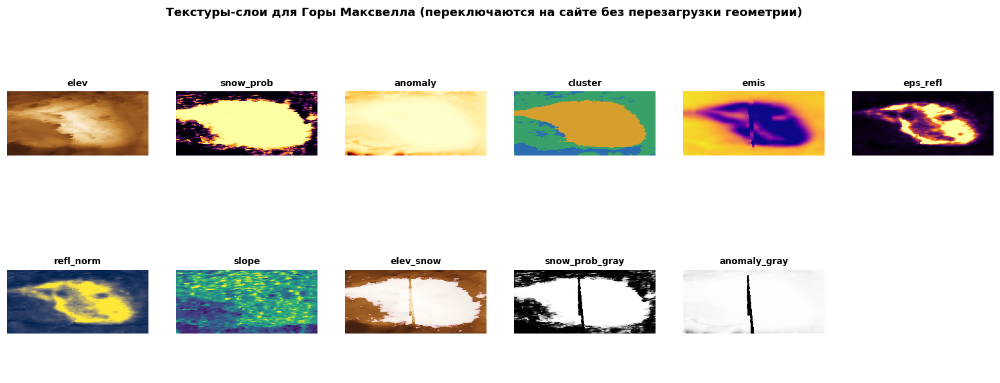

   Экспорт: /content/drive/MyDrive/venus_snow/results/export_3d  (119.6 МБ), архив: /content/drive/MyDrive/venus_snow/results/venus_3d_export.zip
   Чтобы скачать архив: files.download(zip_path)
✅ Ячейка 11 завершена. Проверить .glb можно на https://gltf-viewer.donmccurdy.com


In [13]:
#
# ЯЧЕЙКА 11 — Экспорт 3D-моделей в glTF (.glb) для сайта

#  Что получается в results/export_3d/:
#   venus_globe.glb                 — глобус с рельефом и текстурой «высота + снег»
#   region_<имя>.glb                — детальные модели высокогорий
#   textures/<объект>/<слой>.png    — ВСЕ слои как отдельные текстуры (та же UV-развертка):
#        elev, snow_prob, anomaly, cluster, emis, eps_refl, refl_norm, slope, elev_snow
#   textures/<объект>/snow_prob_gray.png, anomaly_gray.png
#        — вероятность снега в оттенках серого (значение = пиксель/255):
#          сайт сможет менять порог снега в шейдере на лету
#   textures/<объект>/height16.png  — 16-битная карта высот (для смещения рельефа в шейдере)
#   manifest.json                   — описание объектов, слоев, легенд, порогов, снеговых линий
#  Система координат glTF: Y — вверх, единицы: глобус — радиус 1; регионы — километры.
import trimesh
import shutil

GLOBE_MESH_RES = 0.5        # шаг сетки геометрии глобуса, ° (текстуры — в полном разрешении)
GLOBE_EXAG = 40             # вертикальное преувеличение рельефа глобуса
REGION_EXAG = 6             # вертикальное преувеличение для регионов
KM_PER_DEG = R_KM * np.pi / 180

print_header("ЯЧЕЙКА 11. Экспорт glTF")
TEX_DIR = EXPORT_DIR / "textures"
TEX_DIR.mkdir(parents=True, exist_ok=True)


def grid_faces(nr, nc):
    """Треугольники для регулярной сетки nr×nc (строки — с севера на юг, столбцы — с запада на восток)."""
    i, j = np.meshgrid(np.arange(nr - 1), np.arange(nc - 1), indexing="ij")
    a = (i * nc + j).ravel()
    b, c, d = a + nc, a + 1, a + nc + 1
    return np.concatenate([np.stack([a, b, c], 1), np.stack([c, b, d], 1)])


def save_png(arr, path, mode=None):
    path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(arr, mode=mode).save(path, optimize=True)
    return str(path.relative_to(EXPORT_DIR))


def write_textures(obj_id, rs, cs):
    """Все слои объекта в PNG. Возвращает словарь путей для manifest."""
    out = {}
    for key in LAYERS:
        rgb = layer_rgb(key, LAYERS[key]["data"][rs, cs])
        if key == "elev":
            out_rgb_elev = rgb
        out[key] = save_png(rgb, TEX_DIR / obj_id / f"{key}.png")
    base = blend_snow(out_rgb_elev, RES["snow_prob"][rs, cs], DEFAULT_THR)
    out["elev_snow"] = save_png(base, TEX_DIR / obj_id / "elev_snow.png")
    for src in ("snow_prob", "anomaly"):
        g = (np.clip(np.nan_to_num(RES[src][rs, cs]), 0, 1) * 255).astype(np.uint8)
        out[f"{src}_gray"] = save_png(g, TEX_DIR / obj_id / f"{src}_gray.png", "L")
    e = ELEV_FILLED[rs, cs]
    lo, hi = float(np.nanmin(e)), float(np.nanmax(e))
    h16 = ((e - lo) / max(hi - lo, 1e-6) * 65535).astype(np.uint16)
    Image.fromarray(h16).save(TEX_DIR / obj_id / "height16.png")
    out["height16"] = str((TEX_DIR / obj_id / "height16.png").relative_to(EXPORT_DIR))
    return out, base, (lo, hi)


def textured_mesh(vertices, faces, uv, image_rgb):
    mat = trimesh.visual.material.PBRMaterial(baseColorTexture=Image.fromarray(image_rgb),
                                              metallicFactor=0.0, roughnessFactor=0.9)
    return trimesh.Trimesh(vertices=vertices, faces=faces, process=False,
                           visual=trimesh.visual.TextureVisuals(uv=uv, material=mat))


MANIFEST = {
    "title": "Venus — metallic snow & surface types (Magellan GxDR + ML)",
    "coordinate_system": "glTF, Y up. Globe: unit sphere (1 = 6051 km), +X → (0°N, 0°E), +Y → North pole. "
                         "Regions: kilometres, origin at region centre, +X east, −Z north, Y = height × exaggeration.",
    "uv": "TEXCOORD_0 in glTF convention: (0,0) = north-west corner = top-left pixel of every PNG. "
          "All layer textures of an object share this UV; in three.js load them with texture.flipY = false.",
    "snow": {"default_threshold": DEFAULT_THR, "model": SMETA["best_classifier"],
             "gray_encoding": "probability = pixel / 255",
             "sources": {"snow_prob_gray": "ML classifier", "anomaly_gray": "unsupervised anomaly percentile"}},
    "layers": {k: {"title": v["title"], "type": "categorical" if v.get("categorical") else "continuous",
                   "range": [float(x) for x in v["range"]],
                   "colors": CL_COLORS[:K_CL] if v.get("categorical") else STOPS[v["cmap"]],
                   **({"labels": CL_NAMES} if v.get("categorical") else {})} for k, v in LAYERS.items()},
    "objects": [],
}


with Timer("глобус"):
    f = max(1, int(round(GLOBE_MESH_RES / GRID_RES)))
    lat_c, lon_c = coarsen_axes(f)
    lon_c = np.append(lon_c, lon_c[0] + 360)                       #замкнуть шов
    e = coarsen(ELEV_FILLED, f)
    e = np.concatenate([e, e[:, :1]], axis=1)
    LA, LO = np.meshgrid(lat_c, lon_c, indexing="ij")
    x, y, z = sphere_xyz(LA, LO, e, GLOBE_EXAG)                     #z — к северу
    verts = np.stack([x.ravel(), z.ravel(), -y.ravel()], 1)        #glTF: Y вверх
    uv = np.stack([((LO + 180) / 360).ravel(), ((LA + 90) / 180).ravel()], 1)
    faces = grid_faces(*LA.shape)
    allr, allc = slice(0, LAT.size), slice(0, LON.size)
    tex, base, (hlo, hhi) = write_textures("globe", allr, allc)
    mesh = textured_mesh(verts, faces, uv, base)
    glb = EXPORT_DIR / "venus_globe.glb"
    mesh.export(glb)
    MANIFEST["objects"].append({
        "id": "globe", "name": "Венера", "type": "globe", "glb": glb.name, "textures": tex,
        "exaggeration": GLOBE_EXAG, "height_range_km": [hlo, hhi], "mesh_res_deg": GLOBE_MESH_RES,
        "vertices": int(len(verts)), "triangles": int(len(faces)),
        "snow_area_km2_default": snow_area_km2(RES["snow_prob"], DEFAULT_THR),
    })


for name, box in REGIONS.items():
    with Timer(name):
        rs, cs = region_data(name)
        lat_r, lon_r = LAT[rs], LON[cs]
        lat0, lon0 = float(lat_r.mean()), float(lon_r.mean())
        LA, LO = np.meshgrid(lat_r, lon_r, indexing="ij")
        e = ELEV_FILLED[rs, cs]
        xk = (LO - lon0) * KM_PER_DEG * np.cos(np.deg2rad(lat0))
        yk = (LA - lat0) * KM_PER_DEG
        verts = np.stack([xk.ravel(), (e * REGION_EXAG).ravel(), (-yk).ravel()], 1)
        uv = np.stack([((LO - lon_r.min()) / np.ptp(lon_r)).ravel(), ((LA - lat_r.min()) / np.ptp(lat_r)).ravel()], 1)
        faces = grid_faces(*LA.shape)
        obj_id = "region_" + slug(name)
        tex, base, (hlo, hhi) = write_textures(obj_id, rs, cs)
        mesh = textured_mesh(verts, faces, uv, base)
        glb = EXPORT_DIR / f"{obj_id}.glb"
        mesh.export(glb)
        m = np.isfinite(RES["elev_km"][rs, cs])
        MANIFEST["objects"].append({
            "id": obj_id, "name": name, "type": "region", "glb": glb.name, "textures": tex,
            "bounds": {"lat": [float(lat_r.min()), float(lat_r.max())], "lon": [float(lon_r.min()), float(lon_r.max())]},
            "center": {"lat": lat0, "lon": lon0}, "exaggeration": REGION_EXAG, "height_range_km": [hlo, hhi],
            "snowline_km": snowline_of(name),
            "snow_area_km2_default": float(AREA[rs, cs][m & (np.nan_to_num(RES["snow_prob"][rs, cs]) >= DEFAULT_THR)].sum()),
            "vertices": int(len(verts)), "triangles": int(len(faces)),
        })

(EXPORT_DIR / "manifest.json").write_text(json.dumps(MANIFEST, ensure_ascii=False, indent=2))


rows = []
for o in MANIFEST["objects"]:
    p = EXPORT_DIR / o["glb"]
    sc = trimesh.load(p, force="mesh")
    has_tex = getattr(sc.visual, "material", None) is not None and getattr(sc.visual, "uv", None) is not None
    rows.append({"объект": o["name"], "файл": o["glb"], "вершин": len(sc.vertices), "треугольников": len(sc.faces),
                 "текстура": "✓" if has_tex else "✗", "МБ": round(p.stat().st_size / 2**20, 2)})
display(pd.DataFrame(rows))

chk = MANIFEST["objects"][1]
m = trimesh.load(EXPORT_DIR / chk["glb"], force="mesh")
img = np.asarray(m.visual.material.baseColorTexture.convert("RGB"))
u, v = m.visual.uv[:, 0], m.visual.uv[:, 1]
px = np.clip((u * (img.shape[1] - 1)).round().astype(int), 0, img.shape[1] - 1)
py = np.clip(((1 - v) * (img.shape[0] - 1)).round().astype(int), 0, img.shape[0] - 1)
vc = img[py, px]
fig = go.Figure(go.Mesh3d(x=m.vertices[:, 0], y=-m.vertices[:, 2], z=m.vertices[:, 1],
                          i=m.faces[:, 0], j=m.faces[:, 1], k=m.faces[:, 2],
                          vertexcolor=[f"rgb({r},{g},{b})" for r, g, b in vc], flatshading=False,
                          lighting=dict(ambient=0.5, diffuse=0.8)))
fig.update_layout(title=f"Проверка экспорта: {chk['name']} ({chk['glb']}), прочитано из файла",
                  scene=dict(aspectmode="data"), height=520, margin=dict(l=0, r=0, t=40, b=0))
fig.show()

keys = [k for k in chk["textures"] if k != "height16"]
fig, axes = plt.subplots(2, int(np.ceil(len(keys) / 2)), figsize=(18, 6))
for ax, k in zip(axes.flat, keys):
    ax.imshow(Image.open(EXPORT_DIR / chk["textures"][k]), cmap="gray")
    ax.set_title(k, fontsize=9); ax.axis("off")
for ax in list(axes.flat)[len(keys):]:
    ax.axis("off")
fig.suptitle(f"Текстуры-слои для {chk['name']} (переключаются на сайте без перезагрузки геометрии)", fontweight="bold")
savefig(fig, "11_textures_preview")


zip_path = shutil.make_archive(str(OUT_DIR / "venus_3d_export"), "zip", EXPORT_DIR)
total = sum(p.stat().st_size for p in EXPORT_DIR.rglob("*") if p.is_file()) / 2**20
print(f"   Экспорт: {EXPORT_DIR}  ({total:.1f} МБ), архив: {zip_path}")
if IN_COLAB:
    from google.colab import files
    print("   Чтобы скачать архив: files.download(zip_path)")
print("✅ Ячейка 11 завершена. Проверить .glb можно на https://gltf-viewer.donmccurdy.com")


  ячейка 12. проверка бистатическим радаром, горы Максвелла
   геометрия: ['4156n00a.srg']
   спектры: ['4156130b.spc', '4156155b.spc', '4156191b.spc']
   srg: 480 строк геометрии, служебных строк пропущено: 1
   точка отражения: широта -82.8–85.4°, угол падения 9.2–89.3°
   4156130b.spc: 192 спектров * 1024 бинов, служебных строк 8, 13.16–13.69 ч utc
   4156155b.spc: 288 спектров * 1024 бинов, служебных строк 12, 15.97–16.77 ч utc
   4156191b.spc: 288 спектров * 1024 бинов, служебных строк 12, 19.18–19.97 ч utc
   4156130b: окно эха 12476–12622 гц; шагов с snr >= 5.0: 134 из 192
   4156155b: окно эха 12378–12598 гц; шагов с snr >= 5.0: 208 из 288
   4156191b: окно эха 12451–12598 гц; шагов с snr >= 5.0: 187 из 288
   шагов без надежной геометрии: 41

   пригодных шагов для сравнения: 372 из 768; в зоне снега по карте: 33


,значение
пригодных шагов,372
шагов в зоне снега,33
медиана m_c в зоне снега,0.243958
медиана m_c вне зоны снега,0.084361
p Манна–Уитни,0.0
roc-auc m_c для зоны снега,0.765084
корреляция Спирмена m_c и вероятности снега,0.094164
"корреляция Спирмена m_c и вероятности снега, p",0.069663
корреляция Спирмена m_c и излучательной способности,-0.112979
"корреляция Спирмена m_c и излучательной способности, p",0.029353



   вывод:
   roc-auc = 0.77: bsr независимо подтверждает зону снега
   снеговая линия: bsr 5.54 ± 0.06 км, карта 5.51 км, разница 0.04 км


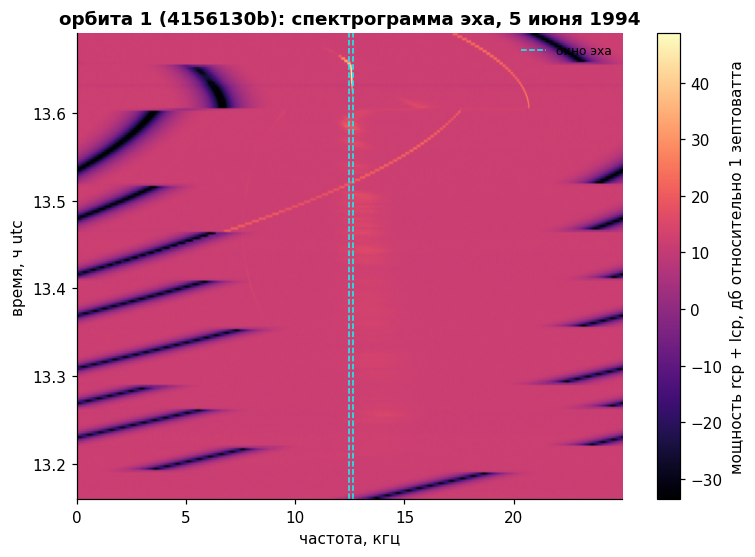

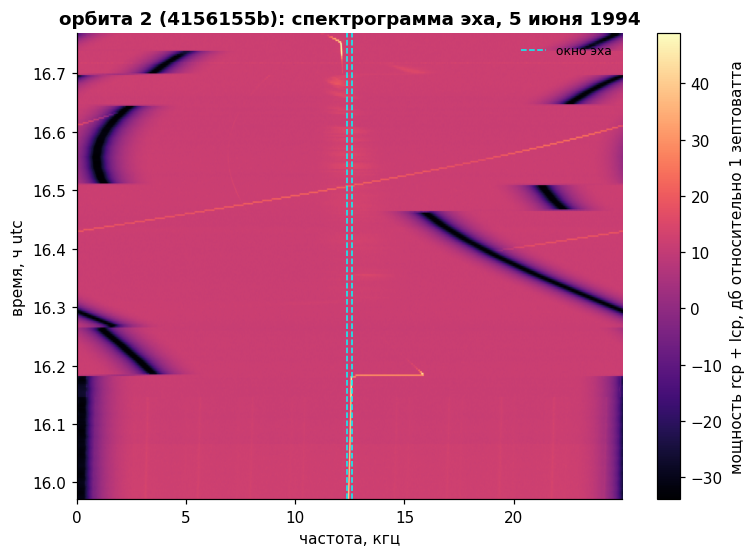

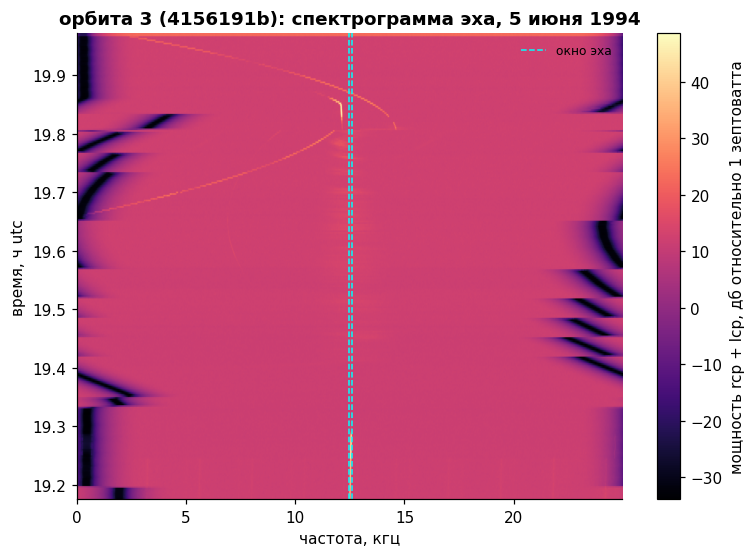

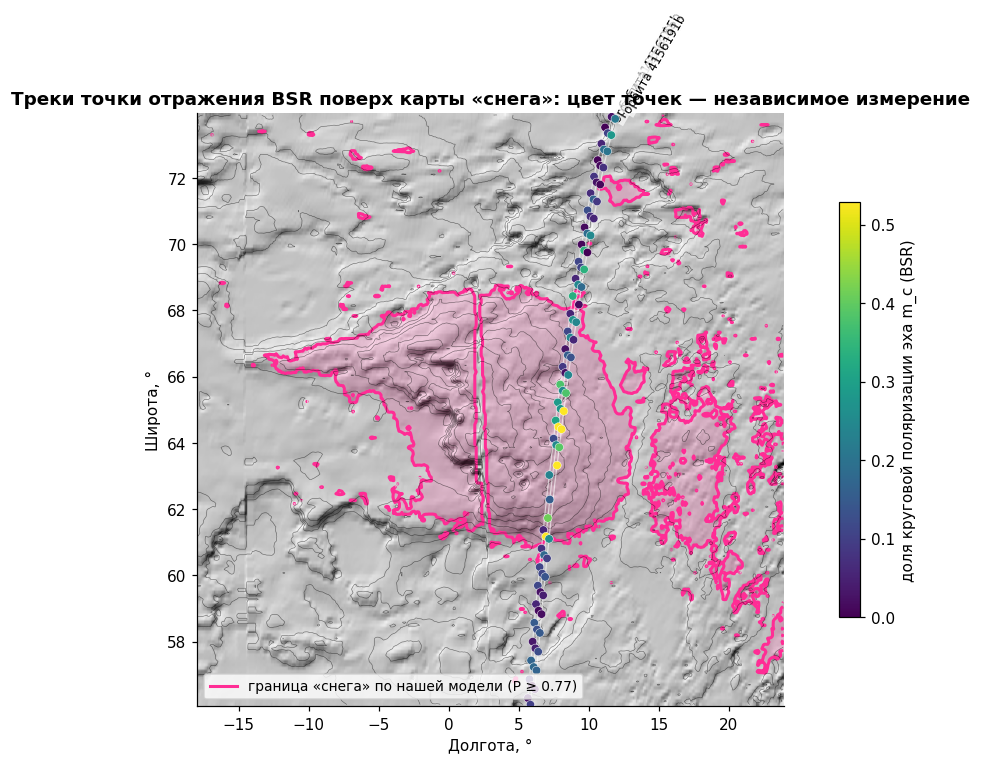

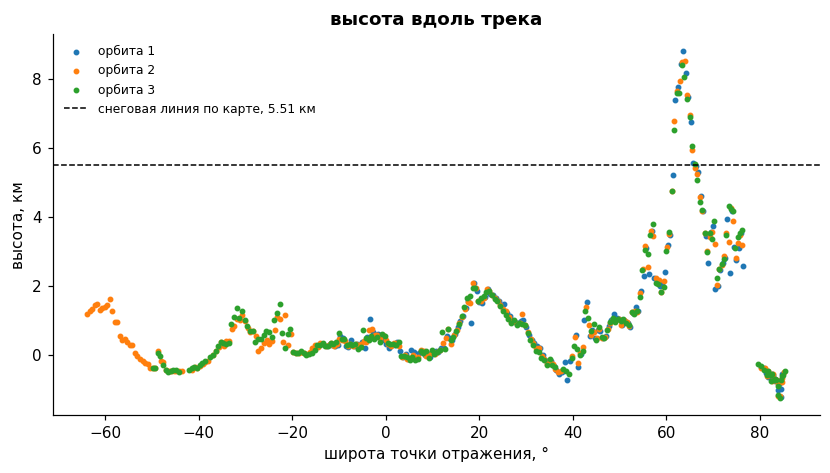

...

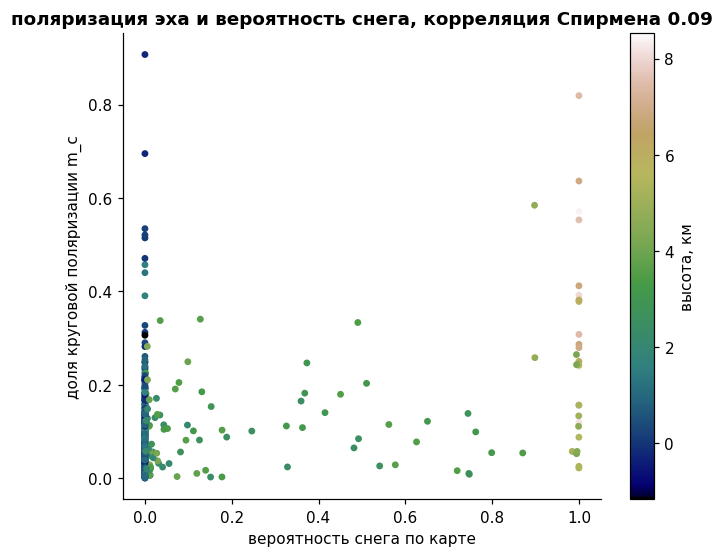

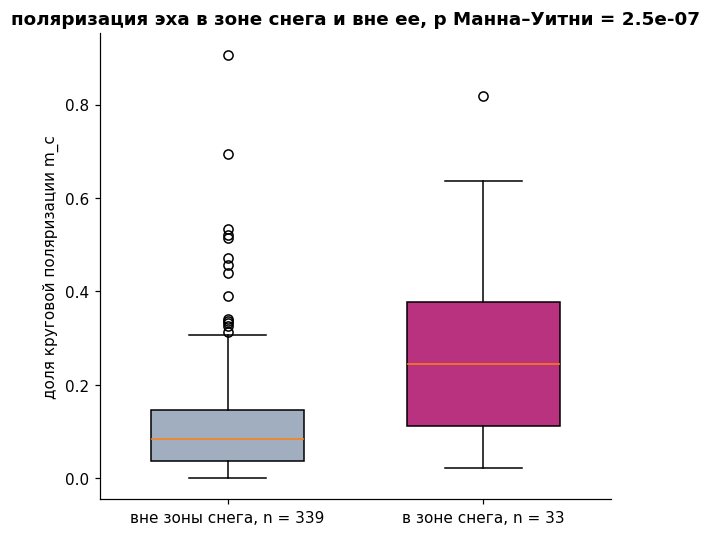

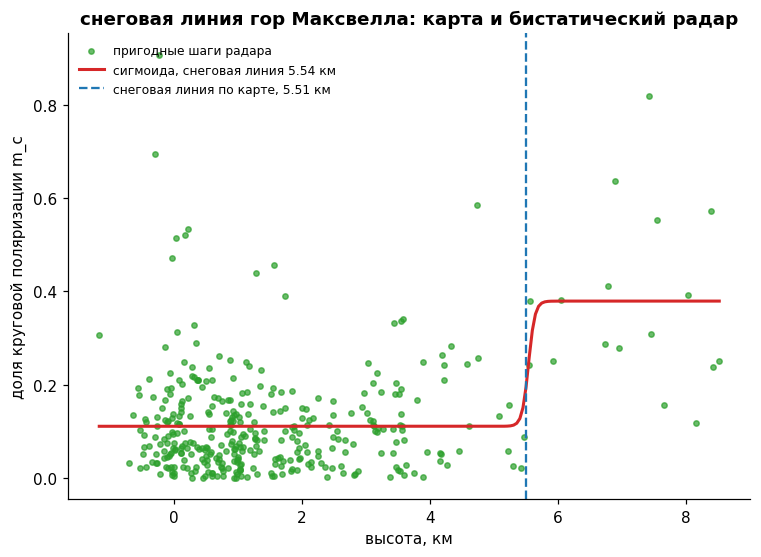

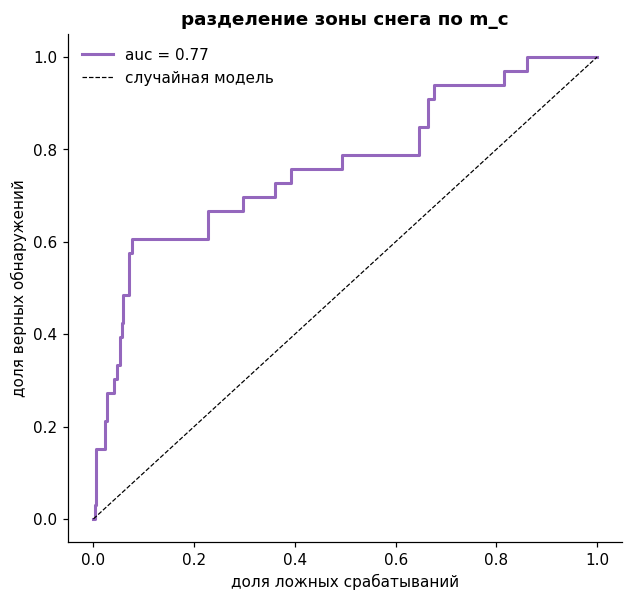

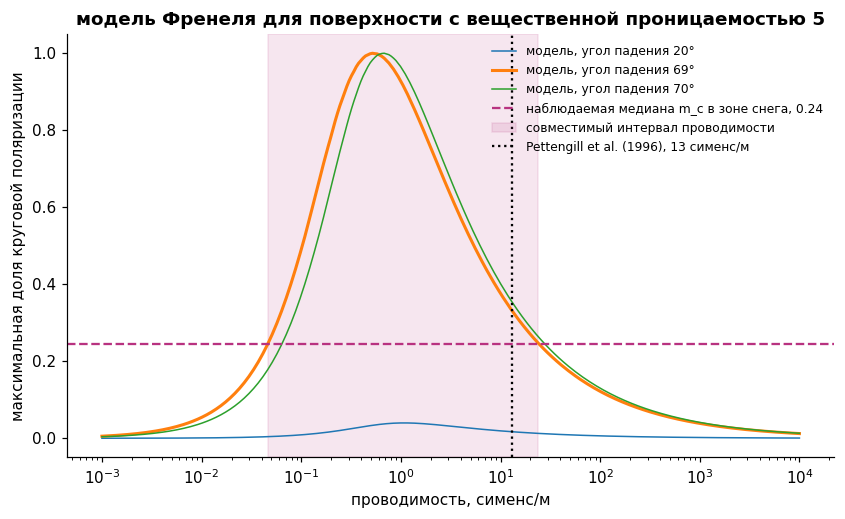

ячейка 12 завершена: results/bsr_track_validation.csv, bsr_validation_summary.json


In [18]:
#=====================================================================
#ячейка 12 – независимая проверка на горах Максвелла по данным бистатического
#радара Magellan
#запускать после ячейки 8
#Magellan излучал в s-диапазоне (2298 мгц, длина волны около 13 см) линейно поляризованную
#волну в точку зеркального отражения, эхо принимала 70-метровая антенна dss 63 (сеть дальней
#космической связи) в Мадриде в двух круговых поляризациях: rcp (правая) и lcp (левая)
#у обычного диэлектрика (базальт, ε' около 4–6) коэффициенты Френеля r_h и r_v вещественные,
#отраженная волна остается линейной и круговой компоненты нет
#у проводящего вещества (комплексная ε) между r_h и r_v появляется сдвиг фазы и в эхе
#возникает круговая компонента, по ней Pettengill et al. (1996) сделали вывод
#о полупроводниковом покрытии вершин Максвелла
#мерило: доля круговой поляризации эха m_c – модуль разности мощностей rcp и lcp, деленный на их сумму;
#отношение мощностей почти не зависит от абсолютной калибровки
#сравниваются m_c вдоль треков точки отражения и карта снега, излучательная способность, высота
#и снеговая линия Максвелла из ячейки 6; данные bsr (бистатического радара) не участвовали в обучении
#результат: results/bsr_*.csv и .json, картинки 12_*.png
#=====================================================================
import requests
from scipy.stats import mannwhitneyu, spearmanr
from scipy.optimize import curve_fit
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm.auto import tqdm

print_header("ячейка 12. проверка бистатическим радаром, горы Максвелла")
MAXWELL = "Горы Максвелла"
BSR = {
    "base_url": "https://pds-geosciences.wustl.edu/mgn/urn-nasa-pds-magellan_bsr_calibrated/",
    "fallback": {"srg": ["4156n00a.srg"], "spc": ["4156130b.spc", "4156155b.spc", "4156191b.spc"]},
    "freq_hz": 2298e6,
    "eps_real": 5.0,
    "noise_bands_hz": [(2500, 8000), (17000, 22500)],
    "echo_search_hz": (9000, 16000),
    "min_snr": 5.0,
    "sample_radius_km": 15,
    "pettengill_sigma": 13.0,
}
BSR_DIR = DATA_DIR / "bsr"
BSR_DIR.mkdir(exist_ok=True)


def _listing(url):
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        return sorted({h.rstrip("/").split("/")[-1] for h in re.findall(r'href="([^"]+)"', r.text, flags=re.I)})
    except Exception as e:
        print(f"   листинг {url} недоступен ({str(e).lower()})")
        return []


def _download(url, dst):
    if dst.exists() and dst.stat().st_size > 0:
        print(f"   уже загружен: {dst.name}")
        return
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        tmp = dst.with_name(dst.name + ".part")
        with open(tmp, "wb") as f, tqdm(total=int(r.headers.get("content-length", 0)), unit="B",
                                        unit_scale=True, desc=dst.name) as bar:
            for ch in r.iter_content(1 << 20):
                f.write(ch)
                bar.update(len(ch))
        tmp.rename(dst)


FILES = {}
for coll, ext in (("srg", ".srg"), ("spc", ".spc")):
    local = sorted(p.name for p in BSR_DIR.glob(f"*{ext}"))
    if len(local) >= len(BSR["fallback"][coll]):
        FILES[coll] = local
        continue
    names = [n for n in _listing(BSR["base_url"] + coll + "/") if n.lower().endswith(ext)] or BSR["fallback"][coll]
    for n in names:
        _download(BSR["base_url"] + f"{coll}/{n}", BSR_DIR / n)
    FILES[coll] = sorted(p.name for p in BSR_DIR.glob(f"*{ext}"))
print(f"   геометрия: {FILES['srg']}\n   спектры: {FILES['spc']}")

_tok = re.compile(r"[,\s]+")


def numeric_rows(path, n_min, n_max=None):  #прочитать строки из n_min–n_max чисел, текстовые строки отбросить
    rows, skipped = [], 0
    with open(path, "r", errors="ignore") as f:
        for line in f:
            t = [x for x in _tok.split(line.strip().strip('"')) if x]
            if not (n_min <= len(t) <= (n_max or n_min)):
                skipped += 1
                continue
            try:
                rows.append([float(x.strip('"')) for x in t])
            except ValueError:
                skipped += 1
    return np.array(rows), skipped


#srg: 58 чисел в строке; [0] время приема на Земле, с от полуночи utc (всемирное координированное
#время), [45] угол падения, [47] широта точки отражения, [48] ее долгота
srg, sk = numeric_rows(BSR_DIR / FILES["srg"][0], 49, 60)
print(f"   srg: {len(srg)} строк геометрии, служебных строк пропущено: {sk}")
if srg.shape[1] != 58:
    print(f"   в строке {srg.shape[1]} чисел вместо 58, требуется сверка разметки по .xml-метке файла")
GEO = pd.DataFrame({"ert": srg[:, 0], "inc": srg[:, 45], "lat": srg[:, 47],
                    "lon": ((srg[:, 48] + 180) % 360) - 180})
GEO = GEO[np.isfinite(GEO["lat"]) & (GEO["lat"].abs() <= 90)].reset_index(drop=True)
print(f"   точка отражения: широта {GEO.lat.min():.1f}–{GEO.lat.max():.1f}°, "
      f"угол падения {GEO.inc.min():.1f}–{GEO.inc.max():.1f}°")


def parse_spc(path):  #прочитать спектры: номер, время, бин, частота, мощности rcp и lcp, взаимный спектр
    a, sk = numeric_rows(path, 12)
    df = pd.DataFrame(a, columns=["n", "t", "bin", "f", "xr", "xl", "pr", "pl", "xm", "xp", "cm", "cp"])
    m = re.match(r"\d(\d{3})(\d{2})(\d)", path.stem)
    t0 = int(m.group(2)) * 3600 + int(m.group(3)) * 600 if m else 0

    if df["t"].min() < 20000:
        df["t"] = df["t"] + t0
    print(f"   {path.name}: {df['n'].nunique()} спектров * {df['bin'].nunique()} бинов, служебных строк {sk}, "
          f"{df['t'].min() / 3600:.2f}–{df['t'].max() / 3600:.2f} ч utc")
    return df


SPECTRA = {Path(n).stem: parse_spc(BSR_DIR / n) for n in FILES["spc"]}


def analyse_orbit(df):  #рассчитать мощность эха, шум, snr (отношение сигнал/шум) и поляризацию каждого шага
    nbin = int(df["bin"].nunique())
    f = df["f"].values[:nbin]
    PR = df["pr"].values.reshape(-1, nbin)
    PL = df["pl"].values.reshape(-1, nbin)
    C = (df["cm"].values * np.exp(1j * df["cp"].values)).reshape(-1, nbin)
    t = df.groupby("n", sort=False)["t"].first().values
    noise_m = np.zeros(len(f), bool)
    for a, b in BSR["noise_bands_hz"]:
        noise_m |= (f >= a) & (f <= b)
    nR, nL = np.median(PR[:, noise_m], 1), np.median(PL[:, noise_m], 1)
    sR = 1.4826 * np.median(np.abs(PR[:, noise_m] - nR[:, None]), 1)
    sL = 1.4826 * np.median(np.abs(PL[:, noise_m] - nL[:, None]), 1)
    exc = (PR - nR[:, None]) + (PL - nL[:, None])
    #окно эха: по 20% самых сильных шагов, где средний избыток выше 10% пика
    srch = (f >= BSR["echo_search_hz"][0]) & (f <= BSR["echo_search_hz"][1])
    strong = np.argsort(exc[:, srch].sum(1))[-max(3, len(t) // 5):]
    prof = np.array(pd.Series(exc[strong].mean(0)).rolling(5, center=True, min_periods=1).mean().values, copy=True)
    prof[~srch] = 0
    pk = int(np.argmax(prof))
    lo = hi = pk
    while lo > 0 and prof[lo - 1] > 0.1 * prof[pk]:
        lo -= 1
    while hi < len(f) - 1 and prof[hi + 1] > 0.1 * prof[pk]:
        hi += 1
    win = slice(lo, hi + 1)
    nw = hi - lo + 1
    ER = (PR[:, win] - nR[:, None]).sum(1)
    EL = (PL[:, win] - nL[:, None]).sum(1)
    X = C[:, win].sum(1)
    tot = ER + EL
    snr = tot / (np.sqrt(sR ** 2 + sL ** 2) * np.sqrt(nw) + 1e-30)
    fw = f[win]
    w = np.clip(exc[:, win], 0, None)
    cen = (w * fw).sum(1) / (w.sum(1) + 1e-30)
    width = np.sqrt((w * (fw - cen[:, None]) ** 2).sum(1) / (w.sum(1) + 1e-30))
    #узкий всплеск в одном бине считается помехой
    spike = (w.max(1) / (w.sum(1) + 1e-30)) > 0.5
    out = pd.DataFrame({"t": t, "echo_R": ER, "echo_L": EL, "snr": snr,
                        "m_c": np.abs(ER - EL) / np.where(tot > 0, tot, np.nan),
                        "m_l": 2 * np.abs(X) / np.where(tot > 0, tot, np.nan),
                        "doppler_width_hz": width, "interference": spike})
    return out, (f, PR + PL, (f[lo], f[hi]), noise_m)


TRACK, WATERFALL = [], {}
for name, df in SPECTRA.items():
    res_o, wf = analyse_orbit(df)
    res_o["orbit"] = name
    TRACK.append(res_o)
    WATERFALL[name] = wf
    print(f"   {name}: окно эха {wf[2][0]:.0f}–{wf[2][1]:.0f} гц; шагов с snr >= {BSR['min_snr']}: "
          f"{(res_o.snr >= BSR['min_snr']).sum()} из {len(res_o)}")
TRACK = pd.concat(TRACK, ignore_index=True)

for c in ("lat", "lon", "inc"):
    TRACK[c] = np.interp(TRACK["t"], GEO["ert"], GEO[c], left=np.nan, right=np.nan)
#шаги дальше 90 с от ближайшей строки геометрии отбрасываются: интерполяция через пропуск дает ложные координаты
_gap = np.abs(TRACK["t"].values[:, None] - GEO["ert"].values[None, :]).min(1) > 90
TRACK.loc[_gap, ["lat", "lon", "inc"]] = np.nan
print(f"   шагов без надежной геометрии: {int(_gap.sum())}")
ORBIT_LABEL = {name: f"орбита {i + 1}" for i, name in enumerate(sorted(TRACK["orbit"].unique()))}

RES12 = dict(np.load(OUT_DIR / "venus_results.npz"))
lat_g, lon_g = RES12["lat"], RES12["lon"]
res_g = float(abs(lat_g[0] - lat_g[1]))


def sample(arr, la, lo, radius_km):  #усреднить значение карты в круге вокруг точки отражения
    if not np.isfinite(la):
        return np.nan
    i = int(np.clip(round((90 - res_g / 2 - la) / res_g), 0, lat_g.size - 1))
    j = int(np.clip(round((lo + 180 - res_g / 2) / res_g), 0, lon_g.size - 1))
    di = max(1, int(round(radius_km / (R_KM * np.deg2rad(res_g)))))
    dj = max(1, int(round(di / max(np.cos(np.deg2rad(la)), 0.1))))
    win = arr[max(0, i - di): i + di + 1, max(0, j - dj): j + dj + 1]
    return float(np.nanmean(win)) if np.isfinite(win).any() else np.nan


snow_thr = json.loads((OUT_DIR / "snow_summary.json").read_text())["threshold"]
for key, col in (("elev_km", "elev_km"), ("snow_prob", "snow_prob"), ("emis", "emis"),
                 ("eps_refl", "eps_map"), ("anomaly", "anomaly")):
    TRACK[col] = [sample(RES12[key], a, b, BSR["sample_radius_km"]) for a, b in zip(TRACK.lat, TRACK.lon)]
TRACK["in_snow"] = TRACK["snow_prob"] >= snow_thr
good = (TRACK.snr >= BSR["min_snr"]) & ~TRACK.interference & TRACK.lat.notna() & TRACK.snow_prob.notna()
V = TRACK[good].copy()
print(f"\n   пригодных шагов для сравнения: {len(V)} из {len(TRACK)}; в зоне снега по карте: {int(V.in_snow.sum())}")


def mc_model(eps_complex, theta_deg, psi_deg):  #рассчитать модельную долю круговой поляризации отраженной волны
    th, ps = np.deg2rad(theta_deg), np.deg2rad(psi_deg)
    k = np.sqrt(eps_complex - np.sin(th) ** 2)
    Rh = (np.cos(th) - k) / (np.cos(th) + k)
    Rv = (eps_complex * np.cos(th) - k) / (eps_complex * np.cos(th) + k)
    Eh, Ev = Rh * np.cos(ps), Rv * np.sin(ps)
    return np.abs(2 * np.imag(np.conj(Eh) * Ev)) / (np.abs(Eh) ** 2 + np.abs(Ev) ** 2)


lam = 299792458.0 / BSR["freq_hz"]
SIG = np.logspace(-3, 4, 300)
#ориентация поляризации антенны неизвестна, поэтому перебирается
PSI = np.linspace(1, 89, 89)


def mc_max_curve(theta):  #рассчитать максимум модельной m_c по ориентации для каждой проводимости
    eps = BSR["eps_real"] - 1j * 60 * lam * SIG[:, None]
    return mc_model(eps, theta, PSI[None, :]).max(1)


theta_med = float(np.nanmedian(V.loc[V.in_snow, "inc"])) if V.in_snow.any() else \
    (float(np.nanmedian(V.inc)) if len(V) else 45.0)
curve = mc_max_curve(theta_med)


def sigma_range(mc_obs):  #найти интервал проводимости, совместимый с наблюдаемой m_c
    ok = curve >= mc_obs
    return (float(SIG[ok].min()), float(SIG[ok].max())) if ok.any() else (np.nan, np.nan)


stats = {"пригодных шагов": len(V), "шагов в зоне снега": int(V.in_snow.sum())}
if V.in_snow.sum() >= 3 and (~V.in_snow).sum() >= 3:
    a, b = V.loc[V.in_snow, "m_c"], V.loc[~V.in_snow, "m_c"]
    u = mannwhitneyu(a, b, alternative="greater")
    stats.update({"медиана m_c в зоне снега": a.median(), "медиана m_c вне зоны снега": b.median(),
                  "p Манна–Уитни": u.pvalue, "roc-auc m_c для зоны снега": roc_auc_score(V.in_snow, V.m_c)})
for col, lbl in (("snow_prob", "корреляция Спирмена m_c и вероятности снега"),
                 ("emis", "корреляция Спирмена m_c и излучательной способности"),
                 ("elev_km", "корреляция Спирмена m_c и высоты")):
    if V[col].notna().sum() > 5:
        r = spearmanr(V.m_c, V[col], nan_policy="omit")
        stats[lbl] = r.correlation
        stats[lbl + ", p"] = r.pvalue


def sig(h, m0, d, hc, w):  #сигмоида роста m_c с высотой
    return m0 + d / (1 + np.exp(-(h - hc) / w))


hc_bsr = hc_err = np.nan
p = None
try:
    p, cov = curve_fit(sig, V.elev_km, V.m_c, p0=[V.m_c.quantile(.2), V.m_c.quantile(.9) - V.m_c.quantile(.2),
                                                   V.elev_km.quantile(.7), 0.5],
                       bounds=([0, 0, -1, 0.05], [1, 1, 12, 3]), maxfev=20000)
    if p[1] > 0.03:
        hc_bsr, hc_err = p[2], np.sqrt(np.diag(cov))[2]
except Exception:
    p = None
hc_map = snowline_of(MAXWELL) if "snowline_of" in globals() else None
if hc_map is None:
    try:
        hc_map = float(pd.read_csv(OUT_DIR / "snowline_by_region.csv").set_index("регион")
                       .loc[MAXWELL, "снеговая линия h_c, км"])
    except Exception:
        hc_map = np.nan
stats["снеговая линия по bsr, км"] = hc_bsr
stats["погрешность снеговой линии по bsr, км"] = hc_err
stats["снеговая линия по карте, ячейка 6, км"] = hc_map
mc_snow = float(V.loc[V.in_snow, "m_c"].median()) if V.in_snow.any() else np.nan
s_lo, s_hi = sigma_range(mc_snow) if np.isfinite(mc_snow) else (np.nan, np.nan)
stats["угол падения в зоне снега, °"] = theta_med
stats["проводимость, совместимая с m_c, сименс/м"] = f"{s_lo:.2g}–{s_hi:.2g}" if np.isfinite(s_lo) else "не определена"
if np.isfinite(mc_snow) and not np.isfinite(s_lo):
    print(f"   m_c = {mc_snow:.2f} больше максимума модели гладкой поверхности при угле {theta_med:.0f}° "
          f"({curve.max():.2f}): требуется проверка калибровки каналов или значения eps_real")
stats["проводимость по Pettengill et al. (1996), сименс/м"] = BSR["pettengill_sigma"]
STATS = pd.Series(stats, name="значение")
display(STATS.to_frame())

verdict = []
if "roc-auc m_c для зоны снега" in stats:
    auc = stats["roc-auc m_c для зоны снега"]
    verdict.append(f"roc-auc = {auc:.2f}: " + ("bsr независимо подтверждает зону снега" if auc >= 0.7 and
                   stats["p Манна–Уитни"] < 0.05 else "согласие слабое или статистически не значимо"))
if np.isfinite(hc_bsr) and np.isfinite(hc_map):
    verdict.append(f"снеговая линия: bsr {hc_bsr:.2f} ± {hc_err:.2f} км, карта {hc_map:.2f} км, "
                   f"разница {abs(hc_bsr - hc_map):.2f} км")
print("\n   вывод:\n   " + "\n   ".join(verdict or ["недостаточно данных для вывода"]))

for name, (f, P, (wlo, whi), nm) in WATERFALL.items():
    tt = TRACK.loc[TRACK.orbit == name, "t"].values / 3600
    fig, ax = plt.subplots(figsize=(8, 5.5))
    im = ax.imshow(10 * np.log10(np.clip(P, 1e-6, None)), aspect="auto", origin="lower", cmap="magma",
                   extent=[f[0] / 1e3, f[-1] / 1e3, tt.min(), tt.max()])
    ax.axvline(wlo / 1e3, color="cyan", lw=1, ls="--", label="окно эха")
    ax.axvline(whi / 1e3, color="cyan", lw=1, ls="--")
    ax.set_xlabel("частота, кгц")
    ax.set_ylabel("время, ч utc")
    ax.set_title(f"{ORBIT_LABEL[name]} ({name}): спектрограмма эха, 5 июня 1994")
    ax.legend(loc="upper right", fontsize=8)
    fig.colorbar(im, ax=ax, label="мощность rcp + lcp, дб относительно 1 зептоватта")
    savefig(fig, f"12_spectrogram_{name}")

box = REGIONS[MAXWELL]
b2 = {"lat": (box["lat"][0] - 4, box["lat"][1] + 4), "lon": (box["lon"][0] - 10, box["lon"][1] + 10)}
rs, cs = region_slices(lat_g, lon_g, b2)
ext = [lon_g[cs][0], lon_g[cs][-1], lat_g[rs][-1], lat_g[rs][0]]
fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(hillshade(RES12["elev_km"][rs, cs], res_g, exag=12), extent=ext, cmap="gray")
sp = np.nan_to_num(RES12["snow_prob"][rs, cs])
ax.contourf(sp, levels=[snow_thr, 1.01], extent=ext, origin="upper", colors=["#ff2d95"], alpha=0.18)
ax.contour(sp, levels=[snow_thr], extent=ext, origin="upper", colors=["#ff2d95"], linewidths=2)
ax.contour(fill_nan_nearest(RES12["elev_km"][rs, cs]), levels=np.arange(0, 12, 1), extent=ext, origin="upper",
           colors="k", linewidths=0.4, alpha=0.5)
inr = V[(V.lat.between(*b2["lat"])) & (V.lon.between(*b2["lon"]))]
sc = ax.scatter(inr.lon, inr.lat, c=inr.m_c, cmap="viridis", s=30, edgecolor="white", lw=0.3, zorder=5,
                vmin=0, vmax=max(0.3, float(np.nanpercentile(V.m_c, 98)) if len(V) else 1))
for name in TRACK.orbit.unique():
    tr = TRACK[(TRACK.orbit == name) & TRACK.lat.between(*b2["lat"]) & TRACK.lon.between(*b2["lon"])].sort_values("lat")
    if len(tr) > 1:
        ax.plot(tr.lon, tr.lat, color="white", lw=0.8, alpha=0.6)
        ax.annotate(f"орбита {name}", (tr.lon.iloc[-1], tr.lat.iloc[-1]), xytext=(4, 4), textcoords="offset points",
                    color="black", fontsize=8, rotation=60,
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1))
ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
ax.set_aspect(1 / np.cos(np.deg2rad(np.mean(b2["lat"]))))
ax.set_xlabel("Долгота, °"); ax.set_ylabel("Широта, °")
fig.colorbar(sc, ax=ax, shrink=0.7, label="доля круговой поляризации эха m_c (BSR)")
ax.legend(handles=[plt.Line2D([0], [0], color="#ff2d95", lw=2)], labels=[f"граница снега по модели (P ≥ {snow_thr:.2f})"],
          loc="lower left", fontsize=9, frameon=True)
ax.set_title("Треки точки отражения BSR поверх карты снега: цвет точек — независимое измерение", fontweight="bold")
savefig(fig, "12_bsr_tracks_map")

ORBIT_COLORS = dict(zip(sorted(ORBIT_LABEL), ("tab:blue", "tab:orange", "tab:green")))
PROFILES = [
    ("elev_km", "высота, км", "высота вдоль трека", "12_profile_elevation"),
    ("snow_prob", "вероятность снега", "вероятность снега по карте вдоль трека", "12_profile_snow_probability"),
    ("emis", "излучательная способность", "излучательная способность вдоль трека", "12_profile_emissivity"),
    ("m_c", "доля круговой поляризации m_c", "круговая поляризация эха вдоль трека", "12_profile_circular_polarization"),
    ("m_l", "доля линейной поляризации m_l", "линейная поляризация эха вдоль трека", "12_profile_linear_polarization"),
    ("snr", "отношение сигнал/шум", "отношение сигнал/шум эха вдоль трека", "12_profile_snr"),
]
for col, ylab, title, fname in PROFILES:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for name in sorted(ORBIT_LABEL):
        d = TRACK[(TRACK.orbit == name) & TRACK.lat.notna()].sort_values("lat")
        if col in ("m_c", "m_l"):
            d = d[(d.snr >= BSR["min_snr"]) & ~d.interference]
        ax.scatter(d.lat, d[col], s=8, color=ORBIT_COLORS[name], label=ORBIT_LABEL[name])
    if col == "elev_km" and np.isfinite(hc_map):
        ax.axhline(hc_map, color="k", ls="--", lw=1, label=f"снеговая линия по карте, {hc_map:.2f} км")
    if col == "snr":
        ax.set_yscale("log")
        ax.axhline(BSR["min_snr"], color="r", ls="--", lw=1, label=f"минимальное значение, {BSR['min_snr']:.0f}")
    if col in ("m_c", "m_l", "snow_prob"):
        ax.set_ylim(0, 1.05)
    ax.set_xlabel("широта точки отражения, °")
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.legend(fontsize=8)
    savefig(fig, fname)

if len(V):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    pts = ax.scatter(V.snow_prob, V.m_c, s=12, c=V.elev_km, cmap="gist_earth")
    fig.colorbar(pts, ax=ax, label="высота, км")
    ax.set_xlabel("вероятность снега по карте")
    ax.set_ylabel("доля круговой поляризации m_c")
    ax.set_title(f"поляризация эха и вероятность снега, корреляция Спирмена "
                 f"{stats.get('корреляция Спирмена m_c и вероятности снега', np.nan):.2f}")
    savefig(fig, "12_mc_vs_snow_probability")

    data = [V.loc[~V.in_snow, "m_c"], V.loc[V.in_snow, "m_c"]]
    fig, ax = plt.subplots(figsize=(6, 5.5))
    bp = ax.boxplot([d if len(d) else [np.nan] for d in data], patch_artist=True, widths=0.6)
    for patch, c in zip(bp["boxes"], ("#a0aec0", "#b83280")):
        patch.set_facecolor(c)
    ax.set_xticks([1, 2], [f"вне зоны снега, n = {len(data[0])}", f"в зоне снега, n = {len(data[1])}"])
    ax.set_ylabel("доля круговой поляризации m_c")
    ax.set_title(f"поляризация эха в зоне снега и вне ее, p Манна–Уитни = {stats.get('p Манна–Уитни', np.nan):.2g}")
    savefig(fig, "12_mc_inside_vs_outside")

    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.scatter(V.elev_km, V.m_c, s=12, color="tab:green", alpha=0.7, label="пригодные шаги радара")
    if p is not None and np.isfinite(hc_bsr):
        hh = np.linspace(V.elev_km.min(), V.elev_km.max(), 200)
        ax.plot(hh, sig(hh, *p), color="tab:red", lw=2, label=f"сигмоида, снеговая линия {hc_bsr:.2f} км")
    if np.isfinite(hc_map):
        ax.axvline(hc_map, color="tab:blue", ls="--", label=f"снеговая линия по карте, {hc_map:.2f} км")
    ax.set_xlabel("высота, км")
    ax.set_ylabel("доля круговой поляризации m_c")
    ax.set_title("снеговая линия гор Максвелла: карта и бистатический радар")
    ax.legend(fontsize=8)
    savefig(fig, "12_snowline_map_vs_bsr")

    if V.in_snow.nunique() == 2:
        fpr, tpr, _ = roc_curve(V.in_snow, V.m_c)
        fig, ax = plt.subplots(figsize=(6.5, 6))
        ax.plot(fpr, tpr, color="tab:purple", lw=2, label=f"auc = {stats['roc-auc m_c для зоны снега']:.2f}")
        ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="случайная модель")
        ax.set_xlabel("доля ложных срабатываний")
        ax.set_ylabel("доля верных обнаружений")
        ax.set_title("разделение зоны снега по m_c")
        ax.legend()
        savefig(fig, "12_mc_roc")

fig, ax = plt.subplots(figsize=(9, 5))
for th in sorted({20.0, round(theta_med, 1), 70.0}):
    ax.semilogx(SIG, mc_max_curve(th), lw=2 if th == round(theta_med, 1) else 1, label=f"модель, угол падения {th:.0f}°")
if np.isfinite(mc_snow):
    ax.axhline(mc_snow, color="#b83280", ls="--", label=f"наблюдаемая медиана m_c в зоне снега, {mc_snow:.2f}")
if np.isfinite(s_lo):
    ax.axvspan(s_lo, s_hi, color="#b83280", alpha=0.12, label="совместимый интервал проводимости")
ax.axvline(BSR["pettengill_sigma"], color="k", ls=":", label="Pettengill et al. (1996), 13 сименс/м")
ax.set_xlabel("проводимость, сименс/м")
ax.set_ylabel("максимальная доля круговой поляризации")
ax.set_title(f"модель Френеля для поверхности с вещественной проницаемостью {BSR['eps_real']:.0f}")
ax.legend(fontsize=8)
savefig(fig, "12_conductivity_model")

TRACK.to_csv(OUT_DIR / "bsr_track_validation.csv", index=False)
(OUT_DIR / "bsr_validation_summary.json").write_text(json.dumps(
    {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in stats.items()},
    ensure_ascii=False, indent=2, default=str))
exp_dir = OUT_DIR / "export_3d"
if exp_dir.exists():
    (exp_dir / "bsr_tracks.json").write_text(json.dumps(
        [{"orbit": o, "lat": g.lat.round(4).tolist(), "lon": g.lon.round(4).tolist(), "m_c": g.m_c.round(4).tolist()}
         for o, g in V.groupby("orbit")], ensure_ascii=False))
print("ячейка 12 завершена: results/bsr_track_validation.csv, bsr_validation_summary.json")